# Derivation of Frank's Order Parameter Equation

## Frank's Model

Consider an achiral precursor molecule *A* and two enantiomers *D* and *L*. Frank's model consists of the autocatalytic reactions

$$A + D \xrightarrow{k_a} 2D$$

$$A + L \xrightarrow{k_a} 2L$$

and the chiral inhibition reaction

$$D + L \xrightarrow{k_i} 2A$$

### Meaning of Parameters

$[A], [D], [L]$ denote the concentrations of species *A*, *D*, and *L*, respectively.

$k_a$ is the autocatalytic rate constant, describing the rate at which an existing enantiomer catalyzes the production of additional molecules of the same chirality.

$k_i$ is the inhibition rate constant, describing the rate at which opposite enantiomers annihilate one another.

---

## Mean-Field Rate Equations

Using the law of mass action, the concentration dynamics are

$$\frac{d[A]}{dt} = 2k_i[D][L] - k_a[A]([D]+[L])$$

$$\frac{d[D]}{dt} = k_a[A][D] - k_i[D][L]$$

$$\frac{d[L]}{dt} = k_a[A][L] - k_i[D][L]$$

The first equation states that *A* is produced through chiral inhibition and consumed through autocatalysis. The second and third equations describe the production and destruction of *D* and *L*.

---

## Definition of the Chiral Order Parameter

The degree of chirality is measured using the order parameter

$$\omega = \frac{[D]-[L]}{[D]+[L]}$$

Interpretation:

- $\omega = 0$ corresponds to a racemic mixture, $[D]=[L]$
- $\omega = +1$ corresponds to a purely *D*-homochiral state
- $\omega = -1$ corresponds to a purely *L*-homochiral state

---

## Introducing Sum and Difference Variables

Define

$$S=[D]+[L]$$

$$N=[D]-[L]$$

Then

$$\omega = \frac{N}{S}$$

Differentiating using the quotient rule gives

$$\frac{d\omega}{dt} = \frac{S\dot{N} - N\dot{S}}{S^2}$$

---

## Evolution of the Difference Variable

Subtracting the equations for *D* and *L*,

$$\dot{N} = \frac{d[D]}{dt} - \frac{d[L]}{dt}$$

yields

$$\dot{N} = (k_a[A][D]-k_i[D][L]) - (k_a[A][L]-k_i[D][L])$$

The inhibition terms cancel, giving

$$\dot{N} = k_a[A]([D]-[L])$$

Using the definition of $N$,

$$\boxed{\dot{N} = k_a[A]N}$$

---

## Evolution of the Sum Variable

Adding the equations for *D* and *L*,

$$\dot{S} = \frac{d[D]}{dt} + \frac{d[L]}{dt}$$

gives

$$\dot{S} = (k_a[A][D]-k_i[D][L]) + (k_a[A][L]-k_i[D][L])$$

Hence

$$\boxed{\dot{S} = k_a[A]S - 2k_i[D][L]}$$

---

## Substituting into the Quotient Rule

Substituting $\dot{N}$ and $\dot{S}$ into

$$\frac{d\omega}{dt} = \frac{S\dot{N}-N\dot{S}}{S^2}$$

gives

$$\frac{d\omega}{dt} = \frac{S(k_a[A]N) - N(k_a[A]S-2k_i[D][L])}{S^2}$$

Expanding,

$$\frac{d\omega}{dt} = \frac{k_a[A]SN - k_a[A]SN + 2k_i[D][L]N}{S^2}$$

The autocatalytic terms cancel exactly:

$$\frac{d\omega}{dt} = \frac{2k_i[D][L]N}{S^2}$$

Since $N=\omega S$, we obtain

$$\frac{d\omega}{dt} = \frac{2k_i[D][L]\omega}{S}$$

---

## Eliminating the Product $[D][L]$

Using $S=[D]+[L]$ and $N=[D]-[L]$, we apply the identity

$$([D]+[L])^2-([D]-[L])^2 = 4[D][L]$$

Therefore

$$S^2-N^2 = 4[D][L]$$

Since $N=\omega S$, we have

$$4[D][L] = S^2(1-\omega^2)$$

Thus

$$[D][L] = \frac{S^2}{4}(1-\omega^2)$$

---

## Final Equation

Substituting into the previous expression,

$$\frac{d\omega}{dt} = \frac{2k_i\omega}{S}\left[\frac{S^2}{4}(1-\omega^2)\right]$$

Simplifying,

$$\boxed{\frac{d\omega}{dt} = \frac{1}{2}k_i S\omega(1-\omega^2)}$$

where $S = [D]+[L]$ is the total concentration of chiral molecules. This is Frank's mean-field equation for the evolution of chirality.

---

## Physical Interpretation

The factor $\omega$ determines which chirality is dominant.

The factor $(1-\omega^2)$ vanishes at $\omega=\pm1$, corresponding to homochiral states.

The fixed points are therefore

$$\omega=0, \quad \omega=+1, \quad \omega=-1$$

The racemic state ($\omega=0$) is unstable, while the homochiral states ($\omega=\pm1$) are stable. Consequently, any small initial chiral imbalance is amplified until the system evolves toward one of the two homochiral states.

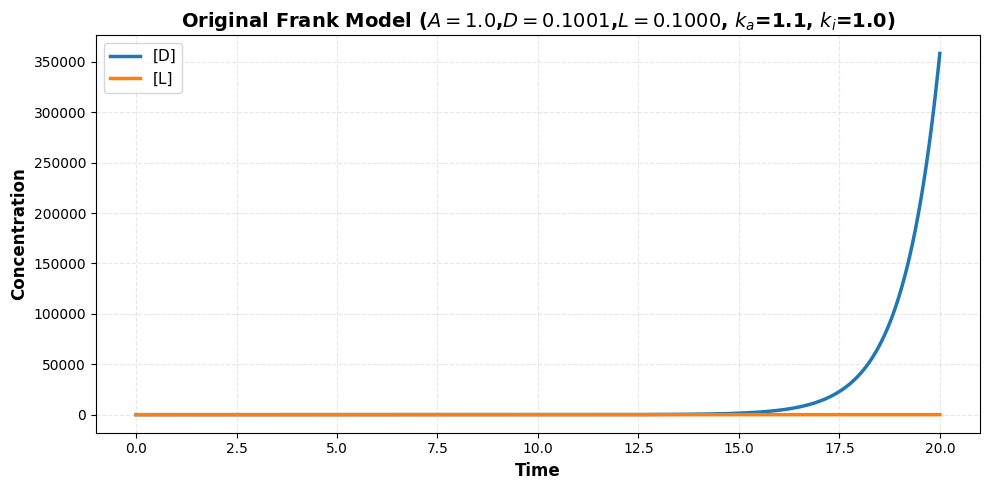

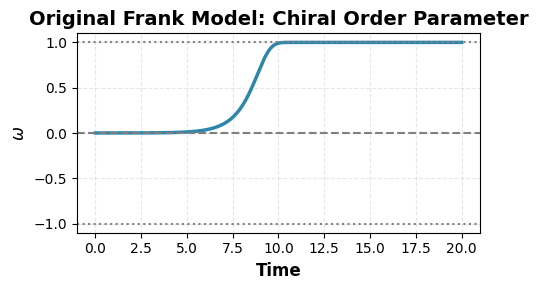

In [16]:
# ORIGINAL FRANK MODEL (1953)

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

ka = 1.1
ki = 1.0
A = 1.0              # Constant achiral precursor concentration

def frank_model(t, y):
    D, L = y

    dD = ka*A*D - ki*D*L
    dL = ka*A*L - ki*D*L

    return [dD, dL]

# Initial conditions
y0 = [0.1001, 0.1000]

t_span = (0, 20)
t_eval = np.linspace(*t_span, 2000)

sol = solve_ivp(
    frank_model,
    t_span,
    y0,
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-12
)

D, L = sol.y

omega = (D-L)/(D+L)

# ------------------------------------
# Concentration dynamics
# ------------------------------------

fig, ax = plt.subplots(figsize=(10,5), dpi=100)

ax.plot(sol.t, D,
        label='[D]',
        linewidth=2.5)

ax.plot(sol.t, L,
        label='[L]',
        linewidth=2.5)

ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration', fontsize=12, fontweight='bold')

ax.set_title(
    f"Original Frank Model ($A={A}$,$D=0.1001$,$L=0.1000$, $k_a$={ka}, $k_i$={ki})",
    fontsize=14,
    fontweight='bold'
)

ax.legend(fontsize=11)
ax.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()


# ------------------------------------
# Chiral order parameter
# ------------------------------------

fig, ax = plt.subplots(figsize=(5,3), dpi=100)

ax.plot(
    sol.t,
    omega,
    linewidth=2.5,
    color='#2E86AB'
)

ax.axhline(0,
           color='gray',
           ls='--')

ax.axhline(1,
           color='gray',
           ls=':')

ax.axhline(-1,
           color='gray',
           ls=':')

ax.set_ylim(-1.1,1.1)

ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel(r'$\omega$', fontsize=12, fontweight='bold')

ax.set_title(
    "Original Frank Model: Chiral Order Parameter",
    fontsize=14,
    fontweight='bold'
)

ax.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

## Relationship Between $\frac{dD}{dt}$, $\frac{dL}{dt}$ and $\frac{d\omega}{dt}$

The chiral order parameter is defined as

$$
\omega=\frac{D-L}{D+L}.
$$

Differentiating with respect to time using the quotient rule gives

$$
\frac{d\omega}{dt}
=
\frac{(D+L)\left(\frac{dD}{dt}-\frac{dL}{dt}\right)
-
(D-L)\left(\frac{dD}{dt}+\frac{dL}{dt}\right)}
{(D+L)^2}.
$$

Suppose the concentrations have reached a steady state,

$$
\frac{dD}{dt}=0,
\qquad
\frac{dL}{dt}=0.
$$

Substituting these into the above expression,

$$
\frac{d\omega}{dt}
=
\frac{(D+L)(0-0)-(D-L)(0+0)}
{(D+L)^2}
=
0.
$$

Hence,

$$
\boxed{
\frac{dD}{dt}=0
\ \text{and}\
\frac{dL}{dt}=0
\Longrightarrow
\frac{d\omega}{dt}=0.
}
$$

This shows that if the concentrations of both enantiomers no longer change with time, then the chiral order parameter must also remain constant.

## Why is $\frac{dA}{dt}$ not considered separately?

The modified Frank model consists of three coupled equations:

$$
\frac{dA}{dt}=2k_iDL-k_aA(D+L),
$$

$$
\frac{dD}{dt}=k_aAD-k_iDL,
$$

$$
\frac{dL}{dt}=k_aAL-k_iDL.
$$

However, the system satisfies the conservation law

$$
A+D+L=N,
$$

which implies

$$
A=N-D-L.
$$

Therefore, $A$ is **not an independent variable**—its value is uniquely determined once $D$ and $L$ are known.

Differentiating the conservation law gives

$$
\frac{dA}{dt}+\frac{dD}{dt}+\frac{dL}{dt}=0,
$$

or equivalently,

$$
\boxed{
\frac{dA}{dt}
=
-\left(\frac{dD}{dt}+\frac{dL}{dt}\right).
}
$$

Hence, if

$$
\frac{dD}{dt}=0,
\qquad
\frac{dL}{dt}=0,
$$

then it immediately follows that

$$
\boxed{
\frac{dA}{dt}=0.
}
$$

Therefore, the phase portrait only needs the variables $D$ and $L$, since the evolution of $A$ is already completely determined by the conservation law.

# Phase Space and Stability Analysis

## Phase Space

A **phase space** (or phase portrait) is a graphical representation of all possible states of a dynamical system. Unlike plots of concentration versus time, each point in phase space represents the complete state of the system at a given instant.

For Frank's model, the state of the system is completely described by the concentrations of the two enantiomers, $D$ and $L$. Thus, every point in the phase space corresponds to a unique pair of concentrations $(D,L)$.

The conservation law

$$
A+D+L=1
$$

restricts the physically accessible region of the phase space. Since concentrations cannot be negative,

$$
A=1-D-L\ge0,
$$

which implies

$$
D+L\le1.
$$

Therefore, only the triangular region bounded by the coordinate axes and the line

$$
D+L=1
$$

contains physically meaningful solutions.

---

## Vector Field

The vector field consists of arrows drawn at each point in the phase space. Each arrow represents the instantaneous rate of change of the system,

$$
\left(\frac{dD}{dt},\frac{dL}{dt}\right),
$$

indicating the direction in which the system evolves from that point. The arrows therefore provide a local description of the dynamics throughout the phase space.

---

## Trajectories

A trajectory is the path traced by the system as it evolves from a given initial condition.

Each trajectory follows the vector field and represents the solution of the governing differential equations. Different initial conditions generally produce different trajectories, but they may converge to the same equilibrium depending on the stability of the system.

---

## Equilibrium (Fixed) Points

A fixed point (or equilibrium point) is a state at which the system no longer evolves.

Mathematically,

$$
\frac{dD}{dt}=0,
\qquad
\frac{dL}{dt}=0.
$$

At these points there is no net change in either concentration, and the system remains there indefinitely unless perturbed.

---

## Why is the Racemic Equilibrium Only at $\left(\frac13,\frac13\right)$?

A racemic state simply means that the concentrations of both enantiomers are equal,

$$
D=L.
$$

This condition alone does **not** define an equilibrium. An equilibrium must also satisfy

$$
\frac{dD}{dt}=0,
\qquad
\frac{dL}{dt}=0.
$$

Substituting

$$
D=L=x
$$

into the deterministic Frank equations gives

$$
x\left[k_a(1-2x)-k_ix\right]=0.
$$

Ignoring the trivial solution $x=0$, the non-trivial racemic equilibrium is

$$
x=\frac{k_a}{2k_a+k_i}.
$$

For the parameters used in this work,

$$
k_a=k_i=1,
$$

the equilibrium becomes

$$
D=L=\frac13.
$$

Hence, although every point along the line $D=L$ is racemic, only

$$
\left(D,L\right)=\left(\frac13,\frac13\right)
$$

is a true equilibrium because it simultaneously satisfies

$$
\frac{dD}{dt}=\frac{dL}{dt}=0.
$$

---

## Stable Equilibrium

A stable equilibrium attracts nearby trajectories. If the system is perturbed slightly, the perturbation decreases with time and the trajectory returns to the equilibrium.

A useful analogy is a marble resting at the bottom of a bowl. A small displacement causes the marble to roll back to the lowest point. In the phase portrait, neighbouring trajectories converge towards a stable equilibrium.

---

## Unstable Equilibrium

An unstable equilibrium repels nearby trajectories. Although the system remains at the equilibrium if placed there exactly, any infinitesimal perturbation causes it to move away.

This is analogous to balancing a marble at the top of a hill. The marble can remain stationary only if it is perfectly balanced. Any small disturbance causes it to roll away. In the phase portrait, neighbouring trajectories diverge from an unstable equilibrium.

---

## Saddle Point

A saddle point possesses both stable and unstable directions. Perturbations along one direction decay towards the equilibrium, while perturbations along another direction grow away from it.

Consequently, some trajectories approach the equilibrium whereas others diverge. Since there is always at least one direction in which perturbations grow, saddle points are classified as unstable equilibria.

---

## Jacobian Matrix and Stability

While the phase portrait provides a graphical interpretation of stability, the rigorous mathematical classification is obtained using the Jacobian matrix.

For a two-dimensional dynamical system,

$$
\frac{dD}{dt}=f(D,L),
\qquad
\frac{dL}{dt}=g(D,L),
$$

the Jacobian is

$$
J=
\begin{bmatrix}
\dfrac{\partial f}{\partial D} & \dfrac{\partial f}{\partial L}\\[1ex]
\dfrac{\partial g}{\partial D} & \dfrac{\partial g}{\partial L}
\end{bmatrix}.
$$

The Jacobian describes how the system responds to small perturbations around an equilibrium point. Evaluating the Jacobian at each equilibrium and calculating its eigenvalues determines its local stability.

- If both eigenvalues have negative real parts, the equilibrium is **stable**.
- If both eigenvalues have positive real parts, the equilibrium is **unstable**.
- If one eigenvalue is positive and the other is negative, the equilibrium is a **saddle point**, which is always unstable.

Thus, the Jacobian provides the mathematical criterion for stability, while the phase portrait provides its graphical interpretation.

saved


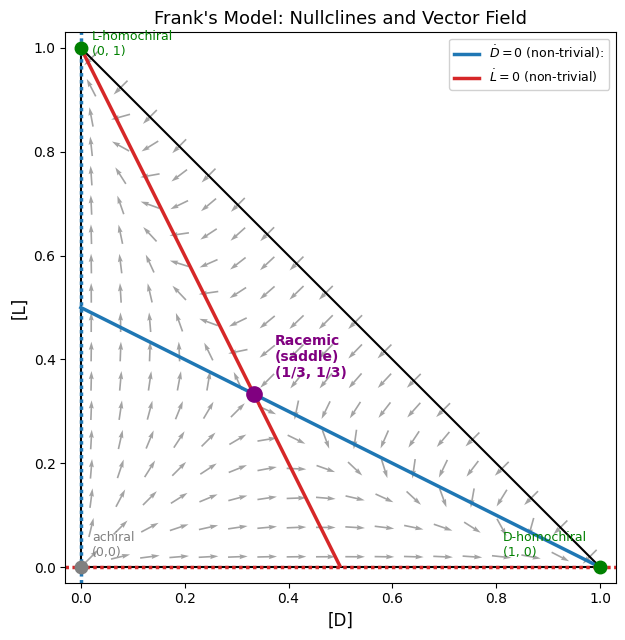

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def dD(D, L):
    return D*(1 - D - 2*L)

def dL(D, L):
    return L*(1 - 2*D - L)

fig, ax = plt.subplots(figsize=(6.5, 6.5))

# Vector field
n = 18
Dg = np.linspace(0.02, 0.98, n)
Lg = np.linspace(0.02, 0.98, n)
DD, LL = np.meshgrid(Dg, Lg)
mask = (DD + LL) <= 1.0
U = dD(DD, LL)
V = dL(DD, LL)
speed = np.sqrt(U**2 + V**2)
speed[speed == 0] = 1
Un = np.where(mask, U/speed, np.nan)
Vn = np.where(mask, V/speed, np.nan)
ax.quiver(DD, LL, Un, Vn, color='0.55', pivot='mid', scale=28, width=0.003, alpha=0.8)

# Simplex boundary
ax.plot([0,1],[1,0], 'k-', linewidth=1.5)
ax.plot([0,1],[0,0], 'k-', linewidth=1.5)
ax.plot([0,0],[0,1], 'k-', linewidth=1.5)

x = np.linspace(0, 1, 400)

# D-nullclines: D=0 (axis) and 1-D-2L=0 -> L = (1-D)/2
Dnull_L = (1 - x) / 2
valid = (Dnull_L >= 0) & (Dnull_L <= 1) & (x + Dnull_L <= 1)
ax.plot(x[valid], Dnull_L[valid], color='#1f77b4', linewidth=2.5,
        label=r'$\dot D=0$ (non-trivial):')
ax.axvline(0, color='#1f77b4', linewidth=2.5, linestyle=(0,(1,1)))

# L-nullclines: L=0 (axis) and 1-2D-L=0 -> L = 1-2D
Lnull_L = 1 - 2*x
valid2 = (Lnull_L >= 0) & (Lnull_L <= 1) & (x + Lnull_L <= 1)
ax.plot(x[valid2], Lnull_L[valid2], color='#d62728', linewidth=2.5,
        label=r'$\dot L=0$ (non-trivial)')
ax.axhline(0, color='#d62728', linewidth=2.5, linestyle=(0,(1,1)))

# Equilibria
ax.plot(1/3, 1/3, 'o', color='purple', markersize=11, zorder=5)
ax.annotate('Racemic\n(saddle)\n(1/3, 1/3)', (1/3, 1/3), textcoords="offset points",
            xytext=(15, 12), fontsize=10, color='purple', fontweight='bold')

ax.plot(1, 0, 'o', color='green', markersize=9, zorder=5)
ax.annotate('D-homochiral\n(1, 0)', (1, 0), textcoords="offset points", xytext=(-70, 8), fontsize=9, color='green')

ax.plot(0, 1, 'o', color='green', markersize=9, zorder=5)
ax.annotate('L-homochiral\n(0, 1)', (0, 1), textcoords="offset points", xytext=(8, -5), fontsize=9, color='green')

ax.plot(0, 0, 'o', color='gray', markersize=9, zorder=5)
ax.annotate('achiral\n(0,0)', (0, 0), textcoords="offset points", xytext=(8, 8), fontsize=9, color='gray')

ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel('[D]', fontsize=12)
ax.set_ylabel('[L]', fontsize=12)
ax.set_title("Frank's Model: Nullclines and Vector Field", fontsize=13)
ax.legend(loc='upper right', fontsize=9, framealpha=0.9)
ax.set_aspect('equal')

plt.tight_layout()

print("saved")

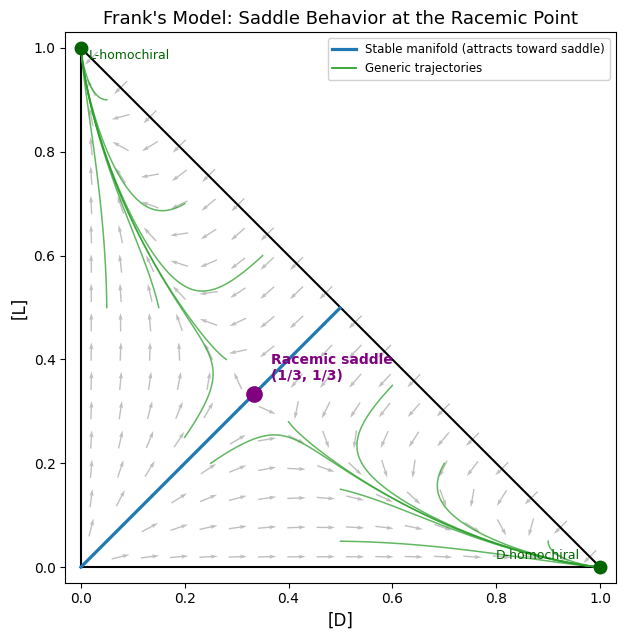

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def rhs(t, y):
    D, L = y
    return [D*(1 - D - 2*L), L*(1 - 2*D - L)]

fig, ax = plt.subplots(figsize=(6.5, 6.5))

# Vector field (background, faint)
n = 18
Dg = np.linspace(0.02, 0.98, n)
Lg = np.linspace(0.02, 0.98, n)
DD, LL = np.meshgrid(Dg, Lg)
mask = (DD + LL) <= 1.0
U = DD*(1-DD-2*LL)
V = LL*(1-2*DD-LL)
speed = np.sqrt(U**2+V**2); speed[speed==0]=1
Un = np.where(mask, U/speed, np.nan)
Vn = np.where(mask, V/speed, np.nan)
ax.quiver(DD, LL, Un, Vn, color='0.75', pivot='mid', scale=30, width=0.0025)

# simplex boundary
ax.plot([0,1],[1,0],'k-',linewidth=1.5)
ax.plot([0,1],[0,0],'k-',linewidth=1.5)
ax.plot([0,0],[0,1],'k-',linewidth=1.5)

eq = np.array([1/3, 1/3])
eps = 0.015
# unstable eigenvector (1,-1)/sqrt2, stable (1,1)/sqrt2
v_unstable = np.array([1,-1])/np.sqrt(2)
v_stable = np.array([1,1])/np.sqrt(2)

t_forward = np.linspace(0, 12, 400)
t_backward = np.linspace(0, -12, 400)

# --- Unstable manifold: integrate forward from points near eq along +/- v_unstable ---
for sign in [1, -1]:
    y0 = eq + sign*eps*v_unstable
    sol = solve_ivp(rhs, [0, 12], y0, t_eval=np.linspace(0,12,400), rtol=1e-9, atol=1e-11)

# --- Stable manifold: integrate backward from points near eq along +/- v_stable ---
for sign in [1, -1]:
    y0 = eq + sign*eps*v_stable
    sol = solve_ivp(rhs, [0, -12], y0, t_eval=np.linspace(0,-12,400), rtol=1e-9, atol=1e-11)
    # keep only points within simplex
    valid = (sol.y[0]>=-0.01)&(sol.y[1]>=-0.01)&(sol.y[0]+sol.y[1]<=1.01)
    ax.plot(sol.y[0][valid], sol.y[1][valid], color='#1f77b4', linewidth=2.3, zorder=4)

# --- A handful of generic trajectories from various starting points ---
starts = [
    (0.05,0.05),(0.9,0.05),(0.05,0.9),(0.5,0.05),(0.05,0.5),
    (0.15,0.5),(0.5,0.15),(0.6,0.35),(0.35,0.6),(0.28,0.4),(0.4,0.28),
    (0.2,0.25),(0.25,0.2),(0.7,0.2),(0.2,0.7)
]
for (D0,L0) in starts:
    sol = solve_ivp(rhs, [0, 15], [D0,L0], t_eval=np.linspace(0,15,600), rtol=1e-8, atol=1e-10)
    ax.plot(sol.y[0], sol.y[1], color='#2ca02c', linewidth=1.1, alpha=0.75)

ax.plot(1/3, 1/3, 'o', color='purple', markersize=11, zorder=6)
ax.annotate('Racemic saddle\n(1/3, 1/3)', (1/3,1/3), textcoords="offset points",
            xytext=(12,10), fontsize=10, color='purple', fontweight='bold', zorder=6)

ax.plot(1,0,'o',color='darkgreen',markersize=9, zorder=6)
ax.plot(0,1,'o',color='darkgreen',markersize=9, zorder=6)
ax.annotate('D-homochiral', (1,0), textcoords="offset points", xytext=(-75,6), fontsize=9, color='darkgreen')
ax.annotate('L-homochiral', (0,1), textcoords="offset points", xytext=(6,-8), fontsize=9, color='darkgreen')

# legend proxies
from matplotlib.lines import Line2D
legend_elems = [
    Line2D([0],[0], color='#1f77b4', lw=2.3, label='Stable manifold (attracts toward saddle)'),
    Line2D([0],[0], color='#2ca02c', lw=1.3, label='Generic trajectories'),
]
ax.legend(handles=legend_elems, loc='upper right', fontsize=8.5, framealpha=0.9)

ax.set_xlim(-0.03,1.03)
ax.set_ylim(-0.03,1.03)
ax.set_xlabel('[D]', fontsize=12)
ax.set_ylabel('[L]', fontsize=12)
ax.set_title("Frank's Model: Saddle Behavior at the Racemic Point", fontsize=13)
ax.set_aspect('equal')

plt.tight_layout()


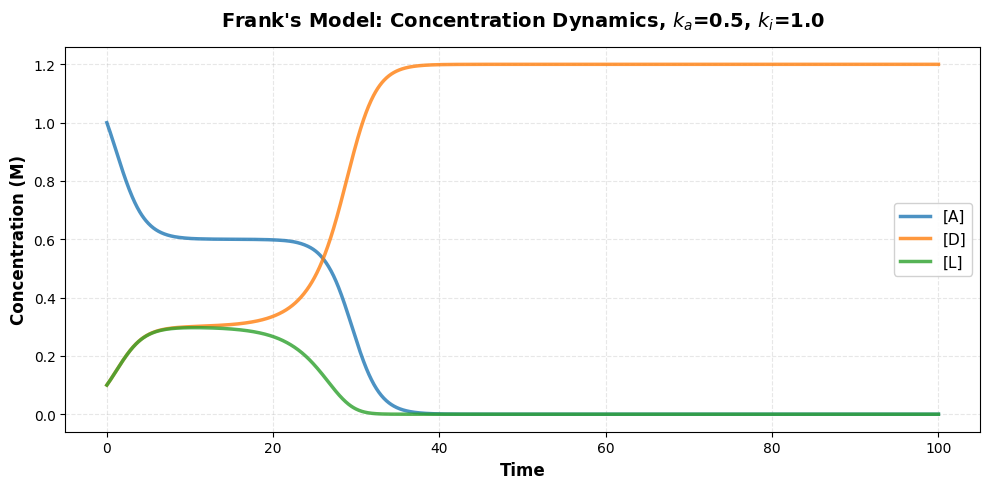

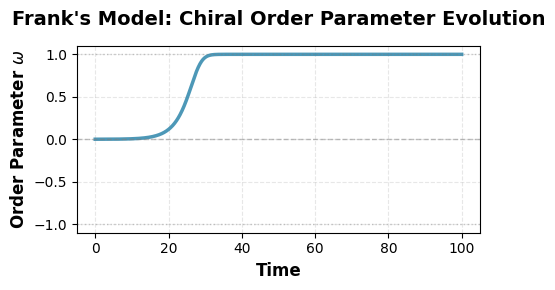

In [ ]:
#FRANKS MODEL
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

ka = 0.5
ki = 1.0

def frank_model(t, y):
    A, D, L = y

    dA = 2*ki*D*L - ka*A*(D + L)
    dD = ka*A*D - ki*D*L
    dL = ka*A*L - ki*D*L

    return [dA, dD, dL]

y0 = [1.0, 0.1001, 0.100]

t_span = (0, 100)
t_eval = np.linspace(*t_span, 2000)

sol = solve_ivp(
    frank_model,
    t_span,
    y0,
    t_eval=t_eval
)

A, D, L = sol.y

omega = (D - L)/(D + L)

# Concentration dynamics plot
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
ax.plot(sol.t, A, label='[A]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, D, label='[D]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, L, label='[L]', linewidth=2.5, alpha=0.8)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration (M)', fontsize=12, fontweight='bold')
ax.set_title(f"Frank's Model: Concentration Dynamics, $k_a$={ka}, $k_i$={ki}", fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

# Chiral order parameter plot
fig, ax = plt.subplots(figsize=(5, 3), dpi=100) 
ax.plot(sol.t, omega, linewidth=2.5, color='#2E86AB', alpha=0.85)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Racemic state')
ax.axhline(y=1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.axhline(y=-1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel(r'Order Parameter $\omega$', fontsize=12, fontweight='bold')
ax.set_title('Frank\'s Model: Chiral Order Parameter Evolution', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(-1.1, 1.1)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

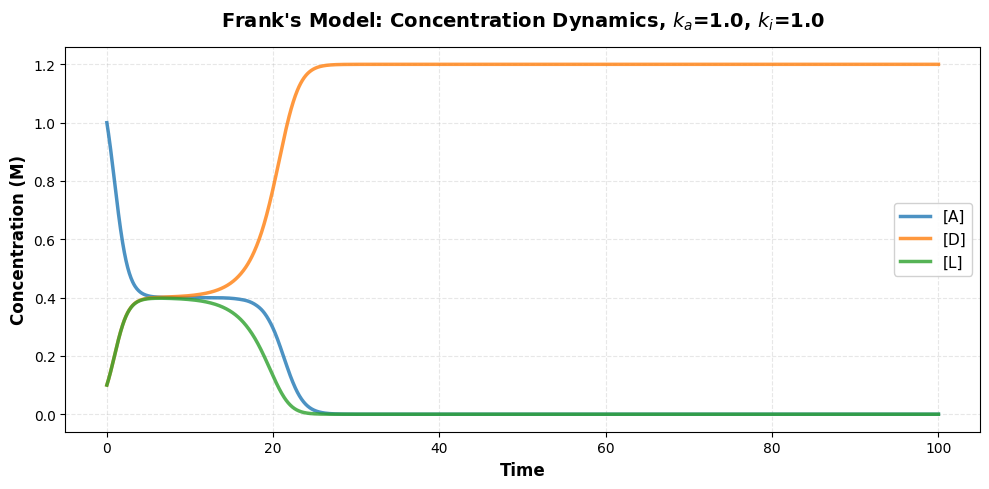

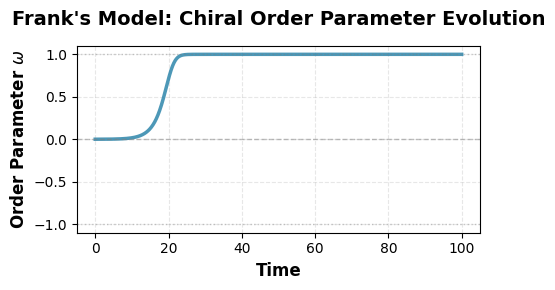

In [16]:
#FRANKS MODEL
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

ka = 1.0
ki = 1.0

def frank_model(t, y):
    A, D, L = y

    dA = 2*ki*D*L - ka*A*(D + L)
    dD = ka*A*D - ki*D*L
    dL = ka*A*L - ki*D*L

    return [dA, dD, dL]

y0 = [1.0, 0.1001, 0.100]

t_span = (0, 100)
t_eval = np.linspace(*t_span, 2000)

sol = solve_ivp(
    frank_model,
    t_span,
    y0,
    t_eval=t_eval
)

A, D, L = sol.y

omega = (D - L)/(D + L)

# Concentration dynamics plot
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
ax.plot(sol.t, A, label='[A]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, D, label='[D]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, L, label='[L]', linewidth=2.5, alpha=0.8)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration (M)', fontsize=12, fontweight='bold')
ax.set_title(f"Frank's Model: Concentration Dynamics, $k_a$={ka}, $k_i$={ki}", fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

# Chiral order parameter plot
fig, ax = plt.subplots(figsize=(5, 3), dpi=100) 
ax.plot(sol.t, omega, linewidth=2.5, color='#2E86AB', alpha=0.85)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Racemic state')
ax.axhline(y=1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.axhline(y=-1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel(r'Order Parameter $\omega$', fontsize=12, fontweight='bold')
ax.set_title('Frank\'s Model: Chiral Order Parameter Evolution', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(-1.1, 1.1)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

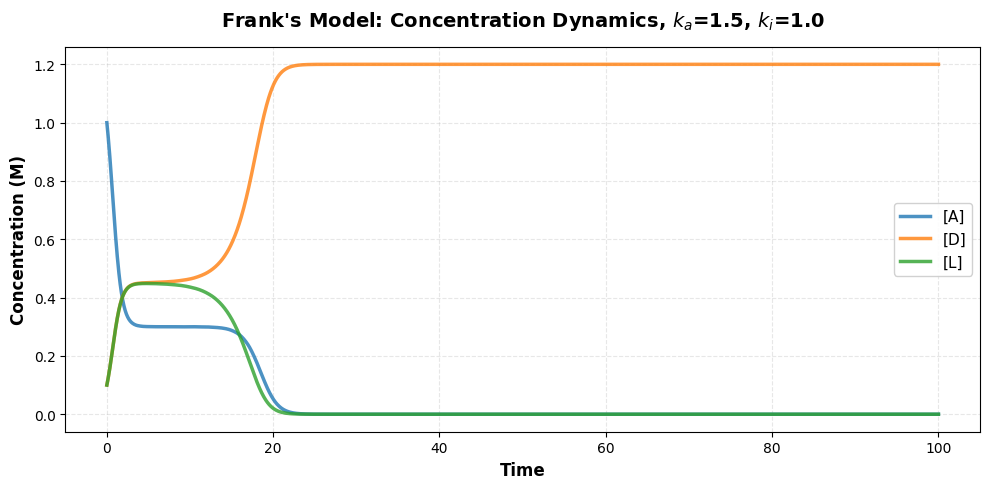

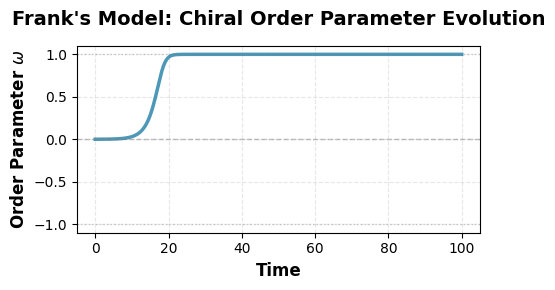

In [ ]:
#FRANKS MODEL
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

ka = 1.5
ki = 1.0

def frank_model(t, y):
    A, D, L = y

    dA = 2*ki*D*L - ka*A*(D + L)
    dD = ka*A*D - ki*D*L
    dL = ka*A*L - ki*D*L

    return [dA, dD, dL]

y0 = [1.0, 0.1001, 0.100]

t_span = (0, 100)
t_eval = np.linspace(*t_span, 2000)

sol = solve_ivp(
    frank_model,
    t_span,
    y0,
    t_eval=t_eval
)

A, D, L = sol.y

omega = (D - L)/(D + L)

# Concentration dynamics plot
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
ax.plot(sol.t, A, label='[A]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, D, label='[D]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, L, label='[L]', linewidth=2.5, alpha=0.8)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration (M)', fontsize=12, fontweight='bold')
ax.set_title(f"Frank's Model: Concentration Dynamics, $k_a$={ka}, $k_i$={ki}", fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

# Chiral order parameter plot
fig, ax = plt.subplots(figsize=(5, 3), dpi=100) 
ax.plot(sol.t, omega, linewidth=2.5, color='#2E86AB', alpha=0.85)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Racemic state')
ax.axhline(y=1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.axhline(y=-1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel(r'Order Parameter $\omega$', fontsize=12, fontweight='bold')
ax.set_title('Frank\'s Model: Chiral Order Parameter Evolution', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(-1.1, 1.1)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

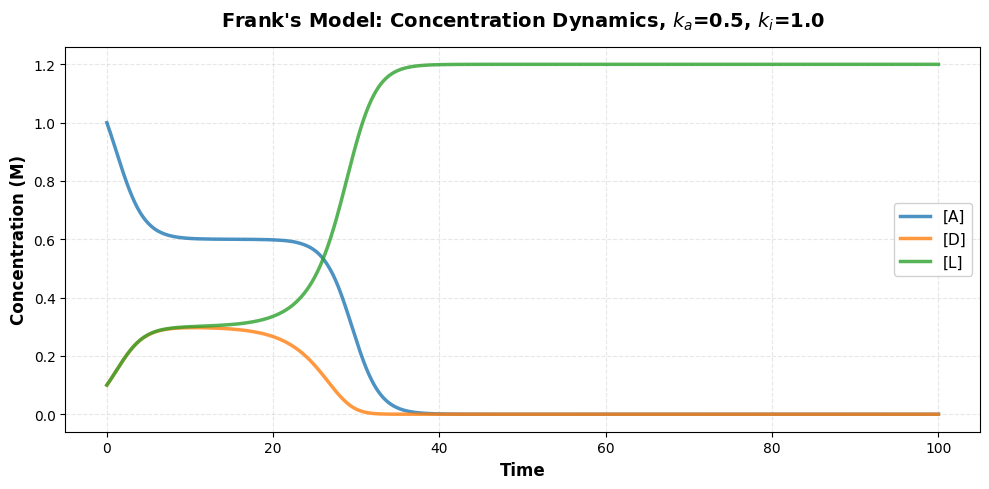

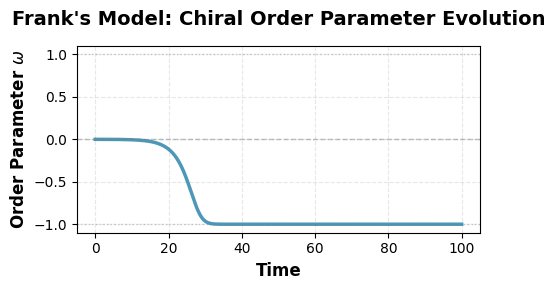

In [19]:
#FRANKS MODEL
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

ka = 0.5
ki = 1.0

def frank_model(t, y):
    A, D, L = y

    dA = 2*ki*D*L - ka*A*(D + L)
    dD = ka*A*D - ki*D*L
    dL = ka*A*L - ki*D*L

    return [dA, dD, dL]

y0 = [1.0, 0.100, 0.1001]

t_span = (0, 100)
t_eval = np.linspace(*t_span, 2000)

sol = solve_ivp(
    frank_model,
    t_span,
    y0,
    t_eval=t_eval
)

A, D, L = sol.y

omega = (D - L)/(D + L)

# Concentration dynamics plot
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
ax.plot(sol.t, A, label='[A]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, D, label='[D]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, L, label='[L]', linewidth=2.5, alpha=0.8)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration (M)', fontsize=12, fontweight='bold')
ax.set_title(f"Frank's Model: Concentration Dynamics, $k_a$={ka}, $k_i$={ki}", fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

# Chiral order parameter plot
fig, ax = plt.subplots(figsize=(5, 3), dpi=100) 
ax.plot(sol.t, omega, linewidth=2.5, color='#2E86AB', alpha=0.85)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Racemic state')
ax.axhline(y=1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.axhline(y=-1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel(r'Order Parameter $\omega$', fontsize=12, fontweight='bold')
ax.set_title('Frank\'s Model: Chiral Order Parameter Evolution', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(-1.1, 1.1)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

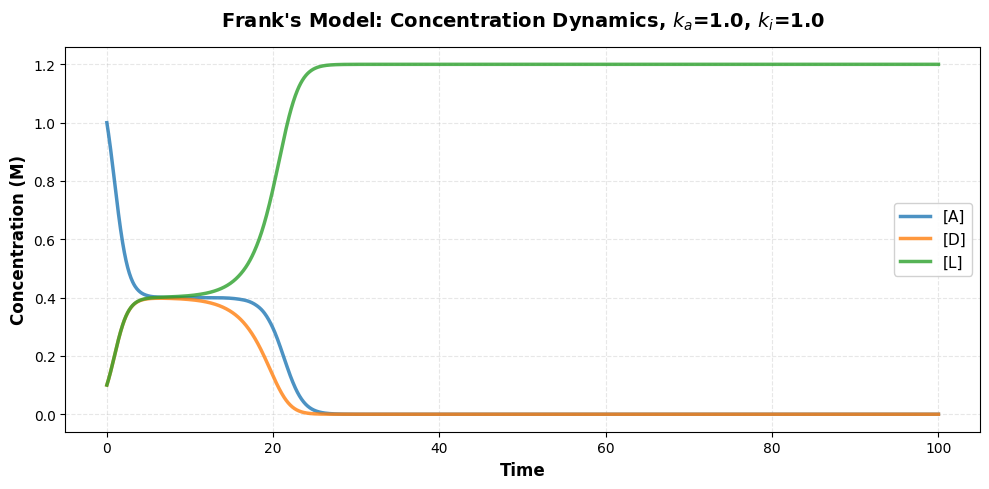

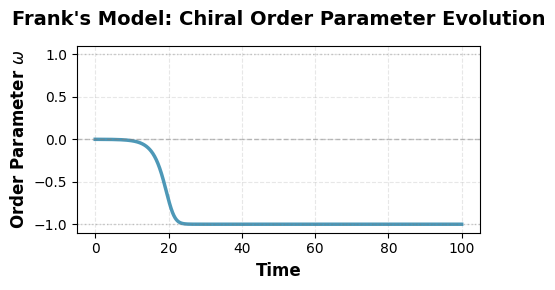

In [20]:
#FRANKS MODEL
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

ka = 1.0
ki = 1.0

def frank_model(t, y):
    A, D, L = y

    dA = 2*ki*D*L - ka*A*(D + L)
    dD = ka*A*D - ki*D*L
    dL = ka*A*L - ki*D*L

    return [dA, dD, dL]

y0 = [1.0, 0.100, 0.1001]

t_span = (0, 100)
t_eval = np.linspace(*t_span, 2000)

sol = solve_ivp(
    frank_model,
    t_span,
    y0,
    t_eval=t_eval
)

A, D, L = sol.y

omega = (D - L)/(D + L)

# Concentration dynamics plot
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
ax.plot(sol.t, A, label='[A]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, D, label='[D]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, L, label='[L]', linewidth=2.5, alpha=0.8)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration (M)', fontsize=12, fontweight='bold')
ax.set_title(f"Frank's Model: Concentration Dynamics, $k_a$={ka}, $k_i$={ki}", fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

# Chiral order parameter plot
fig, ax = plt.subplots(figsize=(5, 3), dpi=100) 
ax.plot(sol.t, omega, linewidth=2.5, color='#2E86AB', alpha=0.85)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Racemic state')
ax.axhline(y=1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.axhline(y=-1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel(r'Order Parameter $\omega$', fontsize=12, fontweight='bold')
ax.set_title('Frank\'s Model: Chiral Order Parameter Evolution', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(-1.1, 1.1)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

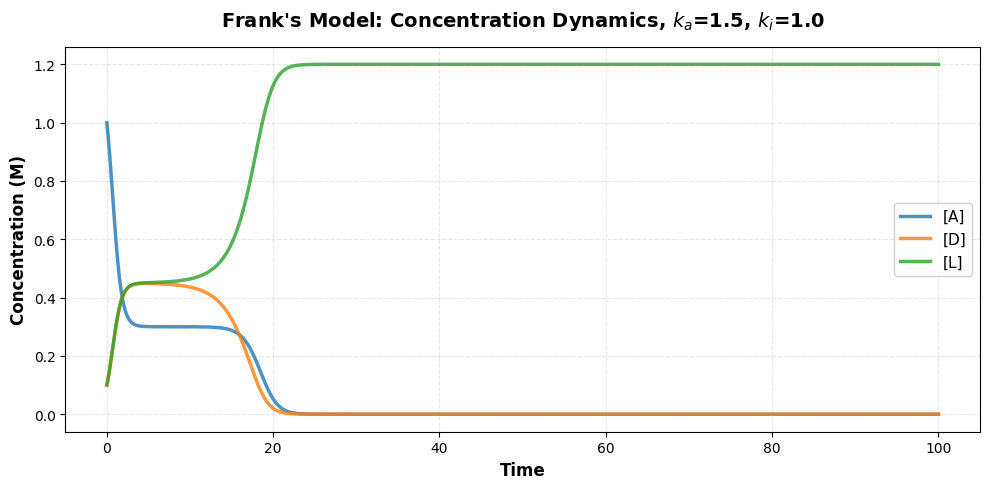

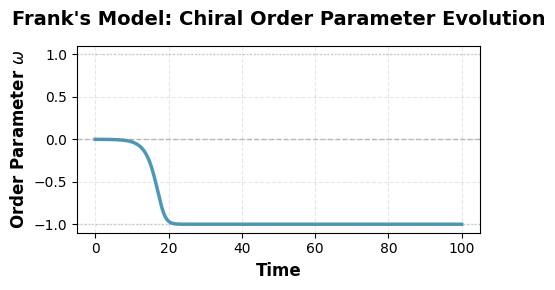

[1.00000000e-01 1.07177616e-01 1.14701474e-01 ... 6.53618784e-34
 6.23612124e-34 5.90220870e-34]
[0.1001     0.10728535 0.11481741 ... 1.20010038 1.20010038 1.20010036]


In [ ]:
#FRANKS MODEL
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

ka = 1.5
ki = 1.0

def frank_model(t, y):
    A, D, L = y

    dA = 2*ki*D*L - ka*A*(D + L)
    dD = ka*A*D - ki*D*L
    dL = ka*A*L - ki*D*L

    return [dA, dD, dL]

y0 = [1.0, 0.100, 0.1001]

t_span = (0, 100)
t_eval = np.linspace(*t_span, 2000)

sol = solve_ivp(
    frank_model,
    t_span,
    y0,
    t_eval=t_eval
)

A, D, L = sol.y

omega = (D - L)/(D + L)

# Concentration dynamics plot
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
ax.plot(sol.t, A, label='[A]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, D, label='[D]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, L, label='[L]', linewidth=2.5, alpha=0.8)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration (M)', fontsize=12, fontweight='bold')
ax.set_title(f"Frank's Model: Concentration Dynamics, $k_a$={ka}, $k_i$={ki}", fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

# Chiral order parameter plot
fig, ax = plt.subplots(figsize=(5, 3), dpi=100) 
ax.plot(sol.t, omega, linewidth=2.5, color='#2E86AB', alpha=0.85)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Racemic state')
ax.axhline(y=1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.axhline(y=-1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel(r'Order Parameter $\omega$', fontsize=12, fontweight='bold')
ax.set_title('Frank\'s Model: Chiral Order Parameter Evolution', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(-1.1, 1.1)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()


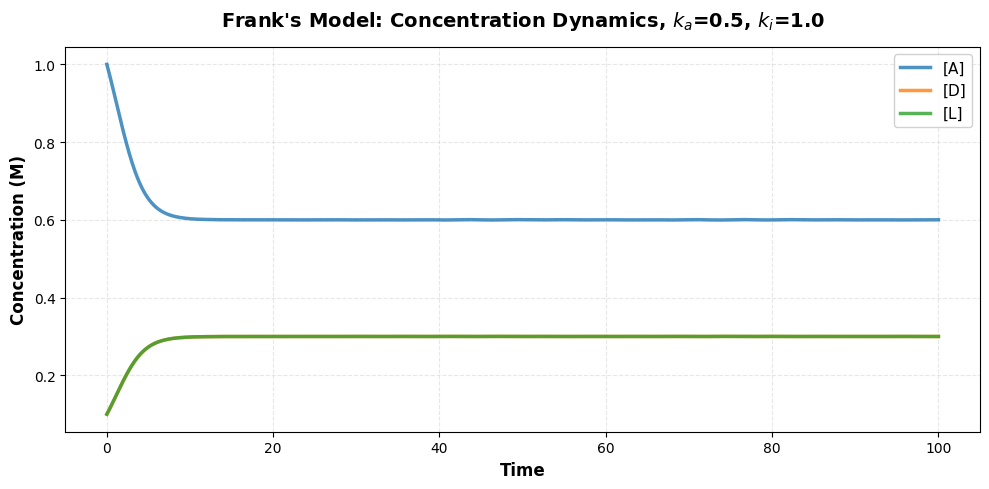

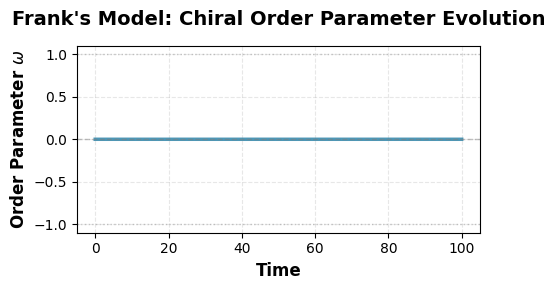

In [155]:
#FRANKS MODEL
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

ka = 0.5
ki = 1.0

def frank_model(t, y):
    A, D, L = y

    dA = 2*ki*D*L - ka*A*(D + L)
    dD = ka*A*D - ki*D*L
    dL = ka*A*L - ki*D*L

    return [dA, dD, dL]

y0 = [1.0, 0.100, 0.100]

t_span = (0, 100)
t_eval = np.linspace(*t_span, 2000)

sol = solve_ivp(
    frank_model,
    t_span,
    y0,
    t_eval=t_eval
)

A, D, L = sol.y

omega = (D - L)/(D + L)

# Concentration dynamics plot
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
ax.plot(sol.t, A, label='[A]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, D, label='[D]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, L, label='[L]', linewidth=2.5, alpha=0.8)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration (M)', fontsize=12, fontweight='bold')
ax.set_title(f"Frank's Model: Concentration Dynamics, $k_a$={ka}, $k_i$={ki}", fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

# Chiral order parameter plot
fig, ax = plt.subplots(figsize=(5, 3), dpi=100) 
ax.plot(sol.t, omega, linewidth=2.5, color='#2E86AB', alpha=0.85)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Racemic state')
ax.axhline(y=1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.axhline(y=-1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel(r'Order Parameter $\omega$', fontsize=12, fontweight='bold')
ax.set_title('Frank\'s Model: Chiral Order Parameter Evolution', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(-1.1, 1.1)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

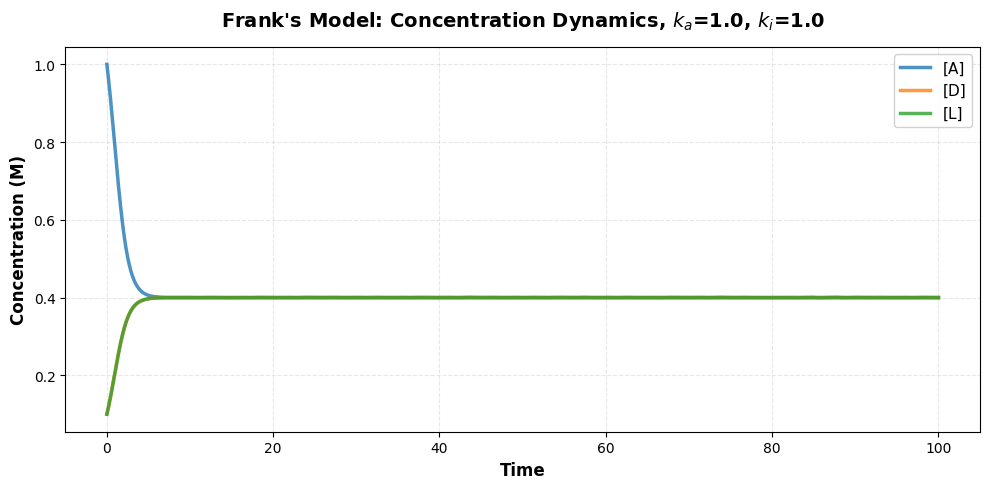

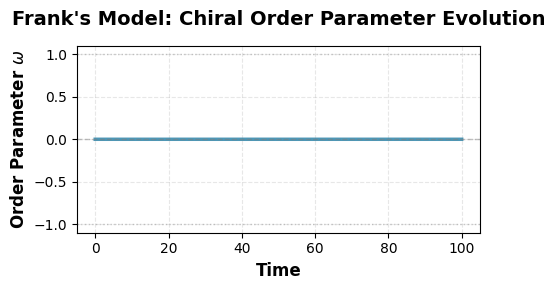

In [23]:
#FRANKS MODEL
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

ka = 1.0
ki = 1.0

def frank_model(t, y):
    A, D, L = y

    dA = 2*ki*D*L - ka*A*(D + L)
    dD = ka*A*D - ki*D*L
    dL = ka*A*L - ki*D*L

    return [dA, dD, dL]

y0 = [1.0, 0.100, 0.100]

t_span = (0, 100)
t_eval = np.linspace(*t_span, 2000)

sol = solve_ivp(
    frank_model,
    t_span,
    y0,
    t_eval=t_eval
)

A, D, L = sol.y

omega = (D - L)/(D + L)

# Concentration dynamics plot
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
ax.plot(sol.t, A, label='[A]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, D, label='[D]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, L, label='[L]', linewidth=2.5, alpha=0.8)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration (M)', fontsize=12, fontweight='bold')
ax.set_title(f"Frank's Model: Concentration Dynamics, $k_a$={ka}, $k_i$={ki}", fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

# Chiral order parameter plot
fig, ax = plt.subplots(figsize=(5, 3), dpi=100) 
ax.plot(sol.t, omega, linewidth=2.5, color='#2E86AB', alpha=0.85)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Racemic state')
ax.axhline(y=1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.axhline(y=-1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel(r'Order Parameter $\omega$', fontsize=12, fontweight='bold')
ax.set_title('Frank\'s Model: Chiral Order Parameter Evolution', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(-1.1, 1.1)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

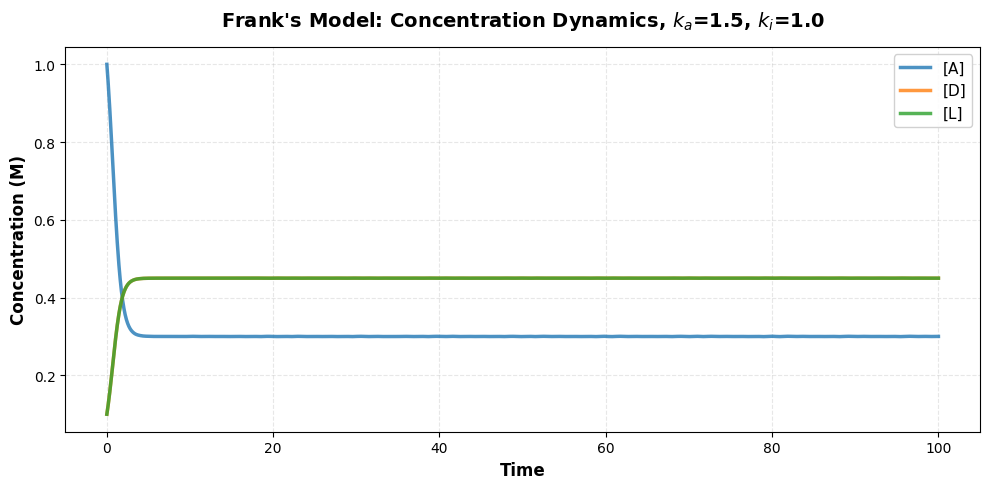

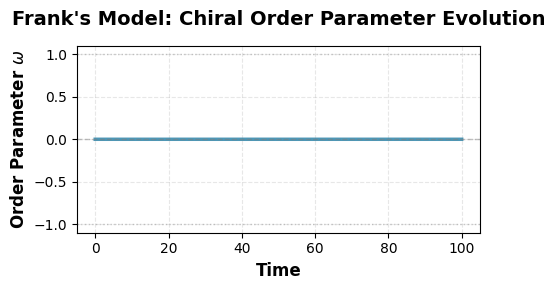

In [24]:
#FRANKS MODEL
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

ka = 1.5
ki = 1.0

def frank_model(t, y):
    A, D, L = y

    dA = 2*ki*D*L - ka*A*(D + L)
    dD = ka*A*D - ki*D*L
    dL = ka*A*L - ki*D*L

    return [dA, dD, dL]

y0 = [1.0, 0.100, 0.100]

t_span = (0, 100)
t_eval = np.linspace(*t_span, 2000)

sol = solve_ivp(
    frank_model,
    t_span,
    y0,
    t_eval=t_eval
)

A, D, L = sol.y

omega = (D - L)/(D + L)

# Concentration dynamics plot
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
ax.plot(sol.t, A, label='[A]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, D, label='[D]', linewidth=2.5, alpha=0.8)
ax.plot(sol.t, L, label='[L]', linewidth=2.5, alpha=0.8)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration (M)', fontsize=12, fontweight='bold')
ax.set_title(f"Frank's Model: Concentration Dynamics, $k_a$={ka}, $k_i$={ki}", fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

# Chiral order parameter plot
fig, ax = plt.subplots(figsize=(5, 3), dpi=100) 
ax.plot(sol.t, omega, linewidth=2.5, color='#2E86AB', alpha=0.85)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Racemic state')
ax.axhline(y=1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.axhline(y=-1, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel(r'Order Parameter $\omega$', fontsize=12, fontweight='bold')
ax.set_title('Frank\'s Model: Chiral Order Parameter Evolution', fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(-1.1, 1.1)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()

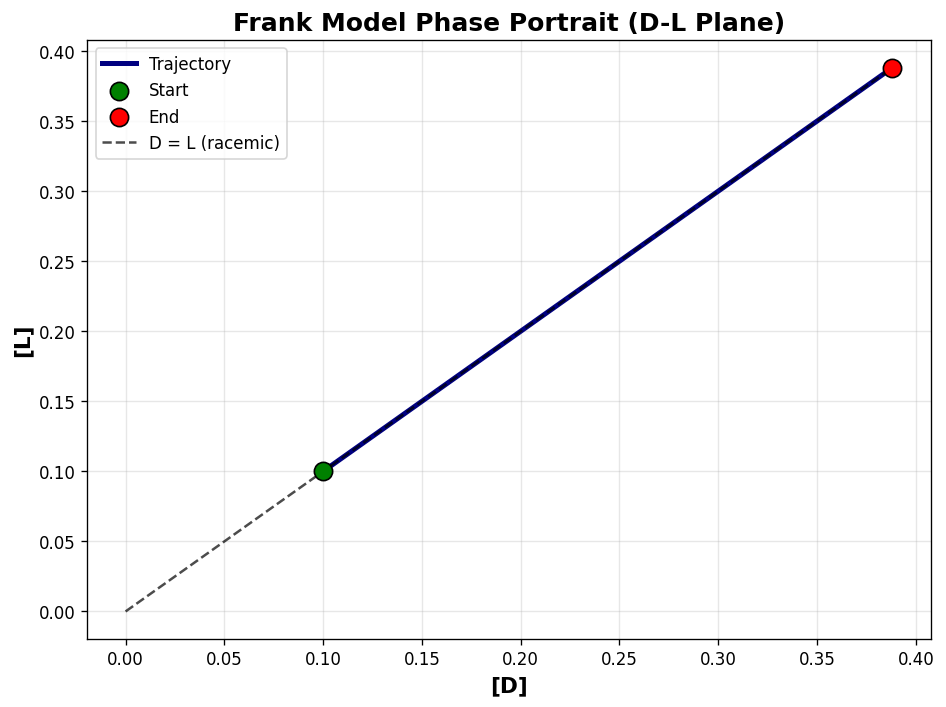

In [13]:
# ===============================
# D-L PHASE SPACE
# ===============================

fig, ax = plt.subplots(figsize=(8,6), dpi=120)

# trajectory
ax.plot(D, L,
        linewidth=3,
        color='navy',
        label='Trajectory')

# start point
ax.scatter(D[0], L[0],
           s=120,
           color='green',
           edgecolor='black',
           zorder=5,
           label='Start')

# end point
ax.scatter(D[-1], L[-1],
           s=120,
           color='red',
           edgecolor='black',
           zorder=5,
           label='End')

# racemic line
max_val = max(np.max(D), np.max(L))
ax.plot([0,max_val],
        [0,max_val],
        '--',
        color='black',
        alpha=0.7,
        label='D = L (racemic)')

ax.set_xlabel('[D]', fontsize=13, fontweight='bold')
ax.set_ylabel('[L]', fontsize=13, fontweight='bold')

ax.set_title("Frank Model Phase Portrait (D-L Plane)",
             fontsize=15,
             fontweight='bold')

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Gillespie Simulation for Frank Model Single Trajectory


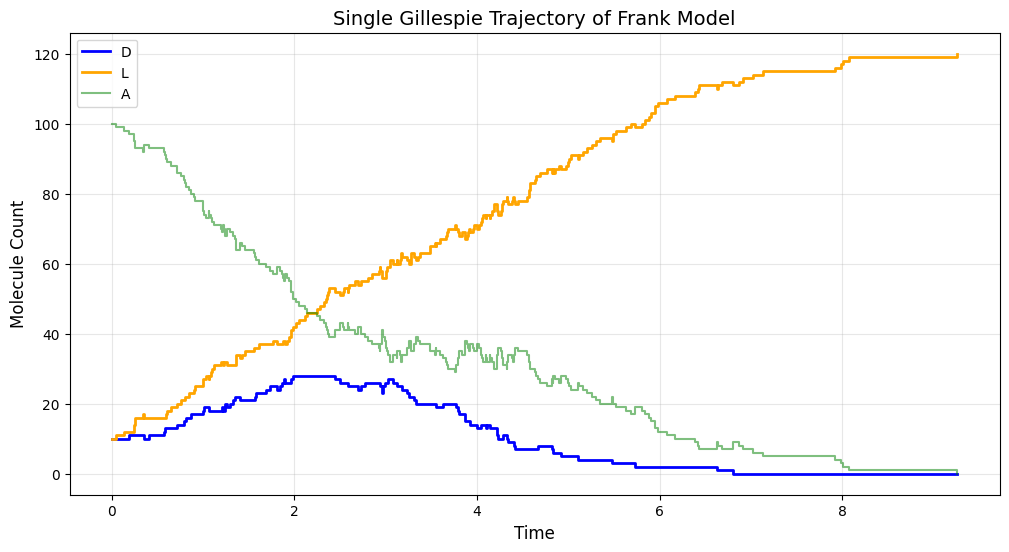

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random

# -----------------------------
# Parameters
# -----------------------------
ka = 1.0
ki = 1.0
mt = 100

# -----------------------------
# Gillespie SSA
# -----------------------------
def rxn(Vol,A_init, D_init, L_init, ka, ki, mt):

    A = A_init
    D = D_init
    L = L_init

    t = 0.0

    # Store trajectory
    times = [0.0]
    A_hist = [A]
    D_hist = [D]
    L_hist = [L]

    while t < mt:

        # Propensities
        a1 = (ka * A * D)/Vol
        a2 = (ka * A * L)/Vol
        a3 = (ki * D * L)/Vol
        a0 = a1 + a2 + a3

        # Stop if no more reactions are possible
        if a0 == 0:
            break

        # Waiting time
        r1 = random.random()
        tau = -math.log(r1) / a0
        t += tau

        if t > mt:
            break

        # Choose reaction
        r2 = random.random() * a0

        if r2 <= a1:
            # A + D -> 2D
            A -= 1
            D += 1

        elif r2 <= a1 + a2:
            # A + L -> 2L
            A -= 1
            L += 1

        else:
            # D + L -> 2A
            D -= 1
            L -= 1
            A += 2

        # Store every reaction event
        times.append(t)
        A_hist.append(A)
        D_hist.append(D)
        L_hist.append(L)

    return np.array(times), np.array(A_hist), np.array(D_hist), np.array(L_hist)

# -----------------------------
# Run one trajectory
# -----------------------------
times, A, D, L = rxn(
    Vol=100,
    A_init=100,
    D_init=10,
    L_init=10,
    ka=ka,
    ki=ki,
    mt=mt
)

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(12,6))

plt.step(times, D, where='post', label='D', color='blue', linewidth=2)
plt.step(times, L, where='post', label='L', color='orange', linewidth=2)
plt.step(times, A, where='post', label='A', color='green', alpha=0.5)

plt.xlabel("Time", fontsize=12)
plt.ylabel("Molecule Count", fontsize=12)
plt.title("Single Gillespie Trajectory of Frank Model", fontsize=14)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

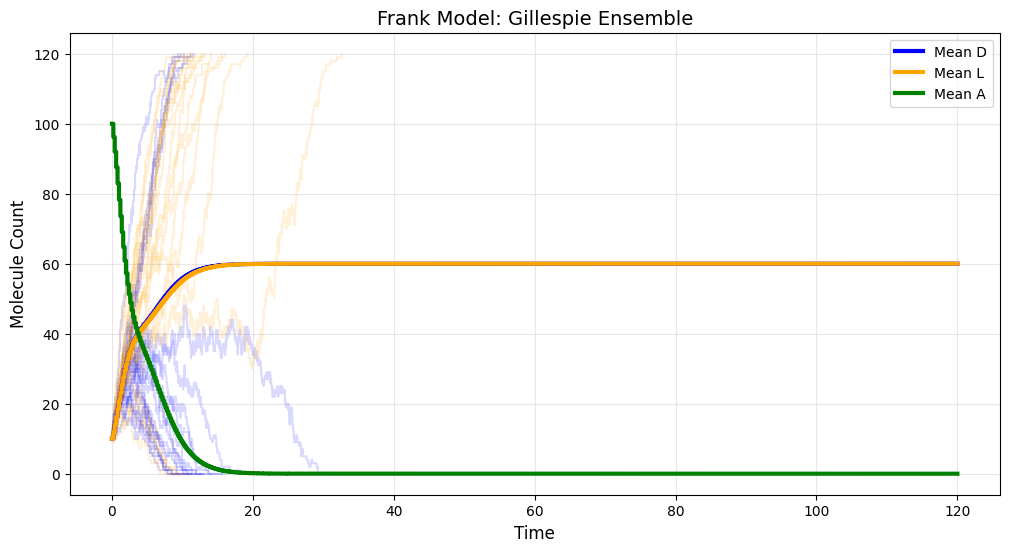

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random

# -----------------------------
# Parameters
# -----------------------------

ka = 1.0
ki = 1.0
Vol = 100

A0 = 100
D0 = 10
L0 = 10

mt = 120
dt = 0.2

meantime = np.arange(0, mt + dt, dt)

ntraj = 10000

concA = np.zeros((ntraj, len(meantime)))
concD = np.zeros((ntraj, len(meantime)))
concL = np.zeros((ntraj, len(meantime)))

# -----------------------------
# Gillespie SSA
# -----------------------------

def frank(Vol, A, D, L, ka, ki, i, concA, concD, concL):

    concA[i,0] = A
    concD[i,0] = D
    concL[i,0] = L

    t = 0.0
    j = 0

    times = [0.0]
    countA = [A]
    countD = [D]
    countL = [L]

    while True:

        if t >= mt:
            break

        # -----------------------------
        # Propensities
        # -----------------------------

        a1 = ka*A*D/Vol
        a2 = ka*A*L/Vol
        a3 = ki*D*L/Vol

        a0 = a1 + a2 + a3

        if a0 == 0:
            break

        # -----------------------------
        # Waiting time
        # -----------------------------

        r1 = random.random()
        tau = (1/a0) * math.log(1/r1)

        t += tau

        # -----------------------------
        # Record state on fixed grid
        # -----------------------------

        while j < len(meantime)-1 and meantime[j+1] <= t:

            j += 1

            concA[i,j] = A
            concD[i,j] = D
            concL[i,j] = L

        # -----------------------------
        # Choose reaction
        # -----------------------------

        r2 = random.random() * a0

        if r2 <= a1:

            # A + D -> 2D
            A -= 1
            D += 1

        elif r2 <= a1 + a2:

            # A + L -> 2L
            A -= 1
            L += 1

        else:

            # D + L -> 2A
            D -= 1
            L -= 1
            A += 2

        times.append(t)
        countA.append(A)
        countD.append(D)
        countL.append(L)

    # -----------------------------
    # Fill remaining observation times
    # -----------------------------

    while j < len(meantime)-1:

        j += 1

        concA[i,j] = A
        concD[i,j] = D
        concL[i,j] = L

    return countA, countD, countL, times

# -----------------------------
# Plot
# -----------------------------

plt.figure(figsize=(12,6))

for i in range(ntraj):

    countA, countD, countL, times = frank(
        Vol,
        A0,
        D0,
        L0,
        ka,
        ki,
        i,
        concA,
        concD,
        concL
    )

    if i < 20:

        plt.step(
            times,
            countD,
            where='post',
            color='blue',
            alpha=0.15
        )

        plt.step(
            times,
            countL,
            where='post',
            color='orange',
            alpha=0.15
        )

# -----------------------------
# Ensemble means
# -----------------------------

meanA = np.mean(concA, axis=0)
meanD = np.mean(concD, axis=0)
meanL = np.mean(concL, axis=0)

plt.step(
    meantime,
    meanD,
    where='post',
    color='blue',
    linewidth=3,
    label='Mean D'
)

plt.step(
    meantime,
    meanL,
    where='post',
    color='orange',
    linewidth=3,
    label='Mean L'
)

plt.step(
    meantime,
    meanA,
    where='post',
    color='green',
    linewidth=3,
    label='Mean A'
)

plt.xlabel("Time", fontsize=12)
plt.ylabel("Molecule Count", fontsize=12)
plt.title("Frank Model: Gillespie Ensemble", fontsize=14)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

Gillespie Simulation For Frank model with multiple trajectories


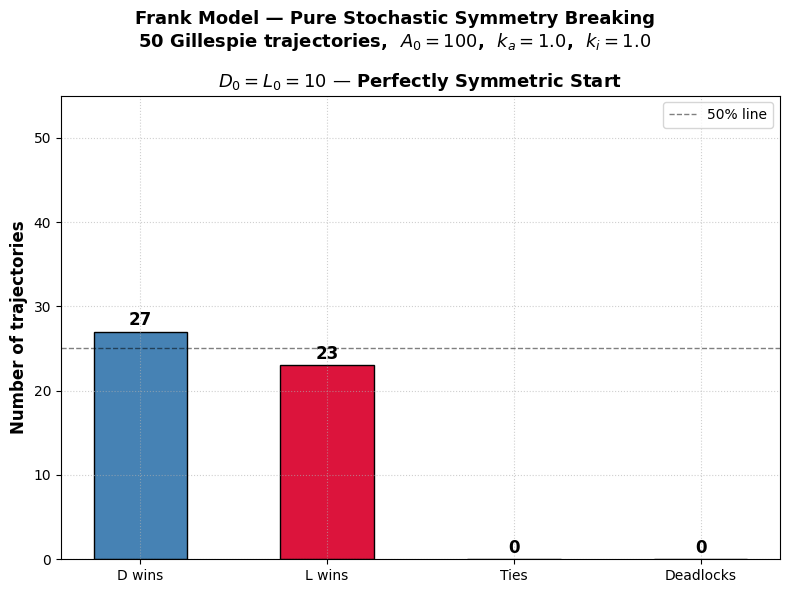

D wins=27, L wins=23, Ties=0, Deadlocks=0


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random
from numba import njit

ka = 1.0
ki = 1.0
mt = 100
dt = 0.2

@njit
def rxn(A_init, D_init, L_init, ka, ki, mt, dt, conc_A, conc_D, conc_L, idx):
    A = A_init
    D_sp = D_init
    L_sp = L_init

    a1 = ka * A * D_sp
    a2 = ka * A * L_sp
    a3 = ki * D_sp * L_sp
    a0 = a1 + a2 + a3

    t = 0.0
    t2 = 0.0
    j = 0

    conc_A[idx, 0] = A
    conc_D[idx, 0] = D_sp
    conc_L[idx, 0] = L_sp

    while True:
        if t >= mt or t2 >= mt or a0 == 0:
            while j + 1 < conc_A.shape[1]:
                j += 1
                conc_A[idx, j] = A
                conc_D[idx, j] = D_sp
                conc_L[idx, j] = L_sp
            break

        r1 = random.random()
        tau = (1.0 / a0) * math.log(1.0 / r1)
        t += tau

        r2 = random.random()

        while (t2 + dt) <= t and (t2 + dt) <= mt:
            j += 1
            t2 += dt
            if j >= conc_A.shape[1]:
                break
            conc_A[idx, j] = A
            conc_D[idx, j] = D_sp
            conc_L[idx, j] = L_sp

        if j >= conc_A.shape[1]:
            break

        if (r2 * a0) <= a1:
            A = A - 1
            D_sp = D_sp + 1
        elif (r2 * a0) <= (a1 + a2):
            A = A - 1
            L_sp = L_sp + 1
        else:
            D_sp = D_sp - 1
            L_sp = L_sp - 1
            A = A + 2

        a1 = ka * A * D_sp
        a2 = ka * A * L_sp
        a3 = ki * D_sp * L_sp
        a0 = a1 + a2 + a3

meantime = np.arange(0, 100.001, 0.2)
n_steps  = len(meantime)
n_sims   = 50

# ── Equal D=L=10 ──────────────────────────────────────────────────────────────
conc_A = np.zeros((n_sims, n_steps))
conc_D = np.zeros((n_sims, n_steps))
conc_L = np.zeros((n_sims, n_steps))

for i in range(n_sims):
    rxn(100, 10, 10, ka, ki, mt, dt, conc_A, conc_D, conc_L, i)

# ── Winner counting ───────────────────────────────────────────────────────────
final_D = conc_D[:, -1]
final_L = conc_L[:, -1]

D_wins    = int(np.sum(final_D > final_L))
L_wins    = int(np.sum(final_L > final_D))
deadlocks = int(np.sum((final_D == 0) & (final_L == 0)))
ties      = int(np.sum((final_D == final_L) & (final_D != 0)))

# ── Plot ──────────────────────────────────────────────────────────────────────
categories = ['D wins', 'L wins', 'Ties', 'Deadlocks']
colors     = ['steelblue', 'crimson', 'gray', 'black']
counts     = [D_wins, L_wins, ties, deadlocks]

fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(categories, counts, color=colors, edgecolor='black', width=0.5)
ax.set_title('$D_0 = L_0 = 10$ — Perfectly Symmetric Start',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Number of trajectories', fontsize=12, fontweight='bold')
ax.set_ylim(0, n_sims + 5)
ax.axhline(n_sims / 2, color='black', linestyle='--',
           linewidth=1, alpha=0.5, label='50% line')
ax.legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')
ax.grid(True, linestyle=':', alpha=0.6)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
            str(count), ha='center', fontsize=12, fontweight='bold')

plt.suptitle("Frank Model — Pure Stochastic Symmetry Breaking\n"
             "50 Gillespie trajectories,  $A_0=100$,  $k_a=1.0$,  $k_i=1.0$",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"D wins={D_wins}, L wins={L_wins}, Ties={ties}, Deadlocks={deadlocks}")

Running simulations...


C:\Users\tojo\AppData\Local\Temp\ipykernel_7208\4092429654.py:164: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', fontsize=9, frameon=True, facecolor='white')


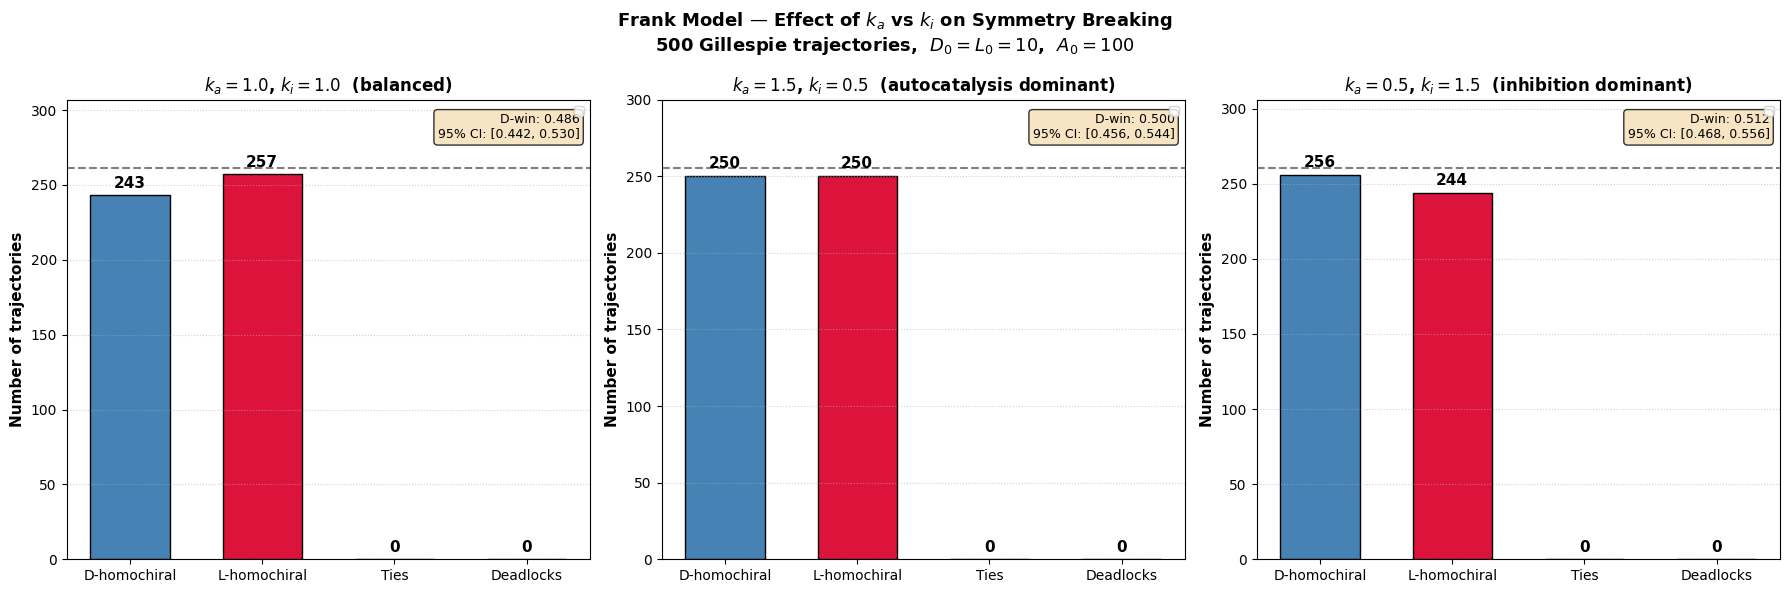


STATISTICAL SUMMARY (500 trajectories per regime)

$k_a=1.0$, $k_i=1.0$  (balanced)
  D-homochiral: 243
  L-homochiral: 257
  Ties: 0
  Deadlocks: 0
  ---
  D-win fraction: 0.4860
  95% CI: [0.4425, 0.5297]

$k_a=1.5$, $k_i=0.5$  (autocatalysis dominant)
  D-homochiral: 250
  L-homochiral: 250
  Ties: 0
  Deadlocks: 0
  ---
  D-win fraction: 0.5000
  95% CI: [0.4563, 0.5437]

$k_a=0.5$, $k_i=1.5$  (inhibition dominant)
  D-homochiral: 256
  L-homochiral: 244
  Ties: 0
  Deadlocks: 0
  ---
  D-win fraction: 0.5120
  95% CI: [0.4683, 0.5556]



In [5]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random
from numba import njit
from scipy.stats import binom, binomtest

mt = 100
dt = 0.2

@njit
def rxn(A_init, D_init, L_init, ka, ki, mt, dt, conc_A, conc_D, conc_L, idx):
    A = A_init
    D_sp = D_init
    L_sp = L_init

    a1 = ka * A * D_sp
    a2 = ka * A * L_sp
    a3 = ki * D_sp * L_sp
    a0 = a1 + a2 + a3

    t = 0.0
    t2 = 0.0
    j = 0

    conc_A[idx, 0] = A
    conc_D[idx, 0] = D_sp
    conc_L[idx, 0] = L_sp

    while True:
        if t >= mt or t2 >= mt or a0 == 0:
            while j + 1 < conc_A.shape[1]:
                j += 1
                conc_A[idx, j] = A
                conc_D[idx, j] = D_sp
                conc_L[idx, j] = L_sp
            break

        r1 = random.random()
        tau = (1.0 / a0) * math.log(1.0 / r1)
        t += tau

        r2 = random.random()

        while (t2 + dt) <= t and (t2 + dt) <= mt:
            j += 1
            t2 += dt
            if j >= conc_A.shape[1]:
                break
            conc_A[idx, j] = A
            conc_D[idx, j] = D_sp
            conc_L[idx, j] = L_sp

        if j >= conc_A.shape[1]:
            break

        if (r2 * a0) <= a1:
            A = A - 1
            D_sp = D_sp + 1
        elif (r2 * a0) <= (a1 + a2):
            A = A - 1
            L_sp = L_sp + 1
        else:
            D_sp = D_sp - 1
            L_sp = L_sp - 1
            A = A + 2

        a1 = ka * A * D_sp
        a2 = ka * A * L_sp
        a3 = ki * D_sp * L_sp
        a0 = a1 + a2 + a3

meantime = np.arange(0, 100.001, 0.2)
n_steps  = len(meantime)
n_sims   = 500  # ← CHANGED FROM 50 TO 500

def run_case(ka, ki):
    conc_A = np.zeros((n_sims, n_steps))
    conc_D = np.zeros((n_sims, n_steps))
    conc_L = np.zeros((n_sims, n_steps))
    for i in range(n_sims):
        rxn(100, 10, 10, ka, ki, mt, dt, conc_A, conc_D, conc_L, i)
    return conc_D, conc_L

def count_winners(conc_D, conc_L):
    final_D = conc_D[:, -1]
    final_L = conc_L[:, -1]
    D_wins    = int(np.sum(final_D > final_L))
    L_wins    = int(np.sum(final_L > final_D))
    deadlocks = int(np.sum((final_D == 0) & (final_L == 0)))
    ties      = int(np.sum((final_D == final_L) & (final_D != 0)))
    return D_wins, L_wins, ties, deadlocks

def compute_ci_and_pvalue(D_wins, L_wins, n_total):
    """
    Compute 95% Wilson score confidence interval for D-win fraction 
    and two-sided binomial test p-value against p=0.5
    """
    # Wilson score confidence interval
    p_hat = D_wins / n_total
    z = 1.96  # 95% CI
    denom = 1 + z**2 / n_total
    center = (p_hat + z**2 / (2*n_total)) / denom
    margin = z * np.sqrt(p_hat * (1 - p_hat) / n_total + z**2 / (4 * n_total**2)) / denom
    ci_low = max(0, center - margin)
    ci_high = min(1, center + margin)
    
    # Binomial test against p=0.5
    p_val = binomtest(D_wins, n_total, 0.5, alternative='two-sided').pvalue
    
    return p_hat, ci_low, ci_high, p_val

# ── Three cases ───────────────────────────────────────────────────────────────
print("Running simulations...")
conc_D1, conc_L1 = run_case(ka=1.0, ki=1.0)
conc_D2, conc_L2 = run_case(ka=1.5, ki=0.5)
conc_D3, conc_L3 = run_case(ka=0.5, ki=1.5)

results = [
    count_winners(conc_D1, conc_L1),
    count_winners(conc_D2, conc_L2),
    count_winners(conc_D3, conc_L3),
]

titles = [
    '$k_a=1.0$, $k_i=1.0$  (balanced)',
    '$k_a=1.5$, $k_i=0.5$  (autocatalysis dominant)',
    '$k_a=0.5$, $k_i=1.5$  (inhibition dominant)',
]

# ── Compute statistics for each case ───────────────────────────────────────────
stats = []
for D_wins, L_wins, ties, deadlocks in results:
    p_hat, ci_low, ci_high, p_val = compute_ci_and_pvalue(D_wins, L_wins, n_sims)
    stats.append({
        'D_wins': D_wins,
        'L_wins': L_wins,
        'ties': ties,
        'deadlocks': deadlocks,
        'p_hat': p_hat,
        'ci_low': ci_low,
        'ci_high': ci_high,
        'p_val': p_val
    })

# ── Plotting ──────────────────────────────────────────────────────────────────
categories = ['D-homochiral', 'L-homochiral', 'Ties', 'Deadlocks']
colors     = ['steelblue', 'crimson', 'gray', 'black']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, stat, title in zip(axes, stats, titles):
    counts = [stat['D_wins'], stat['L_wins'], stat['ties'], stat['deadlocks']]
    bars = ax.bar(categories, counts, color=colors, edgecolor='black', width=0.6)
    
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Number of trajectories', fontsize=11, fontweight='bold')
    ax.set_ylim(0, max(counts) + 50)
    
    # Place 50% line at 85% of max y-axis to avoid overlap
    max_y = max(counts) + 50
    ax.axhline(0.85 * max_y, color='black', linestyle='--',
               linewidth=1.5, alpha=0.5)
    ax.legend(loc='upper right', fontsize=9, frameon=True, facecolor='white')
    ax.grid(True, linestyle=':', alpha=0.6, axis='y')
    
    # Add count labels on bars
    for bar, count in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                str(count), ha='center', fontsize=11, fontweight='bold')
    
    # Add statistics text box (removed p-value)
    textstr = (f"D-win: {stat['p_hat']:.3f}\n"
               f"95% CI: [{stat['ci_low']:.3f}, {stat['ci_high']:.3f}]")
    ax.text(0.98, 0.97, textstr, transform=ax.transAxes, fontsize=9,
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.suptitle("Frank Model — Effect of $k_a$ vs $k_i$ on Symmetry Breaking\n"
             f"{n_sims} Gillespie trajectories,  $D_0=L_0=10$,  $A_0=100$",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ── Print summary statistics ──────────────────────────────────────────────────
print("\n" + "="*80)
print("STATISTICAL SUMMARY (500 trajectories per regime)")
print("="*80)
for title, stat in zip(titles, stats):
    print(f"\n{title}")
    print(f"  D-homochiral: {stat['D_wins']}")
    print(f"  L-homochiral: {stat['L_wins']}")
    print(f"  Ties: {stat['ties']}")
    print(f"  Deadlocks: {stat['deadlocks']}")
    print(f"  ---")
    print(f"  D-win fraction: {stat['p_hat']:.4f}")
    print(f"  95% CI: [{stat['ci_low']:.4f}, {stat['ci_high']:.4f}]")
print("="*80 + "\n")

# Why This Paper Challenges Frank's Model

## Frank's Original Mechanism

Frank's model explains the emergence of homochirality through two key ingredients:

### Autocatalysis

$$A + D \rightarrow 2D,$$

$$A + L \rightarrow 2L.$$

Each enantiomer catalyzes the production of more molecules of its own chirality.

### Chiral Inhibition

$$D + L \rightarrow 2A.$$

When opposite enantiomers interact, they annihilate each other. This nonlinear interaction suppresses the minority chirality and amplifies any small initial asymmetry.

The resulting order parameter equation is

$$\frac{d\omega}{dt} = \frac{1}{2} k_i([D]+[L])\omega(1-\omega^2).$$

This equation possesses three fixed points:

$$\omega = -1,\qquad \omega = 0,\qquad \omega = +1.$$

The racemic state ($\omega=0$) is unstable, while the homochiral states ($\omega=\pm1$) are stable. Consequently, even a tiny initial imbalance is amplified until the system reaches complete homochirality.

---

## General Structure of Homochirality Models

Many later models reduce to the generic equation

$$\frac{d\omega}{dt} = f(t)\omega(1-\omega^2),$$

where $f(t)$ depends on the specific model.

The important feature is the nonlinear term

$$\omega(1-\omega^2),$$

which produces the same three fixed points:

$$\omega=-1,\qquad \omega=0,\qquad \omega=+1.$$

Thus, most deterministic models predict complete homochirality through the same basic mechanism as Frank's original model.

---

## Is Chiral Inhibition Really Necessary?

Recent experimental studies of autocatalytic RNA replication have shown efficient autocatalysis without evidence for chiral inhibition.

This raises an important question:

> Can homochirality emerge in the absence of the inhibition reaction ($D+L\rightarrow2A$)?

The present paper investigates this possibility.

---

## Modified Frank Model Without Chiral Inhibition

To test the role of inhibition, the reaction

$$D+L\rightarrow2A$$

is replaced by two independent decay reactions

$$D \rightarrow A,$$

$$L \rightarrow A.$$

In this modified system, $D$ and $L$ no longer interact directly.

As a consequence:

* No competition exists between enantiomers.
* No amplification of asymmetry occurs.
* The ratio $D/L$ remains constant in time.

The deterministic mechanism leading to homochirality disappears.

---
## Derivation of the Quotient Rule for the Enantiomer Ratio

Define the ratio of the two enantiomers as

$$
R=\frac{D}{L}.
$$

Rather than directly applying the quotient rule, we first rewrite the ratio as

$$
R=DL^{-1}.
$$

Differentiating with respect to time and applying the product rule,

$$
\frac{dR}{dt}
=
\frac{d}{dt}\left(DL^{-1}\right)
=
\frac{dD}{dt}L^{-1}
+
D\frac{d}{dt}\left(L^{-1}\right).
$$

Next, differentiate $L^{-1}$ using the chain rule,

$$
\frac{d}{dt}\left(L^{-1}\right)
=
-\frac{1}{L^2}\frac{dL}{dt}.
$$

Substituting this result,

$$
\frac{dR}{dt}
=
\frac{1}{L}\frac{dD}{dt}
-
\frac{D}{L^2}\frac{dL}{dt}.
$$

Finally, expressing both terms over the common denominator $L^2$,

$$
\boxed{
\frac{d}{dt}\left(\frac{D}{L}\right)
=
\frac{L\frac{dD}{dt}-D\frac{dL}{dt}}{L^2}.
}
$$

This is the quotient rule used to analyse the evolution of the enantiomer ratio.
```

## Case: $k_a = k_d = 1$

Assuming conservation of mass,

$$
A+D+L=1,
$$

we substitute

$$
A=1-D-L
$$

into the mean-field equations.

---

## Reduced Equations

The deterministic equations are

$$
\frac{dD}{dt}
=
k_aAD-k_dD,
$$

$$
\frac{dL}{dt}
=
k_aAL-k_dL.
$$

For the special case

$$
k_a=k_d=1,
$$

we obtain

$$
\frac{dD}{dt}
=
D\left[(1-D-L)-1\right],
$$

which simplifies to

$$
\boxed{
\frac{dD}{dt}
=
-D(D+L).
}
$$

Similarly,

$$
\frac{dL}{dt}
=
L\left[(1-D-L)-1\right],
$$

giving

$$
\boxed{
\frac{dL}{dt}
=
-L(D+L).
}
$$

---

## Nullclines

### $D$-nullclines

Setting

$$
\frac{dD}{dt}=0,
$$

gives

$$
-D(D+L)=0.
$$

Hence,

$$
\boxed{
D=0
}
$$

or

$$
\boxed{
D+L=0.
}
$$

---

### $L$-nullclines

Setting

$$
\frac{dL}{dt}=0,
$$

gives

$$
-L(D+L)=0.
$$

Hence,

$$
\boxed{
L=0
}
$$

or

$$
\boxed{
D+L=0.
}
$$

---

## Intersection Points of the Nullclines

The equilibrium points are obtained by simultaneously satisfying the $D$- and $L$-nullclines.

### Case 1

$$
D=0,\qquad L=0,
$$

which gives

$$
\boxed{(D,L)=(0,0).}
$$

---

### Case 2

$$
D=0,\qquad D+L=0.
$$

Since

$$
D=0,
$$

it follows that

$$
L=0.
$$

Thus,

$$
(D,L)=(0,0).
$$

---

### Case 3

$$
L=0,\qquad D+L=0.
$$

Since

$$
L=0,
$$

it follows that

$$
D=0.
$$

Thus,

$$
(D,L)=(0,0).
$$

---

### Case 4

The condition

$$
D+L=0
$$

together with the physical constraints

$$
D\ge0,\qquad L\ge0,
$$

implies

$$
D=L=0.
$$

---

## Equilibrium Point

Therefore, there is only one physically admissible equilibrium,

$$
\boxed{
(D,L)=(0,0).
}
$$

Using the conservation relation,

$$
A=1-D-L,
$$

the corresponding equilibrium in the full three-dimensional system is

$$
\boxed{
(A,D,L)=(1,0,0).
}
$$

Thus, when $k_a=k_d$, the non-trivial nullcline collapses to the origin, leaving a single achiral equilibrium point.

## Stability Analysis Using the Jacobian

For the case

$$
k_a=k_d=1,
$$

the reduced system is

$$
\frac{dD}{dt}
=
-D(D+L),
$$

$$
\frac{dL}{dt}
=
-L(D+L).
$$

Define

$$
f(D,L)=-D(D+L),
$$

$$
g(D,L)=-L(D+L).
$$

The Jacobian matrix is

$$
J(D,L)
=
\begin{pmatrix}
\displaystyle\frac{\partial f}{\partial D} &
\displaystyle\frac{\partial f}{\partial L}
\\[8pt]
\displaystyle\frac{\partial g}{\partial D} &
\displaystyle\frac{\partial g}{\partial L}
\end{pmatrix}.
$$

---

### Computing the Partial Derivatives

For

$$
f(D,L)=-D(D+L),
$$

we obtain

$$
\frac{\partial f}{\partial D}
=
-(2D+L),
$$

$$
\frac{\partial f}{\partial L}
=
-D.
$$

Similarly,

for

$$
g(D,L)=-L(D+L),
$$

we obtain

$$
\frac{\partial g}{\partial D}
=
-L,
$$

$$
\frac{\partial g}{\partial L}
=
-(D+2L).
$$

Therefore,

$$
\boxed{
J(D,L)
=
\begin{pmatrix}
-(2D+L) & -D\\
-L & -(D+2L)
\end{pmatrix}.
}
$$

---

## Evaluating at the Equilibrium

The only equilibrium point is

$$
(D,L)=(0,0).
$$

Substituting,

$$
J(0,0)
=
\begin{pmatrix}
0&0\\
0&0
\end{pmatrix}.
$$

---

## Eigenvalue Analysis

The characteristic equation is

$$
\det(J-\lambda I)=0.
$$

Hence,

$$
\left|
\begin{matrix}
-\lambda &0\\
0&-\lambda
\end{matrix}
\right|
=0,
$$

which gives

$$
\lambda^2=0.
$$

Thus,

$$
\boxed{\lambda_1=\lambda_2=0.}
$$

---

## Interpretation

Since both eigenvalues are zero, the equilibrium is **non-hyperbolic**.

Linear stability theory is therefore inconclusive because the Jacobian contains no information about the nonlinear dynamics near the equilibrium.

To determine the stability, we instead examine the governing equations directly.

Since

$$
\frac{dD}{dt}
=
-D(D+L)\le0,
$$

and

$$
\frac{dL}{dt}
=
-L(D+L)\le0,
$$

for all

$$
D\ge0,\qquad L\ge0,
$$

both enantiomer concentrations decrease monotonically toward zero.

Using the conservation law,

$$
A+D+L=1,
$$

it follows that

$$
A\rightarrow1
$$

as

$$
t\rightarrow\infty.
$$

Hence every trajectory approaches

$$
\boxed{
(A,D,L)=(1,0,0),
}
$$

showing that the achiral equilibrium is asymptotically stable despite the Jacobian possessing two zero eigenvalues.

## Lyapunov Stability Analysis

When the Jacobian test is inconclusive, the stability of an equilibrium can be determined using **Lyapunov's Direct Method**. Unlike linearization, this method investigates the nonlinear system directly by constructing a scalar function, known as a **Lyapunov function**, which behaves analogously to an energy function.

Consider the autonomous system

$$
\dot{\mathbf{x}} = \mathbf{f}(\mathbf{x}),
$$

with an equilibrium point at

$$
\mathbf{x}=\mathbf{x}_e.
$$

A continuously differentiable function

$$
V(\mathbf{x})
$$

is chosen such that it satisfies the following conditions:

1. **Positive Definiteness**

   The function must satisfy

   $$
   V(\mathbf{x}_e)=0,
   $$

   and

   $$
   V(\mathbf{x})>0
   \qquad
   \text{for all }
   \mathbf{x}\neq\mathbf{x}_e.
   $$

   This ensures that the equilibrium corresponds to the minimum value of the Lyapunov function.

2. **Time Derivative Along System Trajectories**

   The derivative of the Lyapunov function is computed using the chain rule,

   $$
   \dot V
   =
   \nabla V \cdot \mathbf{f}(\mathbf{x})
   =
   \sum_i
   \frac{\partial V}{\partial x_i}\dot x_i.
   $$

3. **Negative Definiteness**

   If

   $$
   \dot V(\mathbf{x})<0
   \qquad
   \text{for all }
   \mathbf{x}\neq\mathbf{x}_e,
   $$

   then the Lyapunov function decreases monotonically along every system trajectory.

Under these conditions, the equilibrium point is **asymptotically stable**, since every trajectory continuously moves toward the minimum of the Lyapunov function.

More generally,

- if

  $$
  \dot V\le0,
  $$

  the equilibrium is stable in the sense of Lyapunov;

- if

  $$
  \dot V<0,
  $$

  the equilibrium is asymptotically stable;

- if

  $$
  \dot V>0
  $$

  in a neighbourhood of the equilibrium, the equilibrium is unstable.

Thus, Lyapunov's Direct Method provides a powerful nonlinear stability criterion and is particularly useful when the Jacobian possesses eigenvalues with zero real part, rendering linear stability analysis inconclusive.

## Lyapunov Stability Analysis

For the special case

$$
k_a=k_d=1,
$$

the reduced system is

$$
\frac{dD}{dt}=-D(D+L),
$$

$$
\frac{dL}{dt}=-L(D+L),
$$

with the unique equilibrium point

$$
(D,L)=(0,0).
$$

Since the Jacobian analysis is inconclusive, Lyapunov's Direct Method is employed.

---

### Choice of Lyapunov Function

Consider the Lyapunov function

$$
V(D,L)=D+L.
$$

This function represents the total concentration of chiral species in the system.

---

### Positive Definiteness

Within the physically admissible region,

$$
D\ge0,\qquad L\ge0,
$$

it follows that

$$
V(D,L)\ge0.
$$

Furthermore,

$$
V(D,L)=0
$$

if and only if

$$
D=L=0.
$$

Hence,

$$
V(D,L)
$$

is positive definite with respect to the equilibrium point.

---

### Derivative Along System Trajectories

The time derivative of the Lyapunov function is

$$
\dot V
=
\frac{\partial V}{\partial D}\frac{dD}{dt}
+
\frac{\partial V}{\partial L}\frac{dL}{dt}.
$$

Since

$$
\frac{\partial V}{\partial D}=1,
\qquad
\frac{\partial V}{\partial L}=1,
$$

we obtain

$$
\dot V
=
\frac{dD}{dt}
+
\frac{dL}{dt}.
$$

Substituting the governing equations,

$$
\dot V
=
-D(D+L)-L(D+L).
$$

Factoring out the common term,

$$
\dot V
=
-(D+L)(D+L),
$$

which simplifies to

$$
\boxed{
\dot V
=
-(D+L)^2.
}
$$

---

### Stability Analysis

Since

$$
(D+L)^2\ge0,
$$

it follows that

$$
\dot V\le0.
$$

Moreover,

$$
\dot V=0
$$

only when

$$
D+L=0.
$$

Because concentrations satisfy

$$
D\ge0,\qquad L\ge0,
$$

the condition

$$
D+L=0
$$

implies

$$
D=L=0.
$$

Therefore,

$$
\dot V<0
$$

for every point except the equilibrium.

Thus, the Lyapunov function decreases monotonically along every non-equilibrium trajectory.

---

### Conclusion

The Lyapunov function

$$
V(D,L)=D+L
$$

is positive definite, while its time derivative

$$
\dot V=-(D+L)^2
$$

is negative definite throughout the physically admissible region.

Therefore, by Lyapunov's Direct Method, the equilibrium

$$
(D,L)=(0,0)
$$

is globally asymptotically stable.

Using the conservation law

$$
A+D+L=1,
$$

this corresponds to the achiral equilibrium

$$
\boxed{
(A,D,L)=(1,0,0).
}
$$

Hence, every trajectory of the system converges to the achiral state, demonstrating that the decay model cannot sustain or evolve toward a homochiral equilibrium.

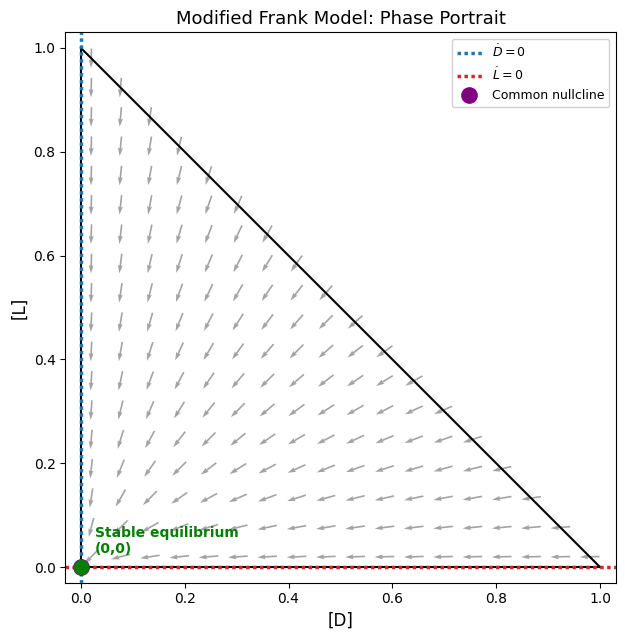

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------
# Vector field
# ---------------------------------

def dD(D, L):
    return -D*(D + L)

def dL(D, L):
    return -L*(D + L)

fig, ax = plt.subplots(figsize=(6.5,6.5))

# ---------------------------------
# Vector field
# ---------------------------------

n = 18

Dg = np.linspace(0.02,0.98,n)
Lg = np.linspace(0.02,0.98,n)

DD, LL = np.meshgrid(Dg,Lg)

mask = (DD + LL) <= 1.0

U = dD(DD,LL)
V = dL(DD,LL)

speed = np.sqrt(U**2 + V**2)
speed[speed==0] = 1

Un = np.where(mask,U/speed,np.nan)
Vn = np.where(mask,V/speed,np.nan)

ax.quiver(
    DD,
    LL,
    Un,
    Vn,
    color='0.55',
    pivot='mid',
    scale=28,
    width=0.003,
    alpha=0.8
)

# ---------------------------------
# Simplex
# ---------------------------------

ax.plot([0,1],[0,0],'k-',linewidth=1.5)
ax.plot([0,0],[0,1],'k-',linewidth=1.5)
ax.plot([0,1],[1,0],'k-',linewidth=1.5)

# ---------------------------------
# Nullclines
# ---------------------------------

x = np.linspace(0,1,400)

# D=0

ax.axvline(
    0,
    color='#1f77b4',
    linewidth=2.5,
    linestyle=(0,(1,1)),
    label=r'$\dot D=0$'
)

# L=0

ax.axhline(
    0,
    color='#d62728',
    linewidth=2.5,
    linestyle=(0,(1,1)),
    label=r'$\dot L=0$'
)

# D+L=0

ax.plot(
    [0],
    [0],
    'o',
    color='purple',
    markersize=11,
    label='Common nullcline'
)

# ---------------------------------
# Equilibrium
# ---------------------------------

ax.plot(
    0,
    0,
    'o',
    color='green',
    markersize=10,
    zorder=5
)

ax.annotate(
    'Stable equilibrium\n(0,0)',
    (0,0),
    textcoords='offset points',
    xytext=(10,10),
    fontsize=10,
    color='green',
    fontweight='bold'
)

# ---------------------------------

ax.set_xlim(-0.03,1.03)
ax.set_ylim(-0.03,1.03)

ax.set_xlabel('[D]',fontsize=12)
ax.set_ylabel('[L]',fontsize=12)

ax.set_title(
    "Modified Frank Model: Phase Portrait",
    fontsize=13
)

ax.set_aspect('equal')

ax.legend(
    loc='upper right',
    fontsize=9,
    framealpha=0.9
)

plt.tight_layout()
plt.show()

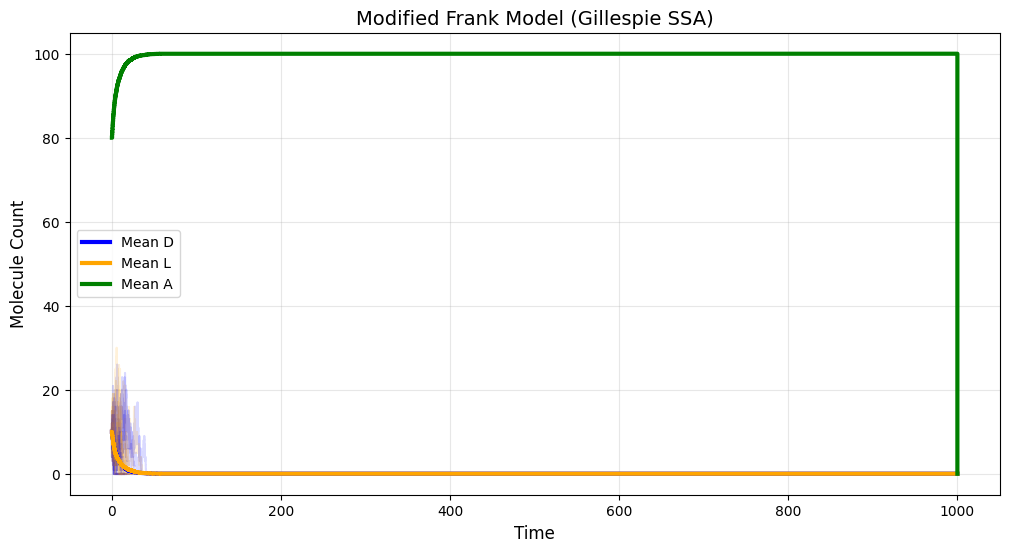

[10, 9, 9, 8, 7, 7, 7, 7, 7, 6, 6, 6, 6, 6, 7, 6, 6, 6, 5, 4, 5, 5, 6, 6, 5, 4, 4, 3, 3, 3, 2, 2, 2, 2, 2, 2, 1, 1, 0, 0, 0, 0, 0, 0, 0]


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random

# -----------------------------
# Parameters
# -----------------------------

ka = 1.0
kd = 1.0

Vol = 100

A0 = 80
D0 = 10
L0 = 10

mt = 1000
dt = 0.2

meantime = np.arange(0, mt+dt, dt)

ntraj = 1000

concA = np.zeros((ntraj, len(meantime)))
concD = np.zeros((ntraj, len(meantime)))
concL = np.zeros((ntraj, len(meantime)))

# -----------------------------
# Gillespie SSA
# -----------------------------

def frank(Vol, A, D, L, ka, kd, i, concA, concD, concL):

    concA[i,0] = A
    concD[i,0] = D
    concL[i,0] = L

    t = 0.0
    t2 = 0.0
    j = 0

    times = [0.0]
    countA = [A]
    countD = [D]
    countL = [L]

    while True:

        if t >= mt or t2 >= mt:
            break

        # -----------------------------
        # Propensities
        # -----------------------------

        a1 = ka*A*D/Vol
        a2 = ka*A*L/Vol
        a3 = kd*D
        a4 = kd*L

        a0 = a1 + a2 + a3 + a4

        if a0 == 0:
            break

        # -----------------------------
        # Waiting time
        # -----------------------------

        r1 = random.random()
        tau = (1/a0)*math.log(1/r1)

        t += tau

        # -----------------------------
        # Record on fixed grid
        # -----------------------------

        while (t2+dt) <= t:

            j += 1
            t2 += dt

            if j >= concA.shape[1]:
                break

            concA[i,j] = A
            concD[i,j] = D
            concL[i,j] = L

        if j >= concA.shape[1]:
            break

        # -----------------------------
        # Select reaction
        # -----------------------------

        r2 = random.random()*a0

        if r2 <= a1:

            # A + D -> 2D

            A -= 1
            D += 1

        elif r2 <= a1+a2:

            # A + L -> 2L

            A -= 1
            L += 1

        elif r2 <= a1+a2+a3:

            # D -> A

            D -= 1
            A += 1

        else:

            # L -> A

            L -= 1
            A += 1

        times.append(t)
        countA.append(A)
        countD.append(D)
        countL.append(L)

    # -----------------------------
    # Fill remaining observation grid
    # -----------------------------

    while (t2+dt) <= mt:

        j += 1
        t2 += dt

        if j >= concA.shape[1]:
            break

        concA[i,j] = A
        concD[i,j] = D
        concL[i,j] = L

    return countA, countD, countL, times


# -----------------------------
# Run ensemble
# -----------------------------

plt.figure(figsize=(12,6))

for i in range(ntraj):

    countA, countD, countL, times = frank(
        Vol,
        A0,
        D0,
        L0,
        ka,
        kd,
        i,
        concA,
        concD,
        concL
    )

    if i < 20:

        plt.step(times,
                 countD,
                 where='post',
                 color='blue',
                 alpha=0.15)

        plt.step(times,
                 countL,
                 where='post',
                 color='orange',
                 alpha=0.15)

# -----------------------------
# Ensemble averages
# -----------------------------

meanA = np.mean(concA, axis=0)
meanD = np.mean(concD, axis=0)
meanL = np.mean(concL, axis=0)

plt.step(meantime,
         meanD,
         where='post',
         linewidth=3,
         color='blue',
         label='Mean D')

plt.step(meantime,
         meanL,
         where='post',
         linewidth=3,
         color='orange',
         label='Mean L')

plt.step(meantime,
         meanA,
         where='post',
         linewidth=3,
         color='green',
         label='Mean A')

plt.xlabel("Time", fontsize=12)
plt.ylabel("Molecule Count", fontsize=12)
plt.title("Modified Frank Model (Gillespie SSA)", fontsize=14)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

print(countL)

## Case: $k_a=0.5,\;k_d=1$

Assuming conservation of mass,

$$
A+D+L=1,
$$

we substitute

$$
A=1-D-L
$$

into the governing equations.

---

## Reduced Equations

The deterministic equations are

$$
\frac{dD}{dt}
=
k_aAD-k_dD,
$$

$$
\frac{dL}{dt}
=
k_aAL-k_dL.
$$

Substituting

$$
k_a=0.5,\qquad
k_d=1,
$$

gives

$$
\frac{dD}{dt}
=
0.5D(1-D-L)-D,
$$

which simplifies to

$$
\boxed{
\frac{dD}{dt}
=
-\frac12 D(1+D+L).
}
$$

Similarly,

$$
\frac{dL}{dt}
=
0.5L(1-D-L)-L,
$$

which simplifies to

$$
\boxed{
\frac{dL}{dt}
=
-\frac12 L(1+D+L).
}
$$

---

## Nullclines

### $D$-nullclines

Setting

$$
\frac{dD}{dt}=0,
$$

gives

$$
-\frac12 D(1+D+L)=0.
$$

Hence,

$$
\boxed{
D=0
}
$$

or

$$
\boxed{
1+D+L=0.
}
$$

---

### $L$-nullclines

Setting

$$
\frac{dL}{dt}=0,
$$

gives

$$
-\frac12 L(1+D+L)=0.
$$

Hence,

$$
\boxed{
L=0
}
$$

or

$$
\boxed{
1+D+L=0.
}
$$

---

## Intersection of the Nullclines

The equilibrium points satisfy both nullcline conditions simultaneously.

### Case 1

$$
D=0,\qquad L=0,
$$

which gives

$$
\boxed{(D,L)=(0,0).}
$$

---

### Case 2

$$
D=0,\qquad 1+D+L=0,
$$

implies

$$
L=-1,
$$

which is not physically admissible.

---

### Case 3

$$
L=0,\qquad 1+D+L=0,
$$

implies

$$
D=-1,
$$

which is not physically admissible.

---

### Case 4

$$
1+D+L=0
$$

cannot be satisfied for

$$
D\ge0,\qquad L\ge0.
$$

Hence there are no additional physical equilibria.

---

## Equilibrium Point

Therefore, the only physically admissible equilibrium is

$$
\boxed{
(D,L)=(0,0).
}
$$

Using

$$
A=1-D-L,
$$

the corresponding equilibrium of the full system is

$$
\boxed{
(A,D,L)=(1,0,0).
}
$$

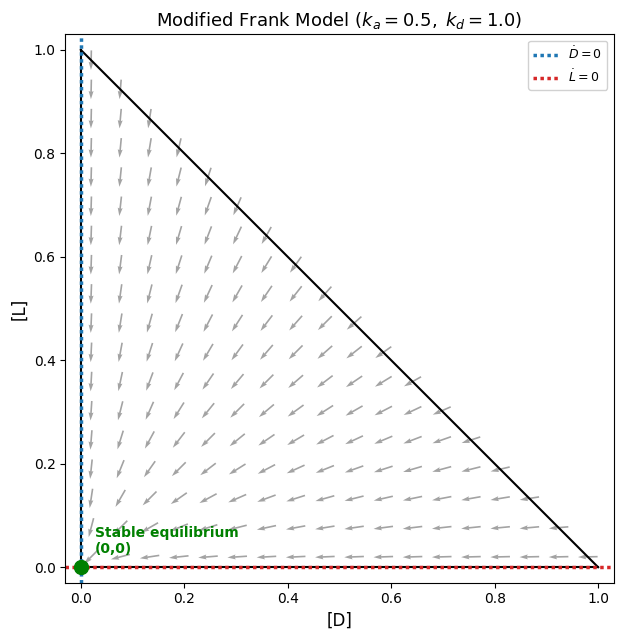

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
ka = 0.5
kd = 1.0

# -----------------------------
# Vector field
# -----------------------------

def dD(D, L):
    return D*(ka*(1-D-L)-kd)

def dL(D, L):
    return L*(ka*(1-D-L)-kd)

fig, ax = plt.subplots(figsize=(6.5,6.5))

# Vector field
n = 18

Dg = np.linspace(0.02,0.98,n)
Lg = np.linspace(0.02,0.98,n)

DD, LL = np.meshgrid(Dg,Lg)

mask = (DD+LL)<=1

U = dD(DD,LL)
V = dL(DD,LL)

speed = np.sqrt(U**2+V**2)
speed[speed==0]=1

Un = np.where(mask,U/speed,np.nan)
Vn = np.where(mask,V/speed,np.nan)

ax.quiver(
    DD,
    LL,
    Un,
    Vn,
    color='0.55',
    pivot='mid',
    scale=28,
    width=0.003,
    alpha=0.8
)

# Simplex boundary

ax.plot([0,1],[0,0],'k-',linewidth=1.5)
ax.plot([0,0],[0,1],'k-',linewidth=1.5)
ax.plot([0,1],[1,0],'k-',linewidth=1.5)

# -----------------------------
# Nullclines
# -----------------------------

# D = 0
ax.axvline(
    0,
    color='#1f77b4',
    linewidth=2.5,
    linestyle=(0,(1,1)),
    label=r'$\dot D=0$'
)

# L = 0
ax.axhline(
    0,
    color='#d62728',
    linewidth=2.5,
    linestyle=(0,(1,1)),
    label=r'$\dot L=0$'
)

# Equilibrium
ax.plot(
    0,
    0,
    'o',
    color='green',
    markersize=10,
    zorder=5
)

ax.annotate(
    'Stable equilibrium\n(0,0)',
    (0,0),
    textcoords='offset points',
    xytext=(10,10),
    fontsize=10,
    color='green',
    fontweight='bold'
)

ax.set_xlim(-0.03,1.03)
ax.set_ylim(-0.03,1.03)

ax.set_xlabel('[D]',fontsize=12)
ax.set_ylabel('[L]',fontsize=12)

ax.set_title(
    r'Modified Frank Model ($k_a=0.5,\;k_d=1.0$)',
    fontsize=13
)

ax.legend(loc='upper right',fontsize=9,framealpha=0.9)

ax.set_aspect('equal')

plt.tight_layout()
plt.show()

## Reduced Equations

For the case

$$
k_a=1,\qquad k_d=0.5,
$$

the governing equations are

$$
\frac{dD}{dt}=k_aAD-k_dD,
$$

$$
\frac{dL}{dt}=k_aAL-k_dL.
$$

Assuming conservation of mass,

$$
A+D+L=1,
$$

we substitute

$$
A=1-D-L.
$$

Substituting this into the governing equations gives

$$
\frac{dD}{dt}
=
D(1-D-L)-0.5D,
$$

$$
\frac{dL}{dt}
=
L(1-D-L)-0.5L.
$$

Expanding,

$$
\frac{dD}{dt}
=
D-D^2-DL-0.5D,
$$

$$
\frac{dL}{dt}
=
L-DL-L^2-0.5L.
$$

Combining like terms,

$$
\boxed{
\frac{dD}{dt}
=
D\left(\frac12-D-L\right),
}
$$

$$
\boxed{
\frac{dL}{dt}
=
L\left(\frac12-D-L\right).
}
$$

These are the reduced two-dimensional mean-field equations governing the dynamics of the decay model for the parameter regime

$$
k_a=1,\qquad k_d=0.5.
$$

## Nullcline Analysis

The nullclines are obtained by setting each differential equation equal to zero.

### D-nullclines

Setting

$$
\frac{dD}{dt}=0,
$$

gives

$$
D\left(\frac12-D-L\right)=0.
$$

Hence the two $D$-nullclines are

$$
\boxed{D=0}
$$

and

$$
\boxed{D+L=\frac12.}
$$

---

### L-nullclines

Setting

$$
\frac{dL}{dt}=0,
$$

gives

$$
L\left(\frac12-D-L\right)=0.
$$

Hence the two $L$-nullclines are

$$
\boxed{L=0}
$$

and

$$
\boxed{D+L=\frac12.}
$$

---

## Intersection of the Nullclines

The equilibrium points are obtained by solving the nullcline equations simultaneously.

### Case 1

The trivial nullclines intersect at

$$
D=0,\qquad L=0,
$$

giving the equilibrium

$$
\boxed{(D,L)=(0,0).}
$$

---

### Case 2

The non-trivial nullclines are identical,

$$
D+L=\frac12.
$$

Therefore, every point satisfying

$$
\boxed{D+L=\frac12}
$$

is an equilibrium point.

Equivalently,

$$
\boxed{
(D,L)=\left(D,\frac12-D\right),
\qquad
0\le D\le\frac12.
}
$$

This represents a continuous line of equilibrium points within the physically admissible region.

---

## Physical Equilibria

The system therefore possesses

- the achiral equilibrium

$$
\boxed{(D,L)=(0,0),}
$$

and

- a continuum of racemic/chiral coexistence equilibria given by

$$
\boxed{
D+L=\frac12,
\qquad
0\le D\le\frac12.
}
$$

Using

$$
A=1-D-L,
$$

every point on this equilibrium line corresponds to

$$
\boxed{
A=\frac12.
}
$$

Hence the full equilibrium manifold is

$$
\boxed{
(A,D,L)=
\left(
\frac12,\;
D,\;
\frac12-D
\right),
\qquad
0\le D\le\frac12.
}
$$

## Linear Stability Analysis

For the case

$$
k_a=1,\qquad k_d=0.5,
$$

the reduced system is

$$
\frac{dD}{dt}
=
D\left(\frac12-D-L\right),
$$

$$
\frac{dL}{dt}
=
L\left(\frac12-D-L\right).
$$

Define

$$
f(D,L)=D\left(\frac12-D-L\right),
$$

$$
g(D,L)=L\left(\frac12-D-L\right).
$$

The Jacobian matrix is given by

$$
J(D,L)=
\begin{pmatrix}
\dfrac{\partial f}{\partial D} &
\dfrac{\partial f}{\partial L}\\[2mm]
\dfrac{\partial g}{\partial D} &
\dfrac{\partial g}{\partial L}
\end{pmatrix}.
$$

Evaluating the partial derivatives,

$$
\frac{\partial f}{\partial D}
=
\frac12-2D-L,
$$

$$
\frac{\partial f}{\partial L}
=
-D,
$$

$$
\frac{\partial g}{\partial D}
=
-L,
$$

$$
\frac{\partial g}{\partial L}
=
\frac12-D-2L.
$$

Hence, the Jacobian matrix is

$$
J(D,L)=
\begin{pmatrix}
\frac12-2D-L & -D\\[2mm]
-L & \frac12-D-2L
\end{pmatrix}.
$$

---

### Jacobian at the Equilibrium

Evaluating the Jacobian at the equilibrium point

$$
(D,L)=(0,0),
$$

gives

$$
J(0,0)
=
\begin{pmatrix}
\frac12 & 0\\
0 & \frac12
\end{pmatrix}.
$$

---

### Eigenvalue Analysis

The characteristic equation is

$$
\det(J-\lambda I)=0.
$$

Substituting the Jacobian,

$$
\left|
\begin{matrix}
\frac12-\lambda & 0\\
0 & \frac12-\lambda
\end{matrix}
\right|
=0.
$$

Hence,

$$
\boxed{
\lambda_1=\lambda_2=\frac12.
}
$$

---

### Stability

Since both eigenvalues are real and strictly positive,

$$
\lambda_1>0,\qquad
\lambda_2>0,
$$

the equilibrium point

$$
(D,L)=(0,0)
$$

is an **unstable node (unstable source)**.

Using the conservation relation

$$
A+D+L=1,
$$

the corresponding equilibrium of the full system is

$$
\boxed{
(A,D,L)=(1,0,0).
}
$$

Therefore, any small perturbation away from the achiral equilibrium grows with time, causing trajectories to move away from the origin and toward the equilibrium manifold

$$
\boxed{
D+L=\frac12.
}
$$

Thus, for the regime

$$
k_a>k_d,
$$

the achiral equilibrium is unstable, reflecting the dominance of autocatalytic production over linear decay.

## Linear Stability Analysis of the Equilibrium Manifold

The non-trivial equilibrium manifold is given by

$$
D+L=\frac12.
$$

Substituting

$$
L=\frac12-D
$$

into the Jacobian matrix

$$
J(D,L)=
\begin{pmatrix}
\frac12-2D-L & -D\\[2mm]
-L & \frac12-D-2L
\end{pmatrix},
$$

gives

$$
J=
\begin{pmatrix}
-D & -D\\[2mm]
D-\frac12 & D-\frac12
\end{pmatrix}.
$$

---

### Eigenvalue Analysis

The characteristic equation is

$$
\det(J-\lambda I)=0.
$$

Subtracting

$$
\lambda I
$$

from the Jacobian,

$$
J-\lambda I=
\begin{pmatrix}
-D-\lambda & -D\\[2mm]
D-\frac12 & D-\frac12-\lambda
\end{pmatrix}.
$$

Taking the determinant,

$$
(-D-\lambda)\left(D-\frac12-\lambda\right)
-
(-D)\left(D-\frac12\right)
=0.
$$

Since

$$
-(-D)\left(D-\frac12\right)
=
+D\left(D-\frac12\right),
$$

we obtain

$$
(-D-\lambda)\left(D-\frac12-\lambda\right)
+
D\left(D-\frac12\right)
=0.
$$

Expanding the first product,

$$
(-D)\left(D-\frac12-\lambda\right)
-\lambda\left(D-\frac12-\lambda\right)
+D\left(D-\frac12\right)
=0.
$$

Expanding each term,

$$
-D^2+\frac{D}{2}+D\lambda
-\lambda D+\frac{\lambda}{2}+\lambda^2
+D^2-\frac{D}{2}
=0.
$$

The terms

$$
-D^2+D^2=0,
$$

$$
\frac{D}{2}-\frac{D}{2}=0,
$$

and

$$
D\lambda-\lambda D=0
$$

cancel identically, leaving

$$
\lambda^2+\frac12\lambda=0.
$$

Factoring,

$$
\lambda\left(\lambda+\frac12\right)=0.
$$

Hence the eigenvalues are

$$
\boxed{
\lambda_1=0,
\qquad
\lambda_2=-\frac12.
}
$$

---

### Stability

The zero eigenvalue indicates that the equilibrium is **non-hyperbolic**, and therefore the standard Jacobian theorem cannot determine stability along the equilibrium manifold.

However, the second eigenvalue

$$
\lambda_2=-\frac12
$$

is strictly negative, indicating that perturbations transverse to the manifold decay exponentially.

Thus, trajectories are attracted toward the equilibrium manifold

$$
D+L=\frac12,
$$

but experience no restoring force along the manifold itself.

Consequently, the deterministic system converges to the line of equilibria, with the final equilibrium determined by the initial conditions.

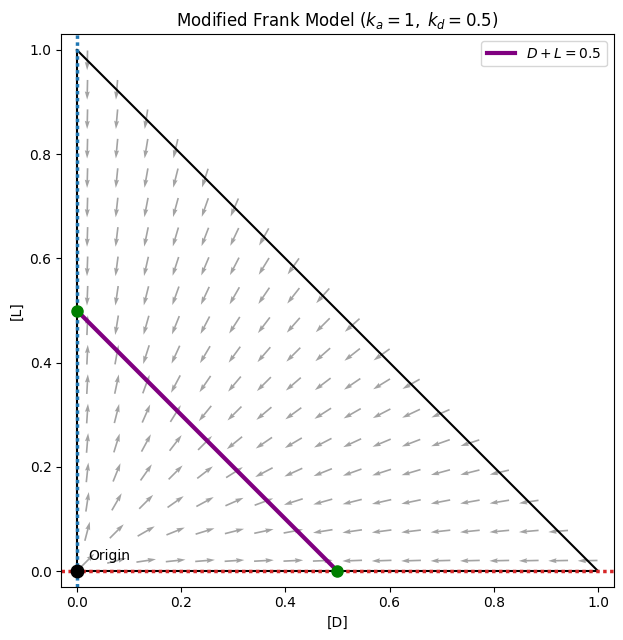

In [22]:
import numpy as np
import matplotlib.pyplot as plt

ka = 1.0
kd = 0.5

def dD(D, L):
    return D*(ka*(1-D-L)-kd)

def dL(D, L):
    return L*(ka*(1-D-L)-kd)

fig, ax = plt.subplots(figsize=(6.5,6.5))

# -----------------------------
# Vector field
# -----------------------------

n = 18

Dg = np.linspace(0.02,0.98,n)
Lg = np.linspace(0.02,0.98,n)

DD, LL = np.meshgrid(Dg,Lg)

mask = (DD+LL)<=1

U = dD(DD,LL)
V = dL(DD,LL)

speed = np.sqrt(U**2+V**2)
speed[speed==0]=1

Un = np.where(mask,U/speed,np.nan)
Vn = np.where(mask,V/speed,np.nan)

ax.quiver(
    DD,
    LL,
    Un,
    Vn,
    color='0.55',
    pivot='mid',
    scale=28,
    width=0.003,
    alpha=0.8
)

# -----------------------------
# Simplex boundary
# -----------------------------

ax.plot([0,1],[0,0],'k-',linewidth=1.5)
ax.plot([0,0],[0,1],'k-',linewidth=1.5)
ax.plot([0,1],[1,0],'k-',linewidth=1.5)

# -----------------------------
# Nullclines
# -----------------------------

x = np.linspace(0,0.5,300)

# D = 0
ax.axvline(
    0,
    color='#1f77b4',
    linewidth=2.5,
    linestyle=(0,(1,1))
)

# L = 0
ax.axhline(
    0,
    color='#d62728',
    linewidth=2.5,
    linestyle=(0,(1,1))
)

# Interior nullcline
ax.plot(
    x,
    0.5-x,
    color='purple',
    linewidth=3,
    label=r'$D+L=0.5$'
)

# Origin
ax.plot(
    0,
    0,
    'ko',
    markersize=9
)

ax.annotate(
    'Origin',
    (0,0),
    xytext=(8,8),
    textcoords='offset points'
)

# Endpoints of equilibrium line
ax.plot(0.5,0,'go',markersize=8)
ax.plot(0,0.5,'go',markersize=8)

ax.set_xlim(-0.03,1.03)
ax.set_ylim(-0.03,1.03)

ax.set_xlabel('[D]')
ax.set_ylabel('[L]')

ax.set_title(r'Modified Frank Model ($k_a=1,\;k_d=0.5$)')

ax.legend()
ax.set_aspect('equal')

plt.tight_layout()
plt.show()

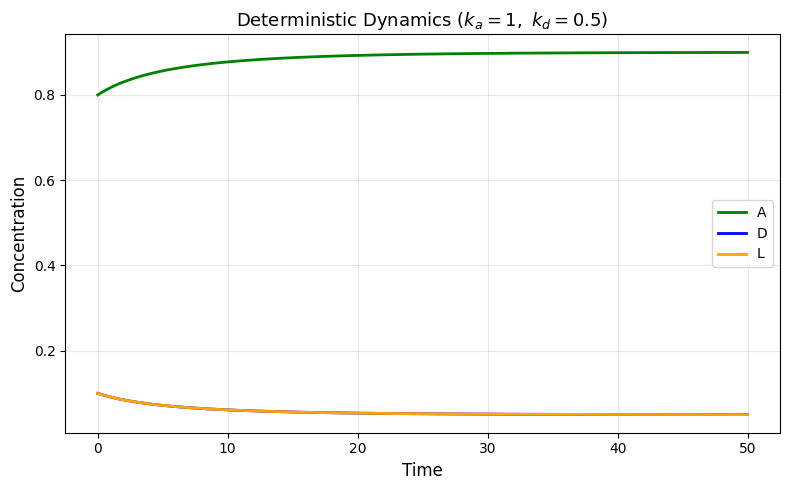

0.8996619637911363


In [52]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# -------------------------------------------------
# Parameters
# -------------------------------------------------

ka = 1.0
kd = 0.9

# -------------------------------------------------
# Full Mean-Field Model
# -------------------------------------------------

def frank_decay(t, y):
    A, D, L = y

    dA = -ka*A*D - ka*A*L + kd*D + kd*L
    dD =  ka*A*D - kd*D
    dL =  ka*A*L - kd*L

    return [dA, dD, dL]

# -------------------------------------------------
# Initial Conditions
# -------------------------------------------------

y0 = [0.8, 0.1, 0.1]

# -------------------------------------------------
# Time Span
# -------------------------------------------------

t_span = (0, 50)
t_eval = np.linspace(0, 50, 500)

# -------------------------------------------------
# Solve
# -------------------------------------------------

sol = solve_ivp(
    frank_decay,
    t_span,
    y0,
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-12
)

# -------------------------------------------------
# Plot
# -------------------------------------------------

plt.figure(figsize=(8,5))

plt.plot(sol.t, sol.y[0], color='green', lw=2, label='A')
plt.plot(sol.t, sol.y[1], color='blue', lw=2, label='D')
plt.plot(sol.t, sol.y[2], color='orange', lw=2, label='L')

plt.xlabel("Time", fontsize=12)
plt.ylabel("Concentration", fontsize=12)
plt.title(r"Deterministic Dynamics ($k_a=1,\ k_d=0.5$)", fontsize=13)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

print(sol.y[0][-1])

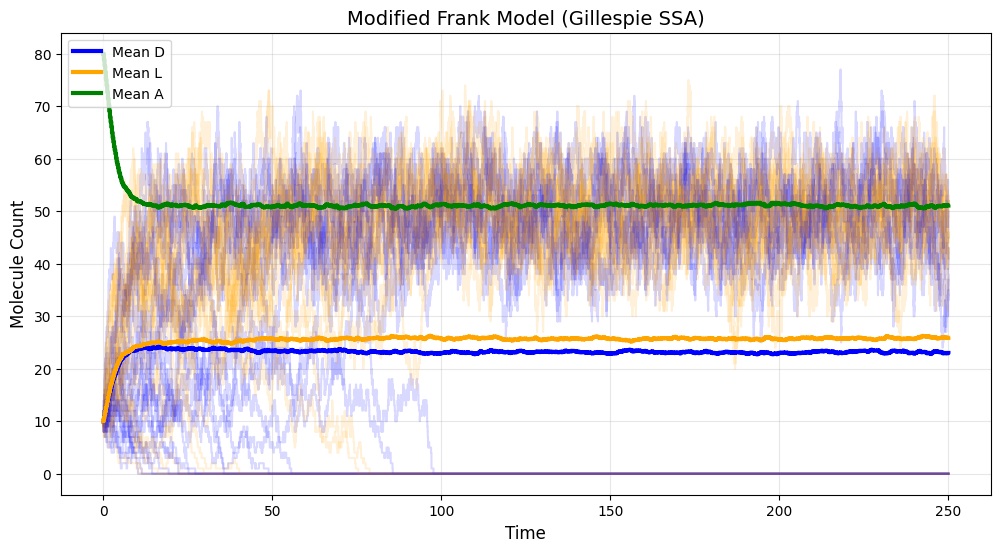

[10, 10, 10, 10, 11, 12, 12, 13, 14, 15, 15, 16, 17, 18, 18, 17, 16, 15, 15, 16, 15, 14, 13, 14, 14, 14, 13, 13, 12, 13, 13, 14, 14, 13, 13, 12, 13, 12, 12, 13, 12, 11, 12, 12, 11, 11, 12, 12, 12, 12, 11, 12, 12, 12, 12, 12, 13, 13, 13, 13, 13, 13, 13, 12, 11, 10, 10, 9, 9, 10, 9, 8, 7, 7, 7, 7, 8, 8, 8, 8, 9, 9, 10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 10, 9, 9, 10, 10, 11, 11, 12, 13, 14, 14, 15, 14, 14, 14, 13, 13, 13, 13, 13, 14, 14, 15, 15, 15, 15, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15, 15, 15, 16, 16, 16, 17, 17, 17, 17, 17, 18, 18, 19, 19, 19, 20, 20, 20, 20, 21, 21, 22, 23, 23, 22, 23, 23, 23, 24, 24, 24, 23, 24, 24, 24, 23, 23, 23, 22, 21, 22, 21, 20, 20, 20, 20, 20, 20, 20, 20, 21, 20, 19, 19, 20, 20, 21, 20, 20, 21, 22, 22, 21, 21, 21, 22, 22, 22, 22, 23, 24, 23, 23, 23, 23, 23, 23, 23, 23, 23, 22, 22, 22, 21, 21, 22, 22, 21, 21, 21, 21, 21, 20, 20, 21, 21, 21, 21, 21, 21, 20, 20, 20, 19, 19, 19, 18, 19, 20, 20, 20, 20, 21, 21, 21, 22, 21, 21, 21, 21, 21,

In [88]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random

# -----------------------------
# Parameters
# -----------------------------

ka = 1.0
kd = 0.5

Vol = 100

A0 = 80
D0 = 10
L0 = 10

mt = 250
dt = 0.2

meantime = np.arange(0, mt+dt, dt)

ntraj = 1000

concA = np.zeros((ntraj, len(meantime)))
concD = np.zeros((ntraj, len(meantime)))
concL = np.zeros((ntraj, len(meantime)))

# -----------------------------
# Gillespie SSA
# -----------------------------

def frank(Vol, A, D, L, ka, kd, i, concA, concD, concL):

    concA[i,0] = A
    concD[i,0] = D
    concL[i,0] = L

    t = 0.0
    t2 = 0.0
    j = 0

    times = [0.0]
    countA = [A]
    countD = [D]
    countL = [L]

    while True:

        if t >= mt or t2 >= mt:
            break

        # -----------------------------
        # Propensities
        # -----------------------------

        a1 = ka*A*D/Vol
        a2 = ka*A*L/Vol
        a3 = kd*D
        a4 = kd*L

        a0 = a1 + a2 + a3 + a4

        if a0 == 0:
            break

        # -----------------------------
        # Waiting time
        # -----------------------------

        r1 = random.random()
        tau = (1/a0)*math.log(1/r1)

        t += tau

        # -----------------------------
        # Record on fixed grid
        # -----------------------------

        while (t2+dt) <= t:

            j += 1
            t2 += dt

            if j >= concA.shape[1]:
                break

            concA[i,j] = A
            concD[i,j] = D
            concL[i,j] = L

        if j >= concA.shape[1]:
            break

        # -----------------------------
        # Select reaction
        # -----------------------------

        r2 = random.random()*a0

        if r2 <= a1:

            # A + D -> 2D

            A -= 1
            D += 1

        elif r2 <= a1+a2:

            # A + L -> 2L

            A -= 1
            L += 1

        elif r2 <= a1+a2+a3:

            # D -> A

            D -= 1
            A += 1

        else:

            # L -> A

            L -= 1
            A += 1

        times.append(t)
        countA.append(A)
        countD.append(D)
        countL.append(L)

    # -----------------------------
    # Fill remaining observation grid
    # -----------------------------

    while (t2+dt) <= mt:

        j += 1
        t2 += dt

        if j >= concA.shape[1]:
            break

        concA[i,j] = A
        concD[i,j] = D
        concL[i,j] = L

    return countA, countD, countL, times


# -----------------------------
# Run ensemble
# -----------------------------

plt.figure(figsize=(12,6))

for i in range(ntraj):

    countA, countD, countL, times = frank(
        Vol,
        A0,
        D0,
        L0,
        ka,
        kd,
        i,
        concA,
        concD,
        concL
    )

    if i < 20:

        plt.step(times,
                 countD,
                 where='post',
                 color='blue',
                 alpha=0.15)

        plt.step(times,
                 countL,
                 where='post',
                 color='orange',
                 alpha=0.15)

# -----------------------------
# Ensemble averages
# -----------------------------

meanA = np.mean(concA, axis=0)
meanD = np.mean(concD, axis=0)
meanL = np.mean(concL, axis=0)

plt.step(meantime,
         meanD,
         where='post',
         linewidth=3,
         color='blue',
         label='Mean D')

plt.step(meantime,
         meanL,
         where='post',
         linewidth=3,
         color='orange',
         label='Mean L')

plt.step(meantime,
         meanA,
         where='post',
         linewidth=3,
         color='green',
         label='Mean A')

plt.xlabel("Time", fontsize=12)
plt.ylabel("Molecule Count", fontsize=12)
plt.title("Modified Frank Model (Gillespie SSA)", fontsize=14)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

print(countL)
print(countD)

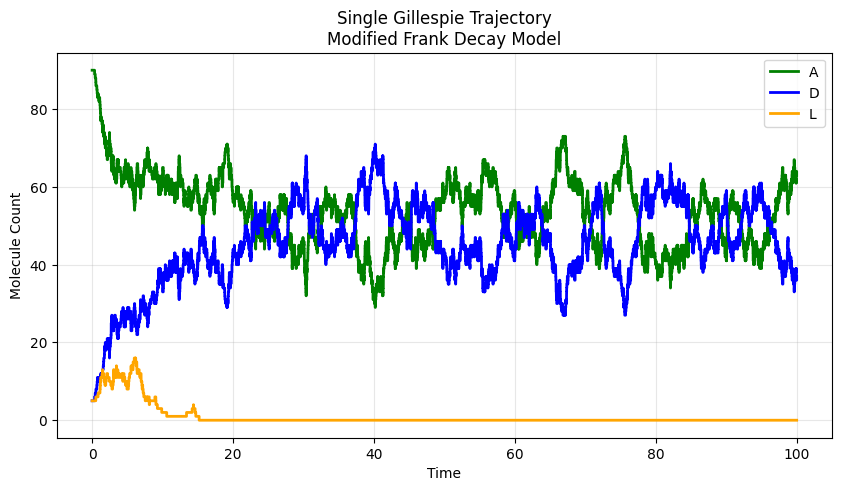

In [91]:
import matplotlib.pyplot as plt
import numpy as np
import random
import math

# ---------------------------------
# Parameters
# ---------------------------------

ka = 1.0
kd = 0.5

Vol = 100

A = 90
D = 5
L = 5

t = 0.0
tmax = 100

# ---------------------------------
# Storage
# ---------------------------------

times = [0]
A_hist = [A]
D_hist = [D]
L_hist = [L]

# ---------------------------------
# Gillespie SSA
# ---------------------------------

while t < tmax:

    # Propensities

    a1 = ka*A*D/Vol      # A + D -> 2D
    a2 = ka*A*L/Vol      # A + L -> 2L
    a3 = kd*D            # D -> A
    a4 = kd*L            # L -> A

    a0 = a1 + a2 + a3 + a4

    if a0 == 0:
        break

    # Waiting time

    r1 = random.random()
    tau = -math.log(r1)/a0
    t += tau

    # Reaction selection

    r2 = random.random()*a0

    if r2 < a1:

        # A + D -> 2D
        A -= 1
        D += 1

    elif r2 < a1+a2:

        # A + L -> 2L
        A -= 1
        L += 1

    elif r2 < a1+a2+a3:

        # D -> A
        D -= 1
        A += 1

    else:

        # L -> A
        L -= 1
        A += 1

    # Record state

    times.append(t)
    A_hist.append(A)
    D_hist.append(D)
    L_hist.append(L)

# ---------------------------------
# Plot
# ---------------------------------

plt.figure(figsize=(10,5))

plt.step(times, A_hist, where='post',
         linewidth=2,
         color='green',
         label='A')

plt.step(times, D_hist, where='post',
         linewidth=2,
         color='blue',
         label='D')

plt.step(times, L_hist, where='post',
         linewidth=2,
         color='orange',
         label='L')

plt.xlabel("Time")
plt.ylabel("Molecule Count")
plt.title("Single Gillespie Trajectory\nModified Frank Decay Model")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

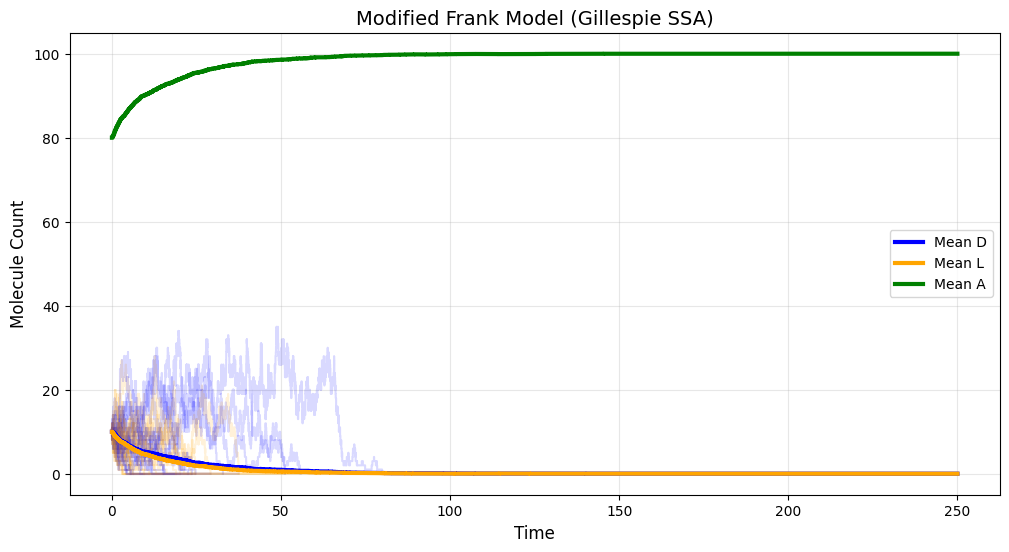

[10, 10, 10, 10, 11, 10, 9, 10, 10, 10, 10, 10, 11, 10, 10, 11, 12, 11, 12, 13, 13, 12, 13, 13, 13, 13, 12, 11, 10, 9, 9, 8, 9, 9, 9, 8, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 8, 9, 8, 8, 9, 9, 9, 10, 10, 9, 9, 9, 9, 8, 8, 8, 7, 6, 7, 7, 7, 7, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 7, 6, 7, 7, 7, 7, 7, 8, 8, 8, 8, 8, 7, 6, 6, 6, 7, 7, 7, 6, 6, 6, 6, 6, 5, 5, 5, 5, 6, 7, 6, 5, 6, 6, 6, 6, 6, 6, 5, 5, 4, 4, 4, 3, 4, 4, 4, 5, 4, 5, 5, 5, 4, 3, 3, 2, 1, 1, 2, 2, 3, 3, 4, 3, 4, 3, 3, 4, 4, 4, 4, 3, 2, 2, 2, 3, 2, 2, 2, 2, 3, 4, 4, 3, 4, 5, 4, 3, 4, 3, 2, 3, 2, 3, 4, 5, 6, 5, 4, 5, 6, 7, 6, 7, 8, 9, 8, 9, 10, 11, 12, 11, 10, 11, 10, 9, 10, 9, 10, 11, 12, 11, 12, 11, 12, 11, 10, 9, 10, 11, 10, 11, 12, 13, 12, 11, 12, 11, 10, 9, 8, 9, 10, 9, 8, 9, 8, 9, 10, 9, 10, 11, 12, 13, 12, 13, 12, 13, 14, 15, 14, 15, 14, 15, 14, 15, 14, 15, 16, 15, 14, 13, 14, 13, 14, 13, 12, 11, 12, 13, 14, 15, 16, 17, 16, 15, 14, 15, 16, 15, 14, 13, 12, 13, 14, 15, 16, 15, 16, 17, 18, 19, 20, 21, 22, 21, 20, 19, 20, 19, 20, 19, 20, 19,

In [89]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random

# -----------------------------
# Parameters
# -----------------------------

ka = 1.0
kd = 0.9

Vol = 100

A0 = 80
D0 = 10
L0 = 10

mt = 250
dt = 0.2

meantime = np.arange(0, mt+dt, dt)

ntraj = 1000

concA = np.zeros((ntraj, len(meantime)))
concD = np.zeros((ntraj, len(meantime)))
concL = np.zeros((ntraj, len(meantime)))

# -----------------------------
# Gillespie SSA
# -----------------------------

def frank(Vol, A, D, L, ka, kd, i, concA, concD, concL):

    concA[i,0] = A
    concD[i,0] = D
    concL[i,0] = L

    t = 0.0
    t2 = 0.0
    j = 0

    times = [0.0]
    countA = [A]
    countD = [D]
    countL = [L]

    while True:

        if t >= mt or t2 >= mt:
            break

        # -----------------------------
        # Propensities
        # -----------------------------

        a1 = ka*A*D/Vol
        a2 = ka*A*L/Vol
        a3 = kd*D
        a4 = kd*L

        a0 = a1 + a2 + a3 + a4

        if a0 == 0:
            break

        # -----------------------------
        # Waiting time
        # -----------------------------

        r1 = random.random()
        tau = (1/a0)*math.log(1/r1)

        t += tau

        # -----------------------------
        # Record on fixed grid
        # -----------------------------

        while (t2+dt) <= t:

            j += 1
            t2 += dt

            if j >= concA.shape[1]:
                break

            concA[i,j] = A
            concD[i,j] = D
            concL[i,j] = L

        if j >= concA.shape[1]:
            break

        # -----------------------------
        # Select reaction
        # -----------------------------

        r2 = random.random()*a0

        if r2 <= a1:

            # A + D -> 2D

            A -= 1
            D += 1

        elif r2 <= a1+a2:

            # A + L -> 2L

            A -= 1
            L += 1

        elif r2 <= a1+a2+a3:

            # D -> A

            D -= 1
            A += 1

        else:

            # L -> A

            L -= 1
            A += 1

        times.append(t)
        countA.append(A)
        countD.append(D)
        countL.append(L)

    # -----------------------------
    # Fill remaining observation grid
    # -----------------------------

    while (t2+dt) <= mt:

        j += 1
        t2 += dt

        if j >= concA.shape[1]:
            break

        concA[i,j] = A
        concD[i,j] = D
        concL[i,j] = L

    return countA, countD, countL, times


# -----------------------------
# Run ensemble
# -----------------------------

plt.figure(figsize=(12,6))

for i in range(ntraj):

    countA, countD, countL, times = frank(
        Vol,
        A0,
        D0,
        L0,
        ka,
        kd,
        i,
        concA,
        concD,
        concL
    )

    if i < 20:

        plt.step(times,
                 countD,
                 where='post',
                 color='blue',
                 alpha=0.15)

        plt.step(times,
                 countL,
                 where='post',
                 color='orange',
                 alpha=0.15)

# -----------------------------
# Ensemble averages
# -----------------------------

meanA = np.mean(concA, axis=0)
meanD = np.mean(concD, axis=0)
meanL = np.mean(concL, axis=0)

plt.step(meantime,
         meanD,
         where='post',
         linewidth=3,
         color='blue',
         label='Mean D')

plt.step(meantime,
         meanL,
         where='post',
         linewidth=3,
         color='orange',
         label='Mean L')

plt.step(meantime,
         meanA,
         where='post',
         linewidth=3,
         color='green',
         label='Mean A')

plt.xlabel("Time", fontsize=12)
plt.ylabel("Molecule Count", fontsize=12)
plt.title("Modified Frank Model (Gillespie SSA)", fontsize=14)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

print(countL)
print(countD)

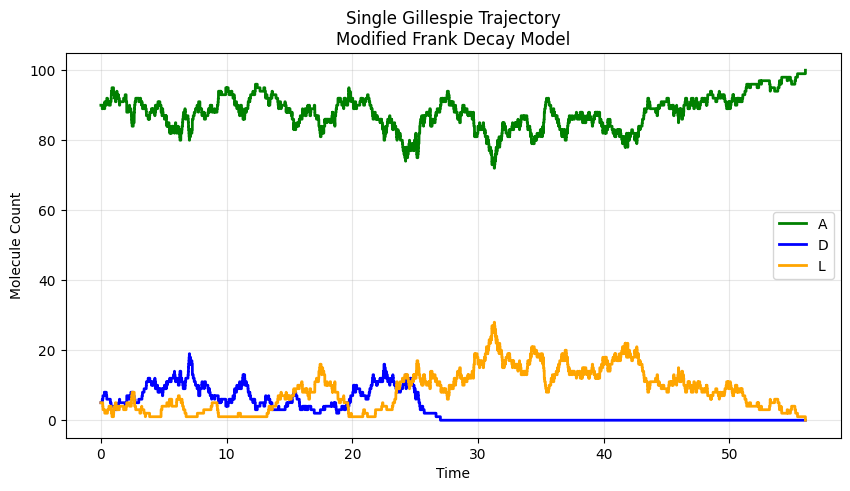

In [94]:
import matplotlib.pyplot as plt
import numpy as np
import random
import math

# ---------------------------------
# Parameters
# ---------------------------------

ka = 1.0
kd = 0.9

Vol = 100

A = 90
D = 5
L = 5

t = 0.0
tmax = 10000

# ---------------------------------
# Storage
# ---------------------------------

times = [0]
A_hist = [A]
D_hist = [D]
L_hist = [L]

# ---------------------------------
# Gillespie SSA
# ---------------------------------

while t < tmax:

    # Propensities

    a1 = ka*A*D/Vol      # A + D -> 2D
    a2 = ka*A*L/Vol      # A + L -> 2L
    a3 = kd*D            # D -> A
    a4 = kd*L            # L -> A

    a0 = a1 + a2 + a3 + a4

    if a0 == 0:
        break

    # Waiting time

    r1 = random.random()
    tau = -math.log(r1)/a0
    t += tau

    # Reaction selection

    r2 = random.random()*a0

    if r2 < a1:

        # A + D -> 2D
        A -= 1
        D += 1

    elif r2 < a1+a2:

        # A + L -> 2L
        A -= 1
        L += 1

    elif r2 < a1+a2+a3:

        # D -> A
        D -= 1
        A += 1

    else:

        # L -> A
        L -= 1
        A += 1

    # Record state

    times.append(t)
    A_hist.append(A)
    D_hist.append(D)
    L_hist.append(L)

# ---------------------------------
# Plot
# ---------------------------------

plt.figure(figsize=(10,5))

plt.step(times, A_hist, where='post',
         linewidth=2,
         color='green',
         label='A')

plt.step(times, D_hist, where='post',
         linewidth=2,
         color='blue',
         label='D')

plt.step(times, L_hist, where='post',
         linewidth=2,
         color='orange',
         label='L')

plt.xlabel("Time")
plt.ylabel("Molecule Count")
plt.title("Single Gillespie Trajectory\nModified Frank Decay Model")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

# Deterministic Analysis for the Decay Model

## Case:

$$
k_a=1,\qquad k_d=0.1
$$

---

# Reduced Equations

The governing equations are

$$
\frac{dD}{dt}=k_aAD-k_dD,
$$

$$
\frac{dL}{dt}=k_aAL-k_dL.
$$

Using the conservation relation

$$
A+D+L=1,
$$

we substitute

$$
A=1-D-L.
$$

The reduced equations become

$$
\frac{dD}{dt}
=
D(1-D-L)-0.1D,
$$

$$
\frac{dL}{dt}
=
L(1-D-L)-0.1L.
$$

Simplifying,

$$
\boxed{
\frac{dD}{dt}
=
D(0.9-D-L),
}
$$

$$
\boxed{
\frac{dL}{dt}
=
L(0.9-D-L).
}
$$

---

# Nullclines

## D-nullclines

Setting

$$
\frac{dD}{dt}=0,
$$

gives

$$
D(0.9-D-L)=0.
$$

Hence,

$$
\boxed{D=0}
$$

or

$$
\boxed{D+L=0.9.}
$$

---

## L-nullclines

Setting

$$
\frac{dL}{dt}=0,
$$

gives

$$
L(0.9-D-L)=0.
$$

Hence,

$$
\boxed{L=0}
$$

or

$$
\boxed{D+L=0.9.}
$$

---

# Equilibrium Points

The nullclines intersect at

## 1. Achiral equilibrium

$$
\boxed{(D,L)=(0,0).}
$$

---

## 2. Non-trivial equilibrium manifold

Since both non-trivial nullclines coincide,

$$
\boxed{D+L=0.9.}
$$

Thus every point

$$
\boxed{
(D,L)=
\left(D,\;0.9-D\right),
\qquad
0\le D\le0.9,
}
$$

is an equilibrium.

Using

$$
A=1-D-L,
$$

the corresponding full equilibrium manifold is

$$
\boxed{
(A,D,L)=
\left(
0.1,\;
D,\;
0.9-D
\right).
}
$$

---

# Jacobian Matrix

Define

$$
f(D,L)=D(0.9-D-L),
$$

$$
g(D,L)=L(0.9-D-L).
$$

The Jacobian is

$$
J(D,L)=
\begin{pmatrix}
\dfrac{\partial f}{\partial D} &
\dfrac{\partial f}{\partial L}\\[2mm]
\dfrac{\partial g}{\partial D} &
\dfrac{\partial g}{\partial L}
\end{pmatrix}.
$$

Evaluating the partial derivatives,

$$
\frac{\partial f}{\partial D}
=
0.9-2D-L,
$$

$$
\frac{\partial f}{\partial L}
=
-D,
$$

$$
\frac{\partial g}{\partial D}
=
-L,
$$

$$
\frac{\partial g}{\partial L}
=
0.9-D-2L.
$$

Therefore,

$$
\boxed{
J(D,L)=
\begin{pmatrix}
0.9-2D-L & -D\\[2mm]
-L & 0.9-D-2L
\end{pmatrix}.
}
$$

---

# Stability of the Achiral Equilibrium

Evaluating the Jacobian at

$$
(D,L)=(0,0),
$$

gives

$$
J(0,0)=
\begin{pmatrix}
0.9&0\\
0&0.9
\end{pmatrix}.
$$

The characteristic equation is

$$
\det(J-\lambda I)=0,
$$

or

$$
\left|
\begin{matrix}
0.9-\lambda&0\\
0&0.9-\lambda
\end{matrix}
\right|=0.
$$

Hence,

$$
\boxed{
\lambda_1=\lambda_2=0.9.
}
$$

Since both eigenvalues are positive,

$$
\boxed{
(D,L)=(0,0)
}
$$

is an **unstable node (unstable source).**

---

# Stability of the Equilibrium Manifold

On the equilibrium manifold,

$$
D+L=0.9,
$$

we write

$$
L=0.9-D.
$$

Substituting into the Jacobian,

$$
J=
\begin{pmatrix}
-D & -D\\[2mm]
D-0.9 & D-0.9
\end{pmatrix}.
$$

---

## Eigenvalue Analysis

The characteristic equation is

$$
\det(J-\lambda I)=0.
$$

Subtracting

$$
\lambda I,
$$

gives

$$
J-\lambda I=
\begin{pmatrix}
-D-\lambda & -D\\[2mm]
D-0.9 & D-0.9-\lambda
\end{pmatrix}.
$$

Taking the determinant,

$$
(-D-\lambda)(D-0.9-\lambda)
-
(-D)(D-0.9)=0.
$$

Since

$$
-(-D)(D-0.9)
=
+D(D-0.9),
$$

we obtain

$$
(-D-\lambda)(D-0.9-\lambda)
+
D(D-0.9)=0.
$$

Expanding,

$$
-D^2+0.9D+D\lambda
-\lambda D+0.9\lambda+\lambda^2
+D^2-0.9D=0.
$$

The terms

$$
-D^2+D^2=0,
$$

$$
0.9D-0.9D=0,
$$

and

$$
D\lambda-\lambda D=0
$$

cancel identically, leaving

$$
\lambda^2+0.9\lambda=0.
$$

Factoring,

$$
\lambda(\lambda+0.9)=0.
$$

Hence,

$$
\boxed{
\lambda_1=0,
\qquad
\lambda_2=-0.9.
}
$$

---

# Stability Conclusion

The equilibrium manifold possesses one zero eigenvalue and one negative eigenvalue.

The zero eigenvalue indicates that the manifold is **non-hyperbolic**, while the negative eigenvalue shows that perturbations perpendicular to the manifold decay exponentially.

Therefore,

$$
\boxed{
D+L=0.9
}
$$

is a **non-hyperbolic attracting equilibrium manifold**.

Trajectories are attracted toward the manifold but experience no restoring force along it. Consequently, the deterministic dynamics converge to some point on the manifold, with the final equilibrium determined by the initial ratio of the two enantiomers.

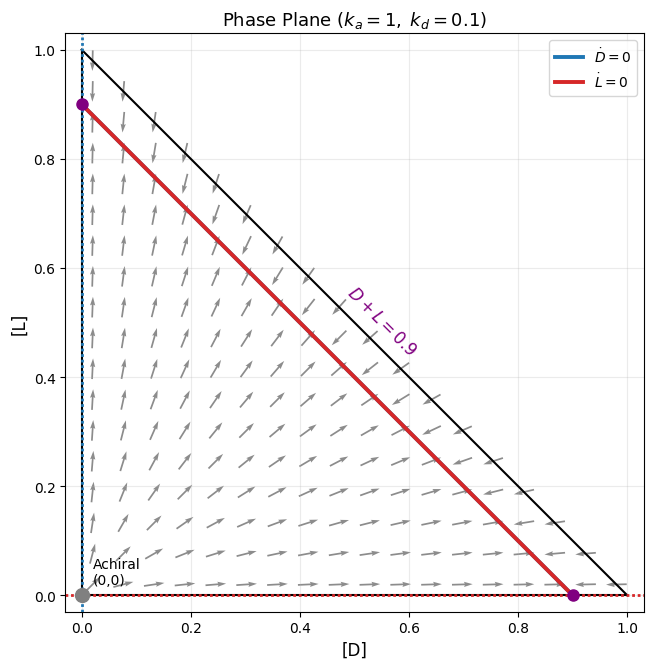

In [97]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------
# Reduced System
# ka = 1.0
# kd = 0.1
# ----------------------------------------

def dD(D, L):
    return D * (0.9 - D - L)

def dL(D, L):
    return L * (0.9 - D - L)

fig, ax = plt.subplots(figsize=(6.8,6.8))

# ---------------------------------------------------
# Vector field
# ---------------------------------------------------

n = 18

Dg = np.linspace(0.02,0.98,n)
Lg = np.linspace(0.02,0.98,n)

DD,LL = np.meshgrid(Dg,Lg)

mask = (DD+LL)<=1

U = dD(DD,LL)
V = dL(DD,LL)

speed = np.sqrt(U**2+V**2)
speed[speed==0]=1

U = np.where(mask,U/speed,np.nan)
V = np.where(mask,V/speed,np.nan)

ax.quiver(
    DD,
    LL,
    U,
    V,
    color='0.55',
    pivot='mid',
    scale=28,
    width=0.003
)

# ---------------------------------------------------
# Simplex Boundary
# ---------------------------------------------------

ax.plot([0,1],[0,0],'k',lw=1.5)
ax.plot([0,0],[0,1],'k',lw=1.5)
ax.plot([0,1],[1,0],'k',lw=1.5)

# ---------------------------------------------------
# D-nullclines
# ---------------------------------------------------

x = np.linspace(0,1,400)

Dnull = 0.9-x

valid = (
    (Dnull>=0) &
    (Dnull<=1) &
    (x+Dnull<=1)
)

ax.plot(
    x[valid],
    Dnull[valid],
    color='#1f77b4',
    lw=2.8,
    label=r'$\dot D=0$'
)

ax.axvline(
    0,
    color='#1f77b4',
    lw=2,
    linestyle=(0,(1,1))
)

# ---------------------------------------------------
# L-nullclines
# ---------------------------------------------------

Lnull = 0.9-x

valid = (
    (Lnull>=0) &
    (Lnull<=1) &
    (x+Lnull<=1)
)

ax.plot(
    x[valid],
    Lnull[valid],
    color='#d62728',
    lw=2.8,
    label=r'$\dot L=0$'
)

ax.axhline(
    0,
    color='#d62728',
    lw=2,
    linestyle=(0,(1,1))
)

# ---------------------------------------------------
# Equilibria
# ---------------------------------------------------

ax.plot(
    0,
    0,
    'o',
    color='gray',
    markersize=10
)

ax.annotate(
    'Achiral\n(0,0)',
    (0,0),
    xytext=(8,8),
    textcoords='offset points'
)

# Endpoints of equilibrium manifold

ax.plot(
    0.9,
    0,
    'o',
    color='purple',
    markersize=8
)

ax.plot(
    0,
    0.9,
    'o',
    color='purple',
    markersize=8
)

ax.text(
    0.48,
    0.44,
    r'$D+L=0.9$',
    color='purple',
    fontsize=12,
    rotation=-45,
    weight='bold'
)

# ---------------------------------------------------

ax.set_xlim(-0.03,1.03)
ax.set_ylim(-0.03,1.03)

ax.set_xlabel('[D]',fontsize=12)
ax.set_ylabel('[L]',fontsize=12)

ax.set_title(
    r'Phase Plane ($k_a=1,\;k_d=0.1$)',
    fontsize=13
)

ax.set_aspect('equal')

ax.grid(alpha=0.25)

ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

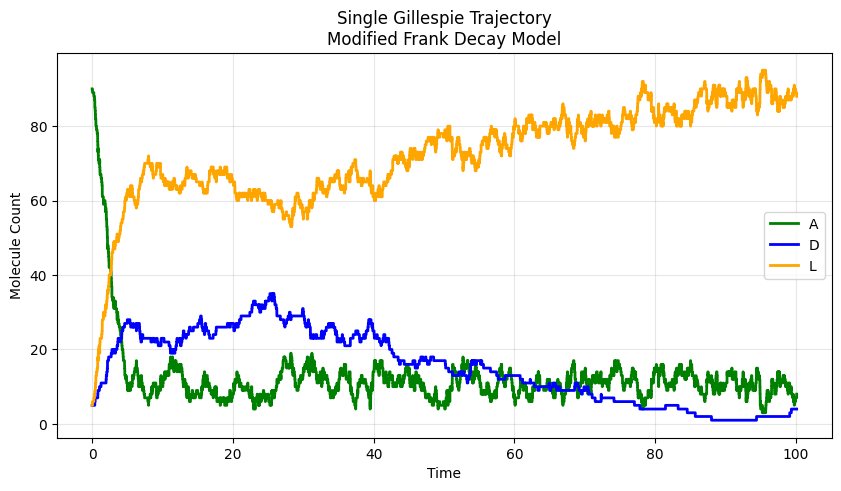

In [96]:
import matplotlib.pyplot as plt
import numpy as np
import random
import math

# ---------------------------------
# Parameters
# ---------------------------------

ka = 1.0
kd = 0.1

Vol = 100

A = 90
D = 5
L = 5

t = 0.0
tmax = 100

# ---------------------------------
# Storage
# ---------------------------------

times = [0]
A_hist = [A]
D_hist = [D]
L_hist = [L]

# ---------------------------------
# Gillespie SSA
# ---------------------------------

while t < tmax:

    # Propensities

    a1 = ka*A*D/Vol      # A + D -> 2D
    a2 = ka*A*L/Vol      # A + L -> 2L
    a3 = kd*D            # D -> A
    a4 = kd*L            # L -> A

    a0 = a1 + a2 + a3 + a4

    if a0 == 0:
        break

    # Waiting time

    r1 = random.random()
    tau = -math.log(r1)/a0
    t += tau

    # Reaction selection

    r2 = random.random()*a0

    if r2 < a1:

        # A + D -> 2D
        A -= 1
        D += 1

    elif r2 < a1+a2:

        # A + L -> 2L
        A -= 1
        L += 1

    elif r2 < a1+a2+a3:

        # D -> A
        D -= 1
        A += 1

    else:

        # L -> A
        L -= 1
        A += 1

    # Record state

    times.append(t)
    A_hist.append(A)
    D_hist.append(D)
    L_hist.append(L)

# ---------------------------------
# Plot
# ---------------------------------

plt.figure(figsize=(10,5))

plt.step(times, A_hist, where='post',
         linewidth=2,
         color='green',
         label='A')

plt.step(times, D_hist, where='post',
         linewidth=2,
         color='blue',
         label='D')

plt.step(times, L_hist, where='post',
         linewidth=2,
         color='orange',
         label='L')

plt.xlabel("Time")
plt.ylabel("Molecule Count")
plt.title("Single Gillespie Trajectory\nModified Frank Decay Model")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

# Modified Frank Model

## Reaction System

The modified reaction system proposed by Jafarpour et al. consists of two
autocatalytic reactions and four linear production and decay reactions:

$$
A+D \xrightarrow{k_a} 2D,
\qquad
A+L \xrightarrow{k_a} 2L,
$$

$$
A \xrightarrow{k_n} D,
\qquad
D \xrightarrow{k_d} A,
$$

$$
A \xrightarrow{k_n} L,
\qquad
L \xrightarrow{k_d} A.
$$

The autocatalytic reactions describe the self-replication of the two
enantiomers. The reactions $A\rightarrow D$ and $A\rightarrow L$ describe
nonautocatalytic production, while $D\rightarrow A$ and $L\rightarrow A$
represent decay and recycling.

The main modification from the original Frank model is the removal of the
chiral inhibition reaction

$$
D+L \rightarrow 2A.
$$

Instead, chiral molecules are produced and removed through the linear
reactions given above.

---

# Mean-Field Equations

Let the concentrations of the three molecular species be

$$
a=[A],
\qquad
d=[D],
\qquad
l=[L].
$$

The mean-field equations are obtained using the law of mass action.

---

## Equation for $A$

The concentration of $A$ decreases through the two autocatalytic reactions
and the two nonautocatalytic production reactions.

It increases through the decay of $D$ and $L$.

Therefore,

$$
\frac{da}{dt}
=
k_d d+k_d l
-k_n a-k_n a
-k_a ad-k_a al.
$$

Simplifying,

$$
\boxed{
\frac{da}{dt}
=
k_d(d+l)
-2k_n a
-k_a a(d+l)
}
$$

---

## Equation for $D$

The concentration of $D$ increases through autocatalytic production and
nonautocatalytic production.

It decreases through the decay reaction $D\rightarrow A$.

Therefore,

$$
\frac{dd}{dt}
=
k_a ad+k_n a-k_d d.
$$

Hence,

$$
\boxed{
\frac{dd}{dt}
=
k_a ad+k_n a-k_d d
}
$$

or equivalently,

$$
\boxed{
\frac{dd}{dt}
=
a(k_n+k_a d)-k_d d.
}
$$

---

## Equation for $L$

Similarly, the concentration of $L$ increases through autocatalytic and
nonautocatalytic production and decreases through decay.

Thus,

$$
\frac{dl}{dt}
=
k_a al+k_n a-k_d l.
$$

Hence,

$$
\boxed{
\frac{dl}{dt}
=
k_a al+k_n a-k_d l
}
$$

or equivalently,

$$
\boxed{
\frac{dl}{dt}
=
a(k_n+k_a l)-k_d l.
}
$$

---

# Complete Mean-Field System

The complete deterministic mean-field equations are therefore

$$
\boxed{
\frac{da}{dt}
=
k_d(d+l)
-2k_n a
-k_a a(d+l)
}
$$

$$
\boxed{
\frac{dd}{dt}
=
k_a ad+k_n a-k_d d
}
$$

$$
\boxed{
\frac{dl}{dt}
=
k_a al+k_n a-k_d l
}
$$

---

# Conservation Relation

Adding the three mean-field equations gives

$$
\frac{d}{dt}(a+d+l)=0.
$$

Therefore, the total concentration of molecules is conserved:

$$
\boxed{
a+d+l=n
}
$$

where $n$ is a constant.

For convenience, the total concentration can be normalized to

$$
\boxed{
a+d+l=1.
}
$$

Therefore,

$$
\boxed{
a=1-d-l.
}
$$

This allows the three-dimensional system to be reduced to two independent
variables.

---

# Reduced Mean-Field Equations

Substituting

$$
a=1-d-l
$$

into the equation for $D$ gives

$$
\frac{dd}{dt}
=
k_a(1-d-l)d
+k_n(1-d-l)
-k_d d.
$$

Therefore,

$$
\boxed{
\frac{dd}{dt}
=
k_a d(1-d-l)
+k_n(1-d-l)
-k_d d.
}
$$

Similarly, substituting

$$
a=1-d-l
$$

into the equation for $L$ gives

$$
\frac{dl}{dt}
=
k_a(1-d-l)l
+k_n(1-d-l)
-k_d l.
$$

Therefore,

$$
\boxed{
\frac{dl}{dt}
=
k_a l(1-d-l)
+k_n(1-d-l)
-k_d l.
}
$$

The reduced deterministic system is therefore

$$
\boxed{
\frac{dd}{dt}
=
k_a d(1-d-l)
+k_n(1-d-l)
-k_d d
}
$$

$$
\boxed{
\frac{dl}{dt}
=
k_a l(1-d-l)
+k_n(1-d-l)
-k_d l.
}
$$

---

# Chiral Order Parameter

The degree of chirality is described by the order parameter

$$
\boxed{
\omega
=
\frac{d-l}{d+l}.
}
$$

The important limiting cases are

$$
\omega=0
\qquad
\text{for the racemic state},
$$

$$
\omega=1
\qquad
\text{for the $D$-homochiral state},
$$

and

$$
\omega=-1
\qquad
\text{for the $L$-homochiral state}.
$$

---

# Deterministic Interpretation

Unlike the original Frank model, the modified reaction system contains no
chiral inhibition reaction of the form

$$
D+L\rightarrow2A.
$$

Consequently, there is no direct nonlinear interaction between the two
enantiomers.

The deterministic dynamics therefore do not produce the spontaneous
symmetry breaking present in the original Frank model.

Instead, the racemic state is the stable deterministic state.

The emergence of homochirality in this model therefore requires the
stochastic treatment of the chemical reactions.

This motivates the derivation of the master equation, followed by the
Fokker--Planck equation and the corresponding Langevin equation.

# Deterministic Analysis of the Modified Frank Model

We consider the modified reaction system

$$
A+D \xrightarrow{k_a} 2D
$$

$$
A+L \xrightarrow{k_a} 2L
$$

$$
A \xrightarrow{k_n} D
$$

$$
A \xrightarrow{k_n} L
$$

$$
D \xrightarrow{k_d} A
$$

$$
L \xrightarrow{k_d} A
$$

The corresponding mean-field equations are

$$
\frac{da}{dt}
=
k_d(d+l)-2k_n a-k_a a(d+l)
$$

$$
\frac{dd}{dt}
=
k_aad+k_na-k_dd
$$

$$
\frac{dl}{dt}
=
kaal+k_na-k_dl
$$

The total concentration is conserved:

$$
a+d+l=n
$$

For convenience, we normalize the total concentration to

$$
a+d+l=1
$$

---

# 1. Eliminate $A$

From the conservation condition,

$$
a=1-d-l
$$

Substituting this into the equations for $d$ and $l$, we obtain

$$
\frac{dd}{dt}
=
k_a(1-d-l)d+k_n(1-d-l)-k_dd
$$

and

$$
\frac{dl}{dt}
=
k_a(1-d-l)l+k_n(1-d-l)-k_dl
$$

We now choose

$$
k_a=k_d=k_n=1
$$

Therefore,

$$
\frac{dd}{dt}
=
(1-d-l)d+(1-d-l)-d
$$

and

$$
\frac{dl}{dt}
=
(1-d-l)l+(1-d-l)-l
$$

---

# 2. Simplify the Mean-Field Equations

For the $D$ equation,

$$
\frac{dd}{dt}
=
d-d^2-dl+1-d-l-d
$$

Therefore,

$$
\boxed{
\frac{dd}{dt}
=
1-d-l-d^2-dl
}
$$

Similarly, for the $L$ equation,

$$
\frac{dl}{dt}
=
l-dl-l^2+1-d-l-l
$$

giving

$$
\boxed{
\frac{dl}{dt}
=
1-d-l-dl-l^2
}
$$

Define

$$
f(d,l)=1-d-l-d^2-dl
$$

and

$$
g(d,l)=1-d-l-dl-l^2
$$

so that

$$
\frac{dd}{dt}=f(d,l)
$$

and

$$
\frac{dl}{dt}=g(d,l)
$$

---

# 3. Construct the Jacobian Matrix

The Jacobian matrix is

$$
J(d,l)
=
\begin{pmatrix}
\frac{\partial f}{\partial d}
&
\frac{\partial f}{\partial l}
\\
\frac{\partial g}{\partial d}
&
\frac{\partial g}{\partial l}
\end{pmatrix}
$$

We calculate each element separately.

For the first element,

$$
\frac{\partial f}{\partial d}
=
-1-2d-l
$$

For the second element,

$$
\frac{\partial f}{\partial l}
=
-1-d
$$

For the third element,

$$
\frac{\partial g}{\partial d}
=
-1-l
$$

For the fourth element,

$$
\frac{\partial g}{\partial l}
=
-1-d-2l
$$

Therefore, the Jacobian is

$$
\boxed{
J(d,l)
=
\begin{pmatrix}
-1-2d-l & -1-d\\
-1-l & -1-d-2l
\end{pmatrix}
}
$$

---

# 4. Find the Nullclines

At an equilibrium point,

$$
\frac{dd}{dt}=0
$$

and

$$
\frac{dl}{dt}=0
$$

Therefore, the $D$-nullcline is obtained from

$$
1-d-l-d^2-dl=0
$$

or

$$
\boxed{
1-d-l-d^2-dl=0
}
$$

The $L$-nullcline is

$$
1-d-l-dl-l^2=0
$$

or

$$
\boxed{
1-d-l-dl-l^2=0
}
$$

The equilibrium points are therefore the intersections of these two nullclines.

---

# 5. Equate the Two Nullclines

We have

$$
1-d-l-d^2-dl=0
$$

and

$$
1-d-l-dl-l^2=0
$$

Subtracting the second equation from the first gives

$$
-d^2+l^2=0
$$

Therefore,

$$
l^2-d^2=0
$$

Using the difference of squares,

$$
(l-d)(l+d)=0
$$

Thus, there are two possible cases:

$$
\boxed{l=d}
$$

or

$$
\boxed{l=-d}
$$

---

# 6. Case 1: $l=d$

Substitute

$$
l=d
$$

into the $D$-nullcline:

$$
1-d-d-d^2-d^2=0
$$

Therefore,

$$
1-2d-2d^2=0
$$

Rearranging,

$$
2d^2+2d-1=0
$$

Using the quadratic formula,

$$
d
=
\frac{-2\pm\sqrt{4+8}}{4}
$$

which gives

$$
d
=
\frac{-2\pm\sqrt{12}}{4}
$$

and hence

$$
d
=
\frac{-1\pm\sqrt{3}}{2}
$$

Since $l=d$,

$$
l
=
\frac{-1\pm\sqrt{3}}{2}
$$

Therefore, the two mathematical equilibrium points are

$$
\boxed{
(d^*,l^*)
=
\left(
\frac{\sqrt{3}-1}{2},
\frac{\sqrt{3}-1}{2}
\right)
}
$$

and

$$
\boxed{
(d^*,l^*)
=
\left(
-\frac{1+\sqrt{3}}{2},
-\frac{1+\sqrt{3}}{2}
\right)
}
$$

---

# 7. Case 2: $l=-d$

Now consider

$$
l=-d
$$

Substituting into the $D$-nullcline gives

$$
1-d-(-d)-d^2-d(-d)=0
$$

Therefore,

$$
1-d+d-d^2+d^2=0
$$

which reduces to

$$
1=0
$$

This is impossible.

Therefore, the case

$$
l=-d
$$

does not produce an equilibrium point.

Hence, there are exactly

$$
\boxed{2}
$$

mathematical equilibrium points.

---

# 8. Physical Equilibrium

Concentrations cannot be negative.

Therefore, the equilibrium

$$
\left(
-\frac{1+\sqrt{3}}{2},
-\frac{1+\sqrt{3}}{2}
\right)
$$

is physically meaningless.

The only physically meaningful equilibrium is

$$
\boxed{
d^*=l^*
=
\frac{\sqrt{3}-1}{2}
}
$$

Numerically,

$$
d^*=l^*\approx0.366025
$$

Using

$$
a+d+l=1
$$

we obtain

$$
a^*
=
1-d^*-l^*
$$

Therefore,

$$
a^*
=
1-\frac{\sqrt{3}-1}{2}
-\frac{\sqrt{3}-1}{2}
$$

which simplifies to

$$
\boxed{
a^*=2-\sqrt{3}
}
$$

Numerically,

$$
a^*\approx0.267949
$$

Thus the physical equilibrium is

$$
\boxed{
(a^*,d^*,l^*)
=
\left(
2-\sqrt{3},
\frac{\sqrt{3}-1}{2},
\frac{\sqrt{3}-1}{2}
\right)
}
$$

This equilibrium is racemic because

$$
d^*=l^*
$$

---

# 9. Evaluate the Jacobian at the Physical Equilibrium

The general Jacobian is

$$
J(d,l)
=
\begin{pmatrix}
-1-2d-l & -1-d\\
-1-l & -1-d-2l
\end{pmatrix}
$$

At the equilibrium,

$$
d^*=l^*=\frac{\sqrt{3}-1}{2}
$$

Therefore,

$$
J^*
=
\begin{pmatrix}
-1-3d^* & -1-d^*\\
-1-d^* & -1-3d^*
\end{pmatrix}
$$

Now substitute

$$
d^*=\frac{\sqrt{3}-1}{2}
$$

For the diagonal elements,

$$
-1-3d^*
=
-1-\frac{3(\sqrt{3}-1)}{2}
$$

$$
=
\frac{1-3\sqrt{3}}{2}
$$

For the off-diagonal elements,

$$
-1-d^*
=
-1-\frac{\sqrt{3}-1}{2}
$$

$$
=
-\frac{1+\sqrt{3}}{2}
$$

Therefore,

$$
\boxed{
J^*
=
\begin{pmatrix}
\frac{1-3\sqrt{3}}{2}
&
-\frac{1+\sqrt{3}}{2}
\\
-\frac{1+\sqrt{3}}{2}
&
\frac{1-3\sqrt{3}}{2}
\end{pmatrix}
}
$$

---

# 10. Eigenvalues

The eigenvalues satisfy

$$
\det(J^*-\lambda I)=0
$$

Therefore,

$$
\begin{vmatrix}
\frac{1-3\sqrt{3}}{2}-\lambda
&
-\frac{1+\sqrt{3}}{2}
\\
-\frac{1+\sqrt{3}}{2}
&
\frac{1-3\sqrt{3}}{2}-\lambda
\end{vmatrix}
=0
$$

The determinant gives

$$
\left(
\frac{1-3\sqrt{3}}{2}-\lambda
\right)^2
-
\left(
\frac{1+\sqrt{3}}{2}
\right)^2
=0
$$

Therefore,

$$
\frac{1-3\sqrt{3}}{2}-\lambda
=
\pm
\frac{1+\sqrt{3}}{2}
$$

This gives the two eigenvalues

$$
\boxed{
\lambda_1=-2\sqrt{3}
}
$$

and

$$
\boxed{
\lambda_2=1-\sqrt{3}
}
$$

Numerically,

$$
\boxed{
\lambda_1\approx-3.4641
}
$$

and

$$
\boxed{
\lambda_2\approx-0.7321
}
$$

---

# 11. Eigenvectors

Because the Jacobian has the form

$$
J^*
=
\begin{pmatrix}
a&b\\
b&a
\end{pmatrix}
$$

the eigenvectors are particularly simple.

For

$$
\lambda_1=-2\sqrt{3}
$$

the corresponding eigenvector is

$$
\boxed{
v_1=
\begin{pmatrix}
1\\
1
\end{pmatrix}
}
$$

This corresponds to changing $D$ and $L$ in the same direction.

For

$$
\lambda_2=1-\sqrt{3}
$$

the corresponding eigenvector is

$$
\boxed{
v_2=
\begin{pmatrix}
1\\
-1
\end{pmatrix}
}
$$

This corresponds to changing $D$ and $L$ in opposite directions.

---

# 12. Stability of the Equilibrium

Both eigenvalues are negative:

$$
\lambda_1=-2\sqrt{3}<0
$$

and

$$
\lambda_2=1-\sqrt{3}<0
$$

Therefore, perturbations in both directions decay with time.

Hence, the physical equilibrium is a

$$
\boxed{\text{stable node}}
$$

The deterministic system therefore returns to the racemic state after a small perturbation.

In particular, the antisymmetric perturbation

$$
v_2=
\begin{pmatrix}
1\\
-1
\end{pmatrix}
$$

represents a perturbation toward $D\neq L$, i.e. a perturbation in chirality.

Since its eigenvalue is

$$
\lambda_2=1-\sqrt{3}<0
$$

the deterministic dynamics suppresses this chiral asymmetry and returns the system toward

$$
D=L
$$

This is important for the modified Frank model because the paper's central result is that deterministically the racemic state is stable, while stochastic fluctuations can produce symmetry breaking and homochirality.

---

# 13. Final Results

The reduced deterministic equations are

$$
\boxed{
\frac{dd}{dt}=1-d-l-d^2-dl
}
$$

$$
\boxed{
\frac{dl}{dt}=1-d-l-dl-l^2
}
$$

The Jacobian is

$$
\boxed{
J(d,l)
=
\begin{pmatrix}
-1-2d-l & -1-d\\
-1-l & -1-d-2l
\end{pmatrix}
}
$$

The nullcline intersections give two mathematical points:

$$
\boxed{
(d^*,l^*)
=
\left(
\frac{\sqrt{3}-1}{2},
\frac{\sqrt{3}-1}{2}
\right)
}
$$

and

$$
\boxed{
(d^*,l^*)
=
\left(
-\frac{1+\sqrt{3}}{2},
-\frac{1+\sqrt{3}}{2}
\right)
}
$$

Only the first is physically meaningful.

Thus,

$$
\boxed{
(a^*,d^*,l^*)
=
\left(
2-\sqrt{3},
\frac{\sqrt{3}-1}{2},
\frac{\sqrt{3}-1}{2}
\right)
}
$$

with eigenvalues

$$
\boxed{
\lambda_1=-2\sqrt{3}\approx-3.4641
}
$$

and

$$
\boxed{
\lambda_2=1-\sqrt{3}\approx-0.7321
}
$$

Therefore,

$$
\boxed{
\text{The physical racemic equilibrium is a stable node.}
}
$$

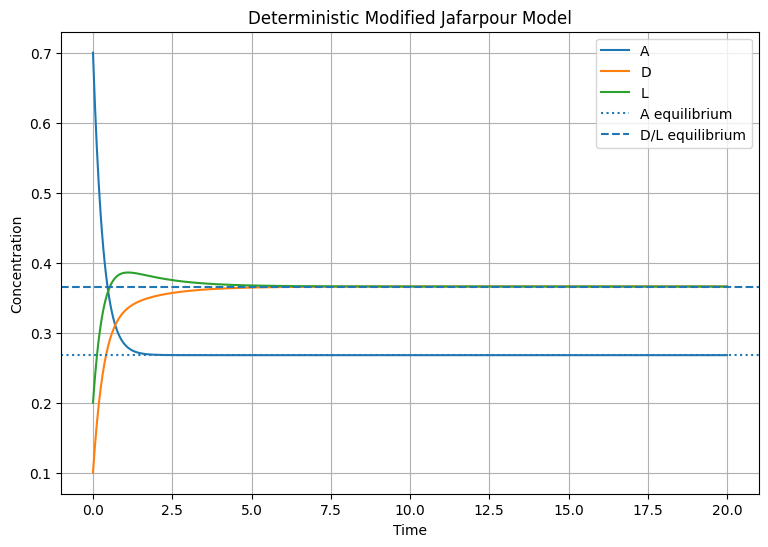

Final concentrations:
A = 0.267949
D = 0.366025
L = 0.366025

Theoretical equilibrium:
A* = 0.267949
D* = 0.366025
L* = 0.366025

Conservation check:
Initial A + D + L = 1.000000
Final A + D + L   = 1.000000
Maximum deviation = 1.11e-15


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# ============================================================
# Parameters
# ============================================================

k_a = 1.0
k_d = 1.0
k_n = 1.0


# ============================================================
# Coupled ODE system
# ============================================================

def modified_frank(t, y):

    a, d, l = y

    # Mean-field equations
    da_dt = k_d * (d + l) - 2 * k_n * a - k_a * a * (d + l)

    dd_dt = k_a * a * d + k_n * a - k_d * d

    dl_dt = k_a * a * l + k_n * a - k_d * l

    return [da_dt, dd_dt, dl_dt]


# ============================================================
# Initial conditions
# ============================================================

a0 = 0.70
d0 = 0.10
l0 = 0.20

y0 = [a0, d0, l0]


# ============================================================
# Time interval
# ============================================================

t_start = 0
t_end = 20

t_eval = np.linspace(t_start, t_end, 1000)


# ============================================================
# Solve the coupled ODEs
# ============================================================

solution = solve_ivp(
    modified_frank,
    [t_start, t_end],
    y0,
    t_eval=t_eval,
    method='RK45',
    rtol=1e-9,
    atol=1e-11
)


# ============================================================
# Extract solutions
# ============================================================

t = solution.t

a = solution.y[0]
d = solution.y[1]
l = solution.y[2]


# ============================================================
# Theoretical equilibrium
# ============================================================

a_eq = 2 - np.sqrt(3)

d_eq = (np.sqrt(3) - 1) / 2

l_eq = (np.sqrt(3) - 1) / 2


# ============================================================
# Plot concentrations
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(t, a, label='A')
plt.plot(t, d, label='D')
plt.plot(t, l, label='L')

plt.axhline(a_eq, linestyle=':', label='A equilibrium')
plt.axhline(d_eq, linestyle='--', label='D/L equilibrium')

plt.xlabel('Time')
plt.ylabel('Concentration')
plt.title('Deterministic Modified Jafarpour Model')

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# Print final values
# ============================================================

print("Final concentrations:")
print(f"A = {a[-1]:.6f}")
print(f"D = {d[-1]:.6f}")
print(f"L = {l[-1]:.6f}")

print("\nTheoretical equilibrium:")
print(f"A* = {a_eq:.6f}")
print(f"D* = {d_eq:.6f}")
print(f"L* = {l_eq:.6f}")


# ============================================================
# Conservation check
# ============================================================

total = a + d + l

print("\nConservation check:")
print(f"Initial A + D + L = {total[0]:.6f}")
print(f"Final A + D + L   = {total[-1]:.6f}")
print(f"Maximum deviation = {np.max(np.abs(total - total[0])):.2e}")

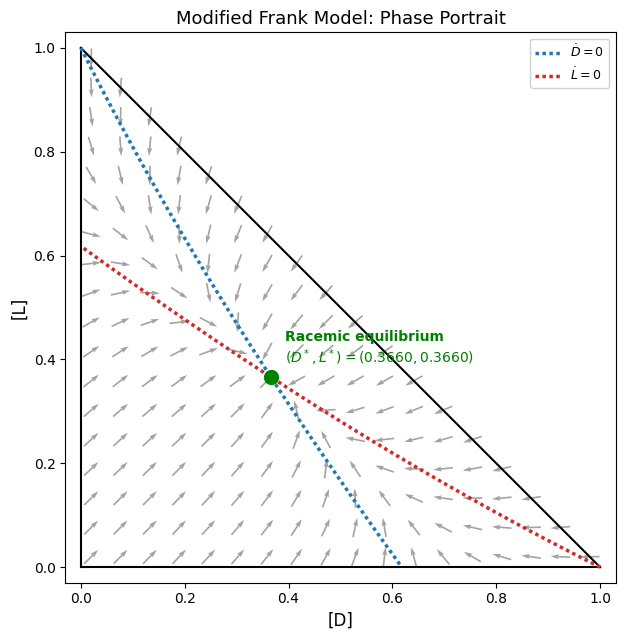

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------
# Vector field
# ---------------------------------

def dD(D, L):
    return 1 - D - L - D**2 - D*L

def dL(D, L):
    return 1 - D - L - D*L - L**2


fig, ax = plt.subplots(figsize=(6.5, 6.5))


# ---------------------------------
# Vector field
# ---------------------------------

n = 18

Dg = np.linspace(0.02, 0.98, n)
Lg = np.linspace(0.02, 0.98, n)

DD, LL = np.meshgrid(Dg, Lg)

# Physical region
mask = (DD + LL) <= 1.0

U = dD(DD, LL)
V = dL(DD, LL)

speed = np.sqrt(U**2 + V**2)
speed[speed == 0] = 1

Un = np.where(mask, U / speed, np.nan)
Vn = np.where(mask, V / speed, np.nan)

ax.quiver(
    DD,
    LL,
    Un,
    Vn,
    color='0.55',
    pivot='mid',
    scale=28,
    width=0.003,
    alpha=0.8
)


# ---------------------------------
# Simplex
# ---------------------------------

ax.plot(
    [0, 1],
    [0, 0],
    'k-',
    linewidth=1.5
)

ax.plot(
    [0, 0],
    [0, 1],
    'k-',
    linewidth=1.5
)

ax.plot(
    [0, 1],
    [1, 0],
    'k-',
    linewidth=1.5
)


# ---------------------------------
# Nullclines
# ---------------------------------

x = np.linspace(0, 1, 500)


# D-nullcline:
# 1 - D - L - D^2 - D*L = 0
#
# Solve for L:
#
# L = (1 - D - D^2) / (1 + D)

L_D = (1 - x - x**2) / (1 + x)

mask_D = (L_D >= 0) & ((x + L_D) <= 1)

ax.plot(
    x[mask_D],
    L_D[mask_D],
    color='#1f77b4',
    linewidth=2.5,
    linestyle=(0, (1, 1)),
    label=r'$\dot D=0$'
)


# L-nullcline:
# 1 - D - L - D*L - L^2 = 0
#
# Solve for D:
#
# D = (1 - L - L^2) / (1 + L)

D_L = (1 - x - x**2) / (1 + x)

mask_L = (D_L >= 0) & ((x + D_L) <= 1)

ax.plot(
    D_L[mask_L],
    x[mask_L],
    color='#d62728',
    linewidth=2.5,
    linestyle=(0, (1, 1)),
    label=r'$\dot L=0$'
)


# ---------------------------------
# Equilibrium
# ---------------------------------

D_eq = (np.sqrt(3) - 1) / 2
L_eq = (np.sqrt(3) - 1) / 2

ax.plot(
    D_eq,
    L_eq,
    'o',
    color='green',
    markersize=10,
    zorder=5
)

ax.annotate(
    r'Racemic equilibrium'
    '\n'
    r'$(D^*,L^*)=(0.3660,0.3660)$',
    (D_eq, L_eq),
    textcoords='offset points',
    xytext=(10, 10),
    fontsize=10,
    color='green',
    fontweight='bold'
)


# ---------------------------------
# Plot settings
# ---------------------------------

ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)

ax.set_xlabel('[D]', fontsize=12)
ax.set_ylabel('[L]', fontsize=12)

ax.set_title(
    "Modified Frank Model: Phase Portrait",
    fontsize=13
)

ax.set_aspect('equal')

ax.legend(
    loc='upper right',
    fontsize=9,
    framealpha=0.9
)

plt.tight_layout()
plt.show()

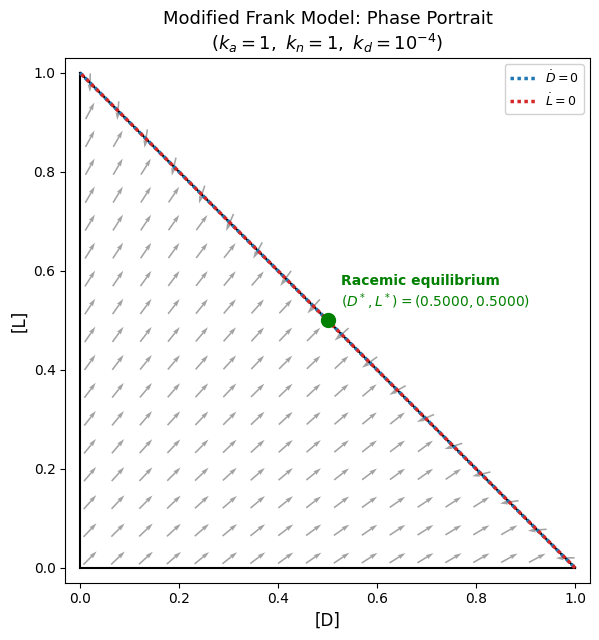

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------
# Vector field — Case 2
# ka = 1, kn = 1, kd = 0.0001, N = 1
# ---------------------------------

def dD(D, L):
    return 1 - 0.0001*D - L - D**2 - D*L

def dL(D, L):
    return 1 - D - 0.0001*L - D*L - L**2


fig, ax = plt.subplots(figsize=(6.5, 6.5))


# ---------------------------------
# Vector field
# ---------------------------------

n = 18

Dg = np.linspace(0.02, 0.98, n)
Lg = np.linspace(0.02, 0.98, n)

DD, LL = np.meshgrid(Dg, Lg)

# Physical region
mask = (DD + LL) <= 1.0
U = dD(DD, LL)
V = dL(DD, LL)

speed = np.sqrt(U**2 + V**2)
speed[speed == 0] = 1

Un = np.where(mask, U / speed, np.nan)
Vn = np.where(mask, V / speed, np.nan)

ax.quiver(
    DD,
    LL,
    Un,
    Vn,
    color='0.55',
    pivot='mid',
    scale=28,
    width=0.003,
    alpha=0.8
)


# ---------------------------------
# Simplex
# ---------------------------------

ax.plot([0, 1], [0, 0], 'k-', linewidth=1.5)
ax.plot([0, 0], [0, 1], 'k-', linewidth=1.5)
ax.plot([0, 1], [1, 0], 'k-', linewidth=1.5)


# ---------------------------------
# Nullclines
# ---------------------------------

x = np.linspace(0, 1, 500)

kd = 0.0001

# D-nullcline
L_D = (1 - kd*x - x**2) / (1 + x)

mask_D = (L_D >= 0) & ((x + L_D) <= 1)

ax.plot(
    x[mask_D],
    L_D[mask_D],
    color='#1f77b4',
    linewidth=2.5,
    linestyle=(0, (1, 1)),
    label=r'$\dot D=0$'
)


# L-nullcline
D_L = (1 - kd*x - x**2) / (1 + x)

mask_L = (D_L >= 0) & ((x + D_L) <= 1)

ax.plot(
    D_L[mask_L],
    x[mask_L],
    color='#d62728',
    linewidth=2.5,
    linestyle=(0, (1, 1)),
    label=r'$\dot L=0$'
)


# ---------------------------------
# Equilibrium
# ---------------------------------

# D = L = x
# 1 - (1 + kd)x - 2x^2 = 0

D_eq = (-(1 + kd) + np.sqrt((1 + kd)**2 + 8)) / 4
L_eq = D_eq

ax.plot(
    D_eq,
    L_eq,
    'o',
    color='green',
    markersize=10,
    zorder=5
)

ax.annotate(
    r'Racemic equilibrium'
    '\n'
    rf'$(D^*,L^*)=({D_eq:.4f},{L_eq:.4f})$',
    (D_eq, L_eq),
    textcoords='offset points',
    xytext=(10, 10),
    fontsize=10,
    color='green',
    fontweight='bold'
)


# ---------------------------------
# Plot settings
# ---------------------------------

ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)

ax.set_xlabel('[D]', fontsize=12)
ax.set_ylabel('[L]', fontsize=12)

ax.set_title(
    r"Modified Frank Model: Phase Portrait"
    "\n"
    r"$(k_a=1,\ k_n=1,\ k_d=10^{-4})$",
    fontsize=13
)

ax.set_aspect('equal')

ax.legend(
    loc='upper right',
    fontsize=9,
    framealpha=0.9
)

plt.tight_layout()
plt.show()


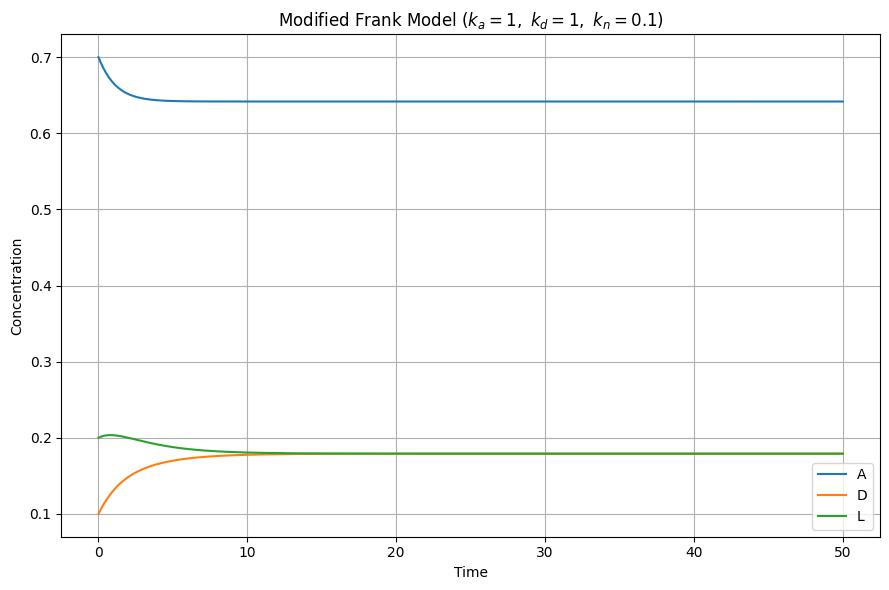

Initial total: 1.0
Final total: 1.0000000000000002
Maximum deviation: 4.440892098500626e-16

Final concentrations:
A = 0.64174243
D = 0.17912878
L = 0.17912879


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# ============================================================
# Parameters
# ============================================================

ka = 1.0
kd = 1.0
kn = 0.1


# ============================================================
# Coupled ODE system
# ============================================================

def modified_frank(t, y):

    A, D, L = y

    dA_dt = kd * (D + L) - 2 * kn * A - ka * A * (D + L)

    dD_dt = ka * A * D + kn * A - kd * D

    dL_dt = ka * A * L + kn * A - kd * L

    return [dA_dt, dD_dt, dL_dt]


# ============================================================
# Initial conditions
# ============================================================

A0 = 0.70
D0 = 0.10
L0 = 0.20

y0 = [A0, D0, L0]


# ============================================================
# Time interval
# ============================================================

t_start = 0
t_end = 50

t_eval = np.linspace(t_start, t_end, 2000)


# ============================================================
# Solve the coupled ODEs
# ============================================================

solution = solve_ivp(
    modified_frank,
    [t_start, t_end],
    y0,
    t_eval=t_eval,
    method='RK45',
    rtol=1e-9,
    atol=1e-11
)


# ============================================================
# Extract solutions
# ============================================================

t = solution.t

A = solution.y[0]
D = solution.y[1]
L = solution.y[2]


# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(t, A, label='A')
plt.plot(t, D, label='D')
plt.plot(t, L, label='L')

plt.xlabel('Time')
plt.ylabel('Concentration')

plt.title(
    r'Modified Frank Model ($k_a=1,\ k_d=1,\ k_n=0.1$)'
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# Conservation check
# ============================================================

total = A + D + L

print("Initial total:", total[0])
print("Final total:", total[-1])
print("Maximum deviation:", np.max(np.abs(total - total[0])))


# ============================================================
# Final concentrations
# ============================================================

print("\nFinal concentrations:")
print(f"A = {A[-1]:.8f}")
print(f"D = {D[-1]:.8f}")
print(f"L = {L[-1]:.8f}")

# Stability Analysis of the Modified Frank Model

For the parameter values

$$
k_a=1,\qquad k_n=1,\qquad k_d=0.0001
$$

we use the conservation condition

$$
A+D+L=1
$$

to eliminate $A$:

$$
A=1-D-L.
$$

---

## 1. Reduced Dynamical System

The equations for $D$ and $L$ become

$$
\boxed{
\frac{dD}{dt}
=
1-L-D^2-DL-0.0001D
}
$$

and

$$
\boxed{
\frac{dL}{dt}
=
1-D-DL-L^2-0.0001L
}
$$

Define

$$
f(D,L)=1-L-D^2-DL-0.0001D
$$

and

$$
g(D,L)=1-D-DL-L^2-0.0001L.
$$

---

## 2. Equilibrium

At equilibrium,

$$
f(D^*,L^*)=0
$$

and

$$
g(D^*,L^*)=0.
$$

Subtracting the two equations gives

$$
-0.0001D+0.0001L-D^2+L^2=0.
$$

Factoring,

$$
(L-D)(D+L+0.0001)=0.
$$

The physically meaningful solution is

$$
\boxed{D^*=L^*}.
$$

Let

$$
D^*=L^*=x.
$$

Substituting into the equilibrium equation gives

$$
1-x-2x^2-0.0001x=0.
$$

Therefore,

$$
2x^2+1.0001x-1=0.
$$

Using the quadratic formula,

$$
x=
\frac{-1.0001\pm\sqrt{(1.0001)^2+8}}{4}.
$$

The physical root is

$$
\boxed{
x=
\frac{-1.0001+\sqrt{(1.0001)^2+8}}{4}
}
$$

giving

$$
\boxed{
D^*=L^*\approx0.4999833337
}
$$

and therefore

$$
A^*=1-D^*-L^*
$$

so that

$$
\boxed{
A^*\approx0.0000333326
}.
$$

Thus, the equilibrium is

$$
\boxed{
(A^*,D^*,L^*)
\approx
(0.00003333,\;0.4999833,\;0.4999833)
}.
$$

---

## 3. Jacobian Matrix

The Jacobian is

$$
J(D,L)
=
\begin{pmatrix}
\dfrac{\partial f}{\partial D}
&
\dfrac{\partial f}{\partial L}
\\[6pt]
\dfrac{\partial g}{\partial D}
&
\dfrac{\partial g}{\partial L}
\end{pmatrix}.
$$

The individual derivatives are

$$
\frac{\partial f}{\partial D}
=
-2D-L-0.0001
$$

$$
\frac{\partial f}{\partial L}
=
-1-D
$$

$$
\frac{\partial g}{\partial D}
=
-1-L
$$

$$
\frac{\partial g}{\partial L}
=
-D-2L-0.0001.
$$

Therefore,

$$
\boxed{
J(D,L)=
\begin{pmatrix}
-2D-L-0.0001 & -1-D\\
-1-L & -D-2L-0.0001
\end{pmatrix}
}
$$

---

## 4. Jacobian at the Equilibrium

Since

$$
D^*=L^*=x,
$$

the Jacobian becomes

$$
J^*
=
\begin{pmatrix}
-3x-0.0001 & -1-x\\
-1-x & -3x-0.0001
\end{pmatrix}.
$$

Using

$$
x\approx0.4999833337,
$$

we obtain

$$
\boxed{
J^*
=
\begin{pmatrix}
-1.499950001 & -1.499983334\\
-1.499983334 & -1.499950001
\end{pmatrix}
}
$$

---

## 5. Eigenvalue Decomposition

The Jacobian has the form

$$
J^*=
\begin{pmatrix}
a&b\\
b&a
\end{pmatrix}.
$$

Therefore, the eigenvectors are

$$
\boxed{
v_1=
\begin{pmatrix}
1\\
1
\end{pmatrix}
}
$$

and

$$
\boxed{
v_2=
\begin{pmatrix}
1\\
-1
\end{pmatrix}
}.
$$

The corresponding eigenvalues are

$$
\lambda_1=a+b
$$

and

$$
\lambda_2=a-b.
$$

Here,

$$
a=-1.499950001
$$

and

$$
b=-1.499983334.
$$

Therefore,

$$
\lambda_1
=
-1.499950001-1.499983334
$$

giving

$$
\boxed{
\lambda_1\approx-3.00003333
}
$$

and

$$
\lambda_2
=
-1.499950001+1.499983334
$$

giving

$$
\boxed{
\lambda_2\approx-6.66674\times10^{-5}
}.
$$

---

## 6. Interpretation of the Eigenvectors

The first eigenvector is

$$
v_1=
\begin{pmatrix}
1\\
1
\end{pmatrix}.
$$

A perturbation in this direction changes $D$ and $L$ together:

$$
(D,L)\rightarrow(D+\epsilon,L+\epsilon).
$$

Thus, this direction corresponds approximately to motion along the

$$
D=L
$$

direction.

Since

$$
\lambda_1\approx-3.00003333,
$$

perturbations in this direction decay rapidly.

The corresponding characteristic timescale is

$$
\tau_1=\frac{1}{|\lambda_1|}
\approx0.3333.
$$

---

The second eigenvector is

$$
v_2=
\begin{pmatrix}
1\\
-1
\end{pmatrix}.
$$

A perturbation in this direction changes $D$ and $L$ in opposite directions:

$$
(D,L)\rightarrow(D+\epsilon,L-\epsilon).
$$

Therefore, this direction corresponds to a change in the difference between $D$ and $L$, representing a chiral asymmetry.

Since

$$
\lambda_2\approx-6.66674\times10^{-5},
$$

this perturbation also decays, but extremely slowly.

The corresponding characteristic timescale is

$$
\tau_2=\frac{1}{|\lambda_2|}
\approx15000.
$$

Thus,

$$
\boxed{
\tau_2\gg\tau_1
}.
$$

---

## 7. Stability Analysis

For linear stability, the equilibrium is stable when both eigenvalues have negative real parts.

Here,

$$
\lambda_1\approx-3.00003333<0
$$

and

$$
\lambda_2\approx-6.66674\times10^{-5}<0.
$$

Therefore,

$$
\boxed{
\lambda_1<0,\qquad\lambda_2<0
}
$$

and the equilibrium is linearly stable.

Since both eigenvalues are real and negative,

$$
\boxed{
\text{The equilibrium is a stable node.}
}
$$

---

## 8. Physical Interpretation

The two eigenvalues reveal two very different relaxation timescales.

For the direction associated with

$$
v_1=
\begin{pmatrix}
1\\
1
\end{pmatrix},
$$

the relaxation is rapid:

$$
\tau_1\approx0.3333.
$$

For the direction associated with

$$
v_2=
\begin{pmatrix}
1\\
-1
\end{pmatrix},
$$

the relaxation is extremely slow:

$$
\tau_2\approx15000.
$$

Therefore,

$$
\boxed{
\tau_2\gg\tau_1
}
$$

and the system rapidly approaches the region

$$
D\approx L,
$$

while the remaining chiral imbalance $D-L$ is removed only very slowly.

Thus, the deterministic system is stable against chiral asymmetry, but the restoring force in the chiral direction is extremely weak.

This makes the system particularly sensitive to stochastic fluctuations. Even though the deterministic dynamics eventually restore the racemic state,

$$
D=L,
$$

noise can produce substantial and long-lived deviations from this state because

$$
|\lambda_2|\ll|\lambda_1|.
$$

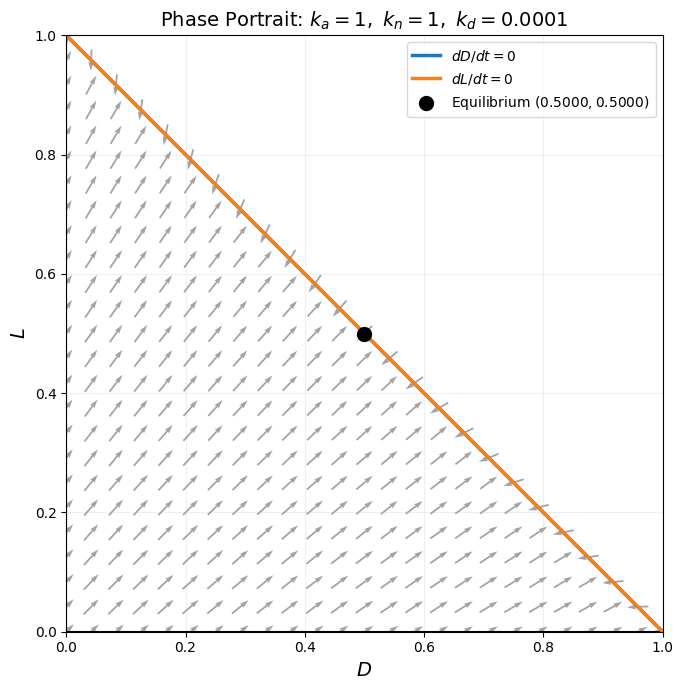

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Parameters
# ============================================================

ka = 1.0
kn = 1.0
kd = 0.0001


# ============================================================
# Reduced dynamical system
# A = 1 - D - L
# ============================================================

def dD(D, L):
    A = 1 - D - L
    return ka*A*D + kn*A - kd*D


def dL(D, L):
    A = 1 - D - L
    return ka*A*L + kn*A - kd*L


# ============================================================
# Grid for vector field
# ============================================================

n = 25

Dg = np.linspace(0, 1, n)
Lg = np.linspace(0, 1, n)

DD, LL = np.meshgrid(Dg, Lg)


# Calculate vector field
U = dD(DD, LL)
V = dL(DD, LL)


# Only show vectors inside physical region
mask = (DD + LL) <= 1


# Normalize vectors so arrows have similar lengths
speed = np.sqrt(U**2 + V**2)

speed[speed == 0] = 1

Un = np.where(mask, U / speed, np.nan)
Vn = np.where(mask, V / speed, np.nan)


# ============================================================
# Nullclines
# ============================================================

D_values = np.linspace(0, 1, 1000)
L_values = np.linspace(0, 1, 1000)


# dD/dt = 0
#
# 1 - L - D^2 - DL - kd*D = 0
#
# L(1 + D) = 1 - D^2 - kd*D
#
# L = (1 - D^2 - kd*D)/(1 + D)

L_null = (
    1 - D_values**2 - kd*D_values
) / (1 + D_values)


# dL/dt = 0
#
# 1 - D - DL - L^2 - kd*L = 0
#
# D(1 + L) = 1 - L^2 - kd*L
#
# D = (1 - L^2 - kd*L)/(1 + L)

D_null = (
    1 - L_values**2 - kd*L_values
) / (1 + L_values)


# Keep only the portions inside the physical simplex

mask_null_D = (
    (L_null >= 0) &
    (D_values + L_null <= 1)
)

mask_null_L = (
    (D_null >= 0) &
    (L_values + D_null <= 1)
)


# ============================================================
# Equilibrium
# ============================================================

D_eq = (
    -1.0001 + np.sqrt(1.0001**2 + 8)
) / 4

L_eq = D_eq


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(7, 7))


# ------------------------------------------------------------
# Vector field
# ------------------------------------------------------------

ax.quiver(
    DD,
    LL,
    Un,
    Vn,
    color='0.55',
    pivot='mid',
    scale=28,
    width=0.003,
    alpha=0.8
)


# ------------------------------------------------------------
# Physical simplex boundary
# ------------------------------------------------------------

ax.plot(
    [0, 1],
    [0, 0],
    'k-',
    linewidth=1.5
)

ax.plot(
    [0, 0],
    [0, 1],
    'k-',
    linewidth=1.5
)

ax.plot(
    [0, 1],
    [1, 0],
    'k-',
    linewidth=1.5
)


# ------------------------------------------------------------
# Nullclines
# ------------------------------------------------------------

ax.plot(
    D_values[mask_null_D],
    L_null[mask_null_D],
    linewidth=2.5,
    label=r"$dD/dt=0$"
)

ax.plot(
    D_null[mask_null_L],
    L_values[mask_null_L],
    linewidth=2.5,
    label=r"$dL/dt=0$"
)


# ------------------------------------------------------------
# Equilibrium
# ------------------------------------------------------------

ax.scatter(
    D_eq,
    L_eq,
    s=100,
    zorder=5,
    color='black',
    label=rf"Equilibrium $({D_eq:.4f},{L_eq:.4f})$"
)


# ------------------------------------------------------------
# Labels and formatting
# ------------------------------------------------------------

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_xlabel(r"$D$", fontsize=14)
ax.set_ylabel(r"$L$", fontsize=14)

ax.set_title(
    r"Phase Portrait: $k_a=1,\ k_n=1,\ k_d=0.0001$",
    fontsize=14
)

ax.set_aspect('equal')

ax.grid(alpha=0.2)

ax.legend()

plt.tight_layout()
plt.show()

# Deterministic Stability Analysis of the Modified Frank Model

## 1. Mean-Field Rate Equations

Consider the mean-field equations

$$
\frac{dD}{dt}=k_aAD+k_nA-k_dD
$$

$$
\frac{dL}{dt}=k_aAL+k_nA-k_dL
$$

Using the conservation relation

$$
A+D+L=N
$$

we obtain

$$
A=N-D-L
$$

Substituting this into the rate equations gives

$$
\boxed{
\frac{dD}{dt}
=k_a(N-D-L)D+k_n(N-D-L)-k_dD
}
$$

$$
\boxed{
\frac{dL}{dt}
=k_a(N-D-L)L+k_n(N-D-L)-k_dL
}
$$

Define

$$
\frac{dD}{dt}=f(D,L)
$$

$$
\frac{dL}{dt}=g(D,L)
$$

## 2. Derivation of the Equilibrium Point

At equilibrium, both time derivatives vanish:

$$
f(D^*,L^*)=0
$$

$$
g(D^*,L^*)=0
$$

For a racemic equilibrium,

$$
D^*=L^*=x
$$

Using conservation,

$$
A^*=N-2x
$$

Substituting these conditions into the equation for D gives

$$
0=k_a(N-2x)x+k_n(N-2x)-k_dx
$$

Expanding,

$$
0=k_aNx-2k_ax^2+k_nN-2k_nx-k_dx
$$

Rearranging,

$$
2k_ax^2+(2k_n+k_d-k_aN)x-k_nN=0
$$

Applying the quadratic formula,

$$
x=
\frac{-(2k_n+k_d-k_aN)
\pm\sqrt{(2k_n+k_d-k_aN)^2+8k_ak_nN}}
{4k_a}
$$

The physically meaningful positive root is

$$
\boxed{
x=
\frac{k_aN-2k_n-k_d+
\sqrt{(2k_n+k_d-k_aN)^2+8k_ak_nN}}
{4k_a}
}
$$

Therefore, the racemic equilibrium is

$$
\boxed{D^*=L^*=x}
$$

and

$$
\boxed{A^*=N-2x}
$$

For positive rate constants, the physical equilibrium satisfies $x>0$ and $A^*>0$.

## 3. Construction of the Jacobian Matrix

The Jacobian matrix is defined as

$$
J(D,L)=
\begin{pmatrix}
\frac{\partial f}{\partial D}
&
\frac{\partial f}{\partial L}
\\[8pt]
\frac{\partial g}{\partial D}
&
\frac{\partial g}{\partial L}
\end{pmatrix}
$$

First, expand the equation for D:

$$
f(D,L)=k_aND-k_aD^2-k_aDL
+k_nN-k_nD-k_nL-k_dD
$$

Differentiating with respect to D,

$$
\frac{\partial f}{\partial D}
=k_aN-2k_aD-k_aL-k_n-k_d
$$

Therefore,

$$
\boxed{
\frac{\partial f}{\partial D}
=k_a(N-2D-L)-k_n-k_d
}
$$

Since $A=N-D-L$, this becomes

$$
\frac{\partial f}{\partial D}
=k_a(A-D)-k_n-k_d
$$

Differentiating with respect to L,

$$
\boxed{
\frac{\partial f}{\partial L}=-k_aD-k_n
}
$$

Similarly, differentiating the equation for L gives

$$
\boxed{
\frac{\partial g}{\partial D}=-k_aL-k_n
}
$$

and

$$
\boxed{
\frac{\partial g}{\partial L}=k_a(A-L)-k_n-k_d
}
$$

Hence, the Jacobian matrix is

$$
\boxed{
J(D,L)=
\begin{pmatrix}
k_a(A-D)-k_n-k_d & -k_aD-k_n\\
-k_aL-k_n & k_a(A-L)-k_n-k_d
\end{pmatrix}
}
$$

## 4. Jacobian at the Racemic Equilibrium

At the equilibrium,

$$
D^*=L^*=x,\qquad A^*=N-2x
$$

Substituting into the Jacobian,

$$
J^*=
\begin{pmatrix}
k_a(A^*-x)-k_n-k_d & -k_ax-k_n\\
-k_ax-k_n & k_a(A^*-x)-k_n-k_d
\end{pmatrix}
$$

Define

$$
a=k_a(A^*-x)-k_n-k_d
$$

and

$$
c=-k_ax-k_n
$$

Then

$$
\boxed{
J^*=
\begin{pmatrix}
a&c\\
c&a
\end{pmatrix}
}
$$

## 5. Derivation of the Eigenvalues

The eigenvalues satisfy the characteristic equation

$$
\det(J^*-\lambda I)=0
$$

Substituting the Jacobian,

$$
\begin{vmatrix}
a-\lambda&c\\
c&a-\lambda
\end{vmatrix}=0
$$

Expanding the determinant,

$$
(a-\lambda)^2-c^2=0
$$

Factorizing,

$$
(a-\lambda-c)(a-\lambda+c)=0
$$

Thus, the eigenvalues are

$$
\lambda_1=a+c
$$

$$
\lambda_2=a-c
$$

For the first eigenvalue,

$$
\lambda_1
=k_a(A^*-x)-k_n-k_d-k_ax-k_n
$$

Simplifying,

$$
\boxed{
\lambda_1=k_a(A^*-2x)-2k_n-k_d
}
$$

Using $A^*=N-2x$,

$$
\boxed{
\lambda_1=k_a(N-4x)-2k_n-k_d
}
$$

For the second eigenvalue,

$$
\lambda_2
=k_a(A^*-x)-k_n-k_d+k_ax+k_n
$$

Therefore,

$$
\boxed{\lambda_2=k_aA^*-k_d}
$$

Equivalently,

$$
\boxed{\lambda_2=k_a(N-2x)-k_d}
$$

## 6. Proof That the Antisymmetric Eigenvalue Is Negative

Recall the equilibrium condition

$$
0=k_aA^*x+k_nA^*-k_dx
$$

Rearranging,

$$
0=(k_aA^*-k_d)x+k_nA^*
$$

Since

$$
\lambda_2=k_aA^*-k_d
$$

we obtain

$$
0=\lambda_2x+k_nA^*
$$

Therefore,

$$
\lambda_2x=-k_nA^*
$$

Dividing by $x$ gives

$$
\boxed{
\lambda_2=-\frac{k_nA^*}{x}
}
$$

For the physical equilibrium,

$$
k_n>0,\qquad A^*>0,\qquad x>0
$$

Consequently,

$$
\boxed{\lambda_2<0}
$$

Thus, the antisymmetric eigenvalue is strictly negative.

## 7. Proof That the Symmetric Eigenvalue Is Negative

We have

$$
\lambda_1=k_a(A^*-2x)-2k_n-k_d
$$

From the equilibrium condition,

$$
0=k_aA^*x+k_nA^*-k_dx
$$

Dividing by $x$,

$$
k_d=k_aA^*+\frac{k_nA^*}{x}
$$

Substituting this expression into $\lambda_1$,

$$
\lambda_1
=k_a(A^*-2x)-2k_n
-k_aA^*-\frac{k_nA^*}{x}
$$

Expanding,

$$
\lambda_1
=k_aA^*-2k_ax-2k_n
-k_aA^*-\frac{k_nA^*}{x}
$$

The terms $k_aA^*$ cancel, giving

$$
\boxed{
\lambda_1=-2k_ax-2k_n-\frac{k_nA^*}{x}
}
$$

Since

$$
k_a>0,\qquad k_n>0,\qquad x>0,\qquad A^*>0
$$

each term on the right-hand side is strictly negative. Therefore,

$$
\boxed{\lambda_1<0}
$$

Thus, the symmetric eigenvalue is also strictly negative.

## 8. Stability Interpretation

The eigenvector associated with $\lambda_1$ is

$$
v_1=
\begin{pmatrix}
1\\
1
\end{pmatrix}
$$

This represents a symmetric perturbation in which D and L change together.

The eigenvector associated with $\lambda_2$ is

$$
v_2=
\begin{pmatrix}
1\\
-1
\end{pmatrix}
$$

This represents an antisymmetric perturbation in which D and L change in opposite directions.

For the physical racemic equilibrium,

$$
\boxed{\lambda_1<0,\qquad\lambda_2<0}
$$

Both eigenvalues are negative, so small perturbations in either direction decay exponentially with time.

Therefore, the racemic equilibrium is locally asymptotically stable.

## 9. Final Conclusion

For the modified Frank model considered here, with positive rate constants and the conservation relation $A=N-D-L$, both eigenvalues of the Jacobian evaluated at the physical racemic equilibrium are strictly negative.

The stability result follows directly from the equilibrium condition, which allows both eigenvalues to be expressed as negative quantities.

This conclusion applies to the current reaction network and its physical racemic equilibrium. A modified reaction network or a different equilibrium would require a new stability analysis.

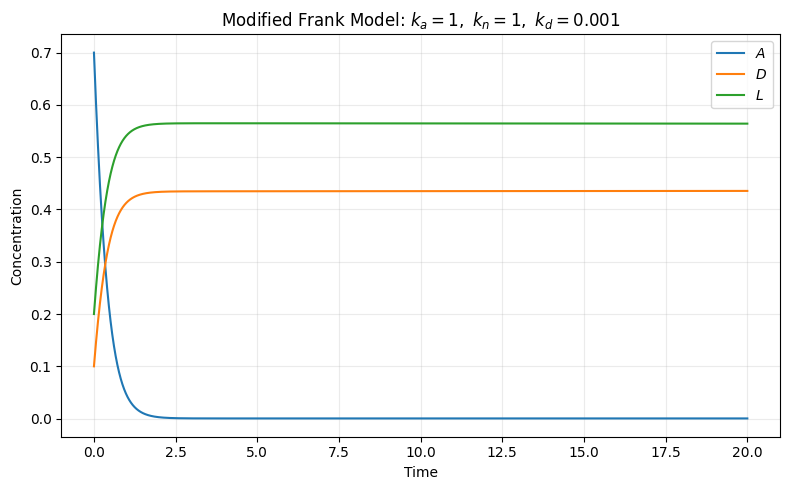

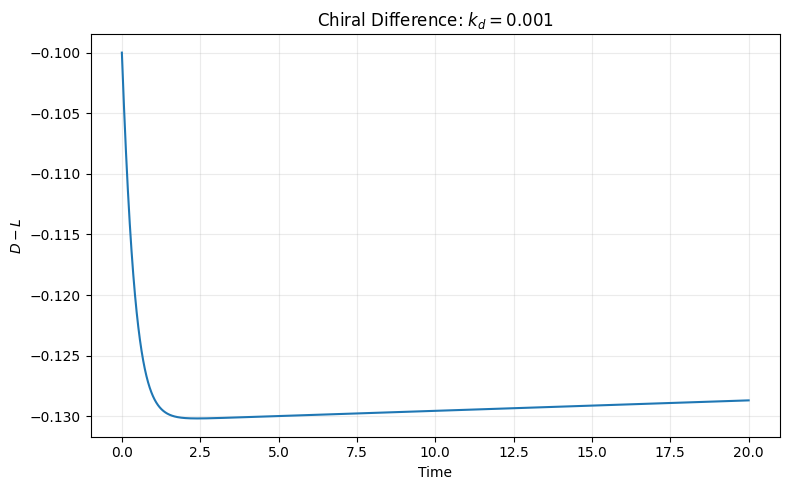

Initial total: 1.0
Final total: 1.0000000000000007
Maximum conservation error: 8.881784197001252e-16


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# Parameters
# ============================================================

ka = 1.0
kn = 1.0
kd = 0.001


# ============================================================
# Modified Frank model
# ============================================================

def modified_frank(t, y):

    A, D, L = y

    dA = kd*(D + L) - 2*kn*A - ka*A*(D + L)

    dD = ka*A*D + kn*A - kd*D

    dL = ka*A*L + kn*A - kd*L

    return [dA, dD, dL]


# ============================================================
# Initial conditions
# ============================================================

A0 = 0.70
D0 = 0.10
L0 = 0.20

y0 = [A0, D0, L0]


# ============================================================
# Time interval
# ============================================================

t_start = 0
t_end = 20

t_eval = np.linspace(t_start, t_end, 5000)


# ============================================================
# Solve ODE
# ============================================================

solution = solve_ivp(
    modified_frank,
    [t_start, t_end],
    y0,
    t_eval=t_eval,
    method="RK45",
    rtol=1e-9,
    atol=1e-11
)


# Extract solutions

t = solution.t

A = solution.y[0]
D = solution.y[1]
L = solution.y[2]


# ============================================================
# Plot concentrations
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(t, A, label=r"$A$")
plt.plot(t, D, label=r"$D$")
plt.plot(t, L, label=r"$L$")

plt.xlabel("Time")
plt.ylabel("Concentration")

plt.title(
    r"Modified Frank Model: $k_a=1,\ k_n=1,\ k_d=0.001$"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# Plot chiral difference
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(t, D - L)

plt.xlabel("Time")
plt.ylabel(r"$D-L$")

plt.title(
    r"Chiral Difference: $k_d=0.001$"
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# Conservation check
# ============================================================

total = A + D + L

print("Initial total:", total[0])
print("Final total:", total[-1])
print("Maximum conservation error:",
      np.max(np.abs(total - 1)))

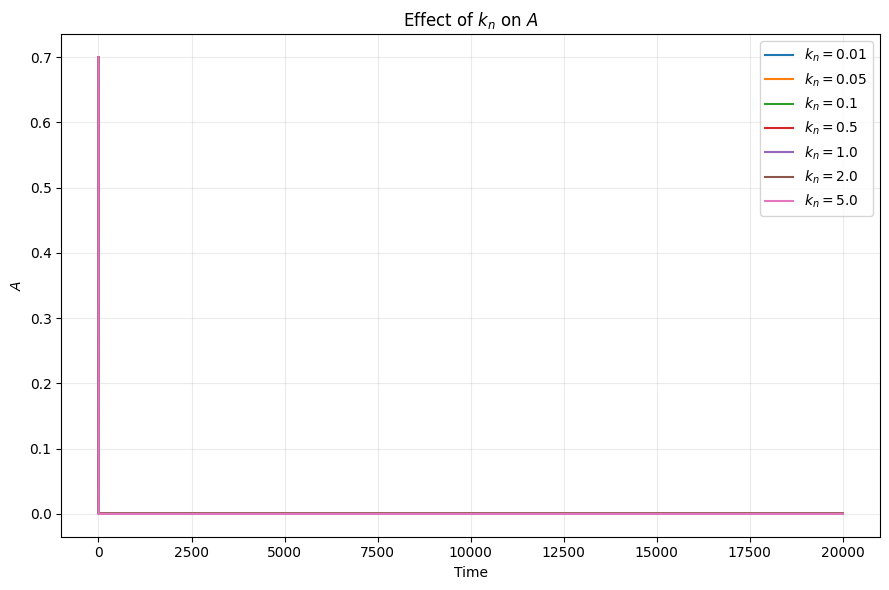

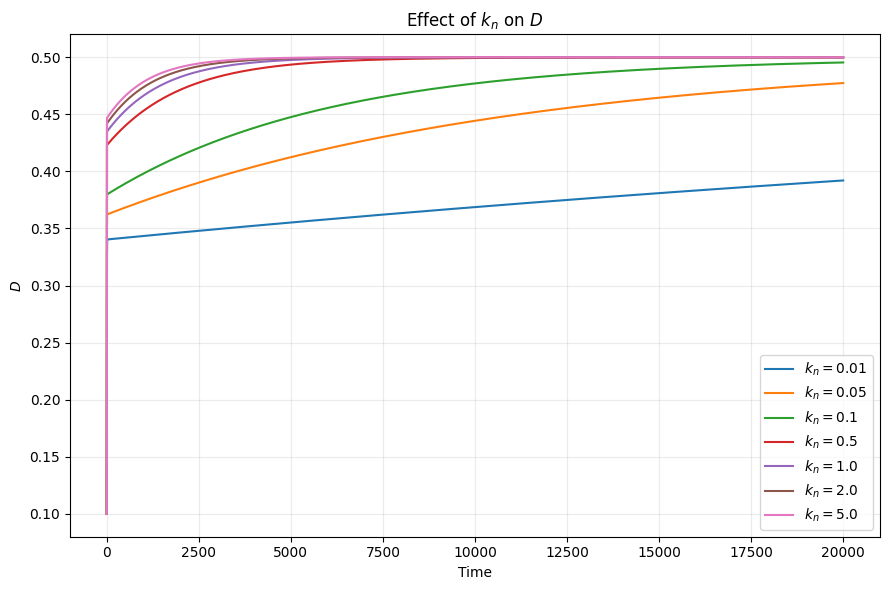

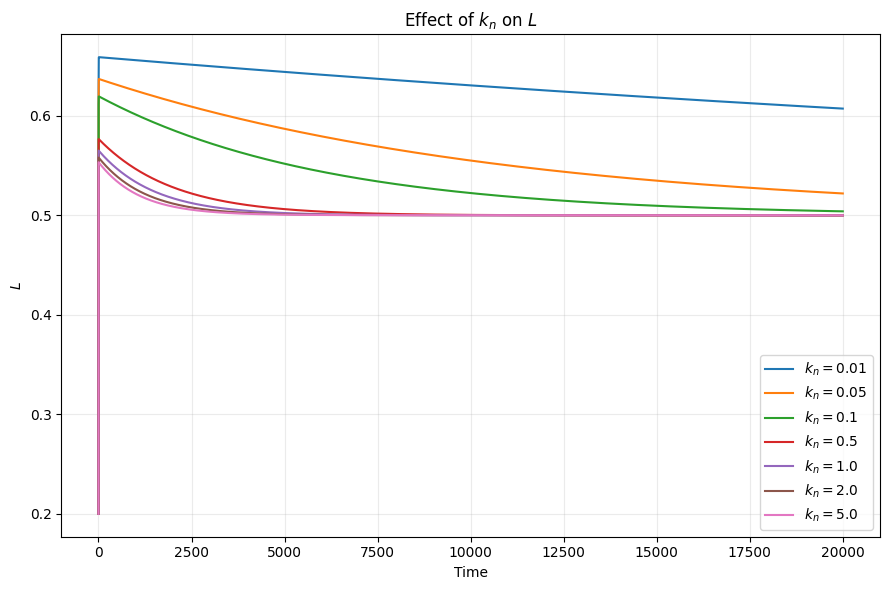

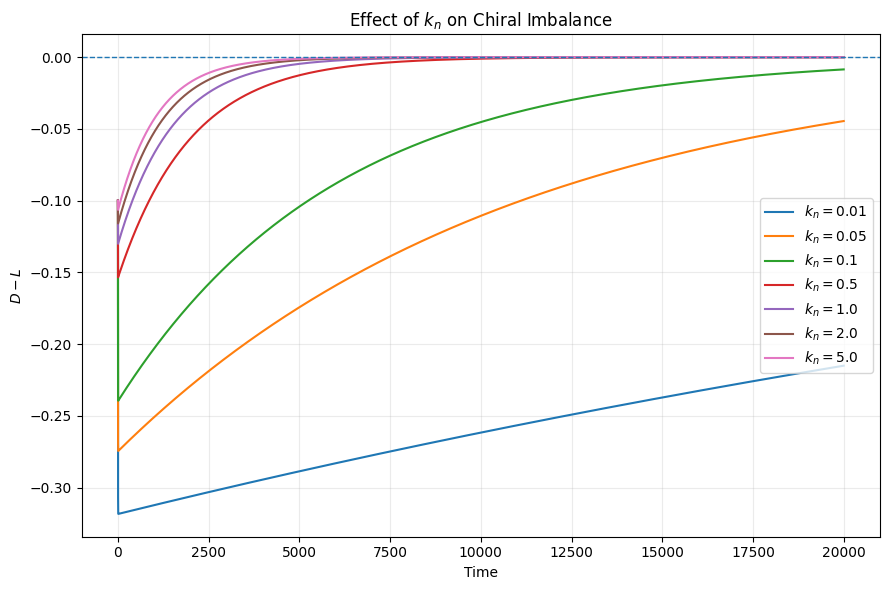

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# Parameters
# ============================================================

ka = 1.0
kd = 0.001

kn_values = [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]


# ============================================================
# Modified Frank model
# ============================================================

def modified_frank(t, y, kn):

    A, D, L = y

    dA = kd*(D + L) - 2*kn*A - ka*A*(D + L)

    dD = ka*A*D + kn*A - kd*D

    dL = ka*A*L + kn*A - kd*L

    return [dA, dD, dL]


# ============================================================
# Initial conditions
# ============================================================

y0 = [0.70, 0.10, 0.20]


# ============================================================
# Time
# ============================================================

t_start = 0
t_end = 20000

t_eval = np.linspace(t_start, t_end, 5000)


# ============================================================
# Storage
# ============================================================

results = {}


# ============================================================
# Run simulations
# ============================================================

for kn in kn_values:

    sol = solve_ivp(
        lambda t, y: modified_frank(t, y, kn),
        [t_start, t_end],
        y0,
        t_eval=t_eval,
        method="RK45",
        rtol=1e-9,
        atol=1e-11
    )

    results[kn] = sol


# ============================================================
# Plot A
# ============================================================

plt.figure(figsize=(9, 6))

for kn in kn_values:

    sol = results[kn]

    plt.plot(
        sol.t,
        sol.y[0],
        label=rf"$k_n={kn}$"
    )

plt.xlabel("Time")
plt.ylabel(r"$A$")
plt.title(r"Effect of $k_n$ on $A$")
plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# Plot D
# ============================================================

plt.figure(figsize=(9, 6))

for kn in kn_values:

    sol = results[kn]

    plt.plot(
        sol.t,
        sol.y[1],
        label=rf"$k_n={kn}$"
    )

plt.xlabel("Time")
plt.ylabel(r"$D$")
plt.title(r"Effect of $k_n$ on $D$")
plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# Plot L
# ============================================================

plt.figure(figsize=(9, 6))

for kn in kn_values:

    sol = results[kn]

    plt.plot(
        sol.t,
        sol.y[2],
        label=rf"$k_n={kn}$"
    )

plt.xlabel("Time")
plt.ylabel(r"$L$")
plt.title(r"Effect of $k_n$ on $L$")
plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# Plot D-L
# ============================================================

plt.figure(figsize=(9, 6))

for kn in kn_values:

    sol = results[kn]

    plt.plot(
        sol.t,
        sol.y[1] - sol.y[2],
        label=rf"$k_n={kn}$"
    )

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Time")
plt.ylabel(r"$D-L$")
plt.title(r"Effect of $k_n$ on Chiral Imbalance")
plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

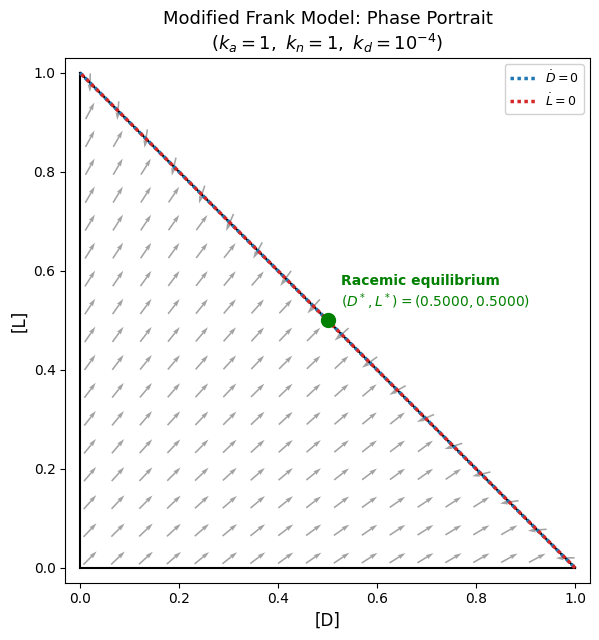

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------
# Vector field — Case 2
# ka = 1, kn = 1, kd = 0.0001, N = 1
# ---------------------------------

def dD(D, L):
    return 1 - 0.0001*D - L - D**2 - D*L

def dL(D, L):
    return 1 - D - 0.0001*L - D*L - L**2


fig, ax = plt.subplots(figsize=(6.5, 6.5))


# ---------------------------------
# Vector field
# ---------------------------------

n = 18

Dg = np.linspace(0.02, 0.98, n)
Lg = np.linspace(0.02, 0.98, n)

DD, LL = np.meshgrid(Dg, Lg)

# Physical region
mask = (DD + LL) <= 1.0

U = dD(DD, LL)
V = dL(DD, LL)

speed = np.sqrt(U**2 + V**2)
speed[speed == 0] = 1

Un = np.where(mask, U / speed, np.nan)
Vn = np.where(mask, V / speed, np.nan)

ax.quiver(
    DD,
    LL,
    Un,
    Vn,
    color='0.55',
    pivot='mid',
    scale=28,
    width=0.003,
    alpha=0.8
)


# ---------------------------------
# Simplex
# ---------------------------------

ax.plot([0, 1], [0, 0], 'k-', linewidth=1.5)
ax.plot([0, 0], [0, 1], 'k-', linewidth=1.5)
ax.plot([0, 1], [1, 0], 'k-', linewidth=1.5)


# ---------------------------------
# Nullclines
# ---------------------------------

x = np.linspace(0, 1, 500)

kd = 0.0001

# D-nullcline
L_D = (1 - kd*x - x**2) / (1 + x)

mask_D = (L_D >= 0) & ((x + L_D) <= 1)

ax.plot(
    x[mask_D],
    L_D[mask_D],
    color='#1f77b4',
    linewidth=2.5,
    linestyle=(0, (1, 1)),
    label=r'$\dot D=0$'
)


# L-nullcline
D_L = (1 - kd*x - x**2) / (1 + x)

mask_L = (D_L >= 0) & ((x + D_L) <= 1)

ax.plot(
    D_L[mask_L],
    x[mask_L],
    color='#d62728',
    linewidth=2.5,
    linestyle=(0, (1, 1)),
    label=r'$\dot L=0$'
)


# ---------------------------------
# Equilibrium
# ---------------------------------

# D = L = x
# 1 - (1 + kd)x - 2x^2 = 0

D_eq = (-(1 + kd) + np.sqrt((1 + kd)**2 + 8)) / 4
L_eq = D_eq

ax.plot(
    D_eq,
    L_eq,
    'o',
    color='green',
    markersize=10,
    zorder=5
)

ax.annotate(
    r'Racemic equilibrium'
    '\n'
    rf'$(D^*,L^*)=({D_eq:.4f},{L_eq:.4f})$',
    (D_eq, L_eq),
    textcoords='offset points',
    xytext=(10, 10),
    fontsize=10,
    color='green',
    fontweight='bold'
)


# ---------------------------------
# Plot settings
# ---------------------------------

ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)

ax.set_xlabel('[D]', fontsize=12)
ax.set_ylabel('[L]', fontsize=12)

ax.set_title(
    r"Modified Frank Model: Phase Portrait"
    "\n"
    r"$(k_a=1,\ k_n=1,\ k_d=10^{-4})$",
    fontsize=13
)

ax.set_aspect('equal')

ax.legend(
    loc='upper right',
    fontsize=9,
    framealpha=0.9
)

plt.tight_layout()
plt.show()


## Derivation of the Eigenvectors

At the racemic equilibrium, the Jacobian matrix is

$$
J^*=
\begin{pmatrix}
a & c\\
c & a
\end{pmatrix}
$$

where

$$
a=k_a(A^*-x)-k_n-k_d
$$

$$
c=-k_ax-k_n
$$

An eigenvector $v$ corresponding to an eigenvalue $\lambda$ satisfies

$$
J^*v=\lambda v
$$

Let

$$
v=
\begin{pmatrix}
v_D\\
v_L
\end{pmatrix}
$$

Then,

$$
\begin{pmatrix}
a & c\\
c & a
\end{pmatrix}
\begin{pmatrix}
v_D\\
v_L
\end{pmatrix}
=
\lambda
\begin{pmatrix}
v_D\\
v_L
\end{pmatrix}
$$

This gives the simultaneous equations

$$
(a-\lambda)v_D+cv_L=0
$$

$$
cv_D+(a-\lambda)v_L=0
$$

### 1. Symmetric Eigenvector

The first eigenvalue is

$$
\lambda_{\mathrm{sym}}=a+c
$$

Substituting into the first equation,

$$
(a-a-c)v_D+cv_L=0
$$

Simplifying,

$$
-cv_D+cv_L=0
$$

For $c\neq 0$,

$$
v_D=v_L
$$

Therefore, choosing $v_D=1$ gives

$$
\boxed{
v_{\mathrm{sym}}=
\begin{pmatrix}
1\\
1
\end{pmatrix}
}
$$

Both D and L change in the same direction. This mode describes symmetric perturbations of the total chiral concentration.

### 2. Antisymmetric Eigenvector

The second eigenvalue is

$$
\lambda_{\Delta}=a-c
$$

Substituting into the first equation,

$$
(a-a+c)v_D+cv_L=0
$$

Simplifying,

$$
cv_D+cv_L=0
$$

For $c\neq 0$,

$$
v_D=-v_L
$$

Therefore, choosing $v_D=1$ gives

$$
\boxed{
v_{\Delta}=
\begin{pmatrix}
1\\
-1
\end{pmatrix}
}
$$

D and L change in opposite directions. This mode describes perturbations in the chiral imbalance.

### 3. Physical Interpretation

The symmetric perturbation is

$$
D=x+\epsilon,\qquad L=x+\epsilon
$$

Thus,

$$
D+L=2x+2\epsilon
$$

while the difference remains unchanged.

The antisymmetric perturbation is

$$
D=x+\epsilon,\qquad L=x-\epsilon
$$

Thus,

$$
D+L=2x
$$

while

$$
D-L=2\epsilon
$$

Therefore, the eigenvectors separate the dynamics into two independent modes: one describing changes in total chiral concentration and the other describing changes in chiral imbalance.

## Symmetric and Antisymmetric Modes

At the racemic equilibrium, the Jacobian is

$$
J^*=
\begin{pmatrix}
a & c\\
c & a
\end{pmatrix}
$$

The eigenvectors classify perturbations into two independent modes.

### 1. Symmetric Mode

The eigenvector is

$$
v_{\mathrm{sym}}=
\begin{pmatrix}
1\\
1
\end{pmatrix}
$$

The corresponding eigenvalue is

$$
\boxed{
\lambda_{\mathrm{sym}}
=k_a(N-4x)-2k_n-k_d
}
$$

Here, D and L change in the same direction:

$$
D=x+\epsilon,\qquad L=x+\epsilon
$$

Therefore, the total chiral concentration changes, while the chiral imbalance remains zero.

### 2. Antisymmetric Mode

The eigenvector is

$$
v_{\Delta}=
\begin{pmatrix}
1\\
-1
\end{pmatrix}
$$

The corresponding eigenvalue is

$$
\boxed{
\lambda_{\Delta}=k_a(N-2x)-k_d
}
$$

Here, D and L change in opposite directions:

$$
D=x+\epsilon,\qquad L=x-\epsilon
$$

Therefore, the total chiral concentration remains unchanged, while the chiral imbalance changes.

## Relaxation Time

Near equilibrium, a small perturbation associated with an eigenvalue
$\lambda$ evolves as

$$
\delta(t)=\delta(0)e^{\lambda t}
$$

For a negative eigenvalue, the characteristic relaxation time is

$$
\boxed{\tau=\frac{1}{|\lambda|}}
$$

Hence, the relaxation times of the two modes are

$$
\boxed{
\tau_{\mathrm{sym}}=\frac{1}{|\lambda_{\mathrm{sym}}|}
}
$$

$$
\boxed{
\tau_{\Delta}=\frac{1}{|\lambda_{\Delta}|}
}
$$

A smaller absolute eigenvalue corresponds to a longer relaxation time.

Since both eigenvalues are negative for the physical racemic equilibrium,
both modes are stable. The antisymmetric mode can have a much longer
relaxation time, explaining the slow decay of chiral imbalance.